In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
%matplotlib inline

In [58]:
df = pd.read_csv('train_combined.csv')

In [74]:
df_test = pd.read_csv('test_combined.csv')

In [4]:
xls = pd.ExcelFile('Data_Dictionary.xlsx')
df1 = pd.read_excel(xls, 'Dictionary')
df2 = pd.read_excel(xls, 'Instrument_Description')
df3 = pd.read_excel(xls, 'EHQ')
df4 = pd.read_excel(xls, 'APQ')
df5 = pd.read_excel(xls, 'SDQ')

In [5]:
df1

,DataType,Instrument,Field,Description,Type,Labels
0,QUANTITATIVE METADATA,NaN,NaN,NaN,NaN,NaN
1,NaN,Identifier,participant_id,Participant ID,str,NaN
2,Quantitative,Edinburgh Handedness Questionnaire,EHQ_EHQ_Total,Laterality Index (Score),float,-100 = 10th left\n−28 ≤ LI < 48 = middle\n100 ...
3,Quantitative,Ishihara Color Vision Test,ColorVision_CV_Score,Color vision test score,int,NaN
4,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_CP,Corporal Punishment Score,int,NaN
5,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_ID,Inconsistent Discipline Score,int,NaN
6,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_INV,Involvement Score,int,NaN
7,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_OPD,Other Discipline Practices Score (Not factored...,int,NaN
8,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_PM,Poor Monitoring/Supervision Score,int,NaN
9,Quantitative,Alabama Parenting Questionnaire - Parent Report,APQ_P_APQ_P_PP,Positive Parenting Score,int,NaN


- **ADHD_Outcome** - Диагноз СДВГ
    1=да
    0=нет
- **Sex_F** - Пол ребенка
    1=девочка
    0=мальчик
- **Демография**
- **Basic_Demos_Enroll_Year** - Год включения в исследование
- **Basic_Demos_Study_Site** - Место фенотипического тестирования

- **PreInt_Demos_Fam_Child_Ethnicity** - Этническая принадлежность ребенка
- **PreInt_Demos_Fam_Child_Race** - Раса ребенка
- **Barratt_Barratt_P1_Edu** - Образование первого родителя
- **Barratt_Barratt_P1_Occ** - Профессия первого родителя
- **Barratt_Barratt_P2_Edu** - Образование второго родителя
- **Barratt_Barratt_P2_Occ** - Профессия второго родителя
- **MRI**
- **MRI_Track_Scan_Location** - Локация сканирования МРТ
- **MRI_Track_Age_at_Scan** - Возраст ребенка на момент МРТ
- **SDQ (Поведенческие опросники)**
- **SDQ_SDQ_Conduct_Problems** - Проблемы с поведением
- **SDQ_SDQ_Difficulties_Total** - Общая сложность (итоговая оценка)
- **SDQ_SDQ_Emotional_Problems** - Эмоциональные проблемы
- **SDQ_SDQ_Externalizing** - Внешне проявляемые проблемы
- **SDQ_SDQ_Internalizing** - Внутреннее проявления (тревожность, депрессия)
- **SDQ_SDQ_Hyperactivity** - Гиперактивность
- **SDQ_SDQ_Peer_Problems** - Проблемы в общении
- **SDQ_SDQ_Prosocial** - Просоциальное поведение
- **SDQ_SDQ_Generating_Impact** - Насколько проблемы влияют на жизнь
- **APQ (Опросник академической успеваимости)** 
- **APQ_P_APQ_P_CP** - Последовательность наказаний
- **APQ_P_APQ_P_ID** - Недостаток надзора
- **APQ_P_APQ_P_INV** - Вовлеченность родителей
- **APQ_P_APQ_P_OPD** - Позитивное воспитание
- **APQ_P_APQ_P_PM** - Негативное воспитание
- **APQ_P_APQ_P_PP** - Положительное подкрепление
- **Прочее**
- **EHQ_EHQ_Total** - Опросник по пищевым привычкам
- **ColorVision_CV_Score** - Результаты теста цветоразличения

In [6]:
df.head(10)

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan,ADHD_Outcome,Sex_F
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,NaN,NaN,...,4.0,11.0,5.0,8.0,6.0,2.0,9.0,14.274127,1,0
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0,...,4.0,13.0,5.0,8.0,7.0,3.0,8.0,NaN,1,0
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,NaN,NaN,...,7.0,10.0,10.0,7.0,14.0,7.0,7.0,13.463381,0,1
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0,...,0.0,3.0,0.0,3.0,2.0,2.0,6.0,9.572553,0,1
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,NaN,NaN,...,7.0,15.0,8.0,9.0,8.0,1.0,4.0,6.654574,1,0
5,0cduHhwrQN4r,2017,1,0.0,0.0,2.0,18.0,25.0,15.0,40.0,...,1.0,16.0,5.0,10.0,6.0,5.0,6.0,NaN,1,0
6,0FUWCjn9YMN1,2017,1,0.0,1.0,2.0,15.0,0.0,15.0,30.0,...,1.0,6.0,0.0,5.0,2.0,1.0,7.0,12.885580,1,0
7,0Hthz5IFXhpw,2016,2,0.0,1.0,1.0,12.0,35.0,18.0,40.0,...,3.0,8.0,5.0,6.0,7.0,4.0,5.0,NaN,1,1
8,0hzWGU6XYSVp,2019,3,0.0,0.0,3.0,21.0,45.0,21.0,45.0,...,6.0,5.0,4.0,3.0,13.0,7.0,6.0,12.486196,1,0
9,0i2Tz2XUL4vm,2019,1,0.0,0.0,2.0,15.0,NaN,9.0,NaN,...,4.0,11.0,4.0,8.0,4.0,0.0,8.0,9.715491,1,1


In [7]:
df.describe(include='all')

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan,ADHD_Outcome,Sex_F
count,1213,1213.000000,1213.000000,1170.000000,1159.000000,1210.000000,1198.000000,1182.000000,1015.000000,991.000000,...,1204.000000,1204.000000,1204.000000,1204.000000,1204.000000,1204.000000,1204.000000,853.000000,1213.000000,1213.000000
unique,1213,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,00aIpNTbG5uh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2017.652102,2.014839,0.435897,2.177739,2.294215,17.862270,25.545685,16.876847,30.257316,...,2.324751,7.613787,4.103821,5.539037,4.599668,2.274917,7.740864,11.245678,0.685078,0.342951
std,NaN,1.122522,1.135147,0.693174,3.204782,0.750660,3.505608,16.757043,3.929558,13.901144,...,2.166399,4.130399,2.808079,2.807063,3.510469,2.089041,2.094832,3.234372,0.464676,0.474891
min,NaN,2015.000000,1.000000,0.000000,0.000000,1.000000,3.000000,0.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,2017.000000,1.000000,0.000000,0.000000,2.000000,15.000000,5.000000,15.000000,20.000000,...,1.000000,5.000000,2.000000,4.000000,2.000000,0.000000,6.000000,8.803901,0.000000,0.000000
50%,NaN,2018.000000,1.000000,0.000000,1.000000,2.000000,18.000000,30.000000,18.000000,35.000000,...,2.000000,8.000000,4.000000,6.000000,4.000000,2.000000,8.000000,10.739219,1.000000,0.000000
75%,NaN,2019.000000,3.000000,1.000000,2.000000,3.000000,21.000000,40.000000,21.000000,40.000000,...,4.000000,10.000000,6.000000,8.000000,7.000000,4.000000,10.000000,13.460871,1.000000,1.000000


In [59]:
df['Sex_F'] = df['Sex_F'].astype(str)

In [84]:
df.columns

Index(['participant_id', 'Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan', 'ADHD_Outcome', 'Sex_F', 'One_parent'],
      dtype='object')

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1177 entries, 0 to 1212
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   participant_id                    1177 non-null   object 
 1   Basic_Demos_Enroll_Year           1177 non-null   int64  
 2   Basic_Demos_Study_Site            1177 non-null   int64  
 3   PreInt_Demos_Fam_Child_Ethnicity  1137 non-null   float64
 4   PreInt_Demos_Fam_Child_Race       1127 non-null   float64
 5   MRI_Track_Scan_Location           1177 non-null   float64
 6   Barratt_Barratt_P1_Edu            1162 non-null   float64
 7   Barratt_Barratt_P1_Occ            1147 non-null   float64
 8   Barratt_Barratt_P2_Edu            989 non-null    float64
 9   Barratt_Barratt_P2_Occ            965 non-null    float64
 10  EHQ_EHQ_Total                     1177 non-null   float64
 11  ColorVision_CV_Score              1156 non-null   float64
 12  APQ_P_APQ_P

In [9]:
#Количество пропусков
df.isna().sum()

Basic_Demos_Enroll_Year               0
Basic_Demos_Study_Site                0
PreInt_Demos_Fam_Child_Ethnicity     43
PreInt_Demos_Fam_Child_Race          54
MRI_Track_Scan_Location               3
Barratt_Barratt_P1_Edu               15
Barratt_Barratt_P1_Occ               31
Barratt_Barratt_P2_Edu              198
Barratt_Barratt_P2_Occ              222
EHQ_EHQ_Total                        13
ColorVision_CV_Score                 23
APQ_P_APQ_P_CP                       12
APQ_P_APQ_P_ID                       12
APQ_P_APQ_P_INV                      12
APQ_P_APQ_P_OPD                      12
APQ_P_APQ_P_PM                       12
APQ_P_APQ_P_PP                       12
SDQ_SDQ_Conduct_Problems              9
SDQ_SDQ_Difficulties_Total            9
SDQ_SDQ_Emotional_Problems            9
SDQ_SDQ_Externalizing                 9
SDQ_SDQ_Generating_Impact             9
SDQ_SDQ_Hyperactivity                 9
SDQ_SDQ_Internalizing                 9
SDQ_SDQ_Peer_Problems                 9


In [10]:
#Сколько в процентах пропусков
df.isna().sum()/len(df)*100

Basic_Demos_Enroll_Year              0.000000
Basic_Demos_Study_Site               0.000000
PreInt_Demos_Fam_Child_Ethnicity     3.544930
PreInt_Demos_Fam_Child_Race          4.451772
MRI_Track_Scan_Location              0.247321
Barratt_Barratt_P1_Edu               1.236603
Barratt_Barratt_P1_Occ               2.555647
Barratt_Barratt_P2_Edu              16.323166
Barratt_Barratt_P2_Occ              18.301731
EHQ_EHQ_Total                        1.071723
ColorVision_CV_Score                 1.896125
APQ_P_APQ_P_CP                       0.989283
APQ_P_APQ_P_ID                       0.989283
APQ_P_APQ_P_INV                      0.989283
APQ_P_APQ_P_OPD                      0.989283
APQ_P_APQ_P_PM                       0.989283
APQ_P_APQ_P_PP                       0.989283
SDQ_SDQ_Conduct_Problems             0.741962
SDQ_SDQ_Difficulties_Total           0.741962
SDQ_SDQ_Emotional_Problems           0.741962
SDQ_SDQ_Externalizing                0.741962
SDQ_SDQ_Generating_Impact         

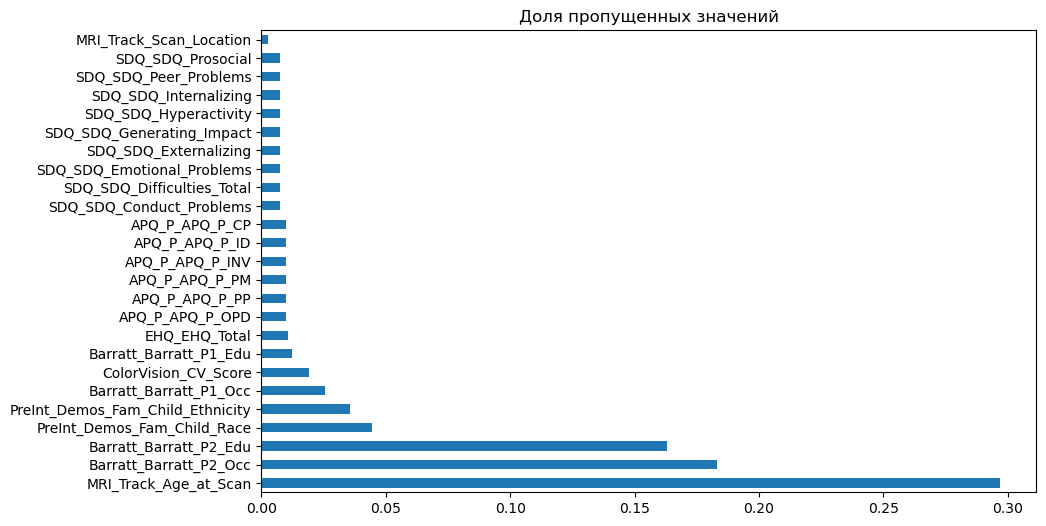

In [11]:
# Проверка пропущенных значений
missing = df.isnull().mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
missing[missing > 0].plot.barh()
plt.title('Доля пропущенных значений')
plt.show()

In [12]:
import missingno as msno

ValueError: could not convert string to float: '--'

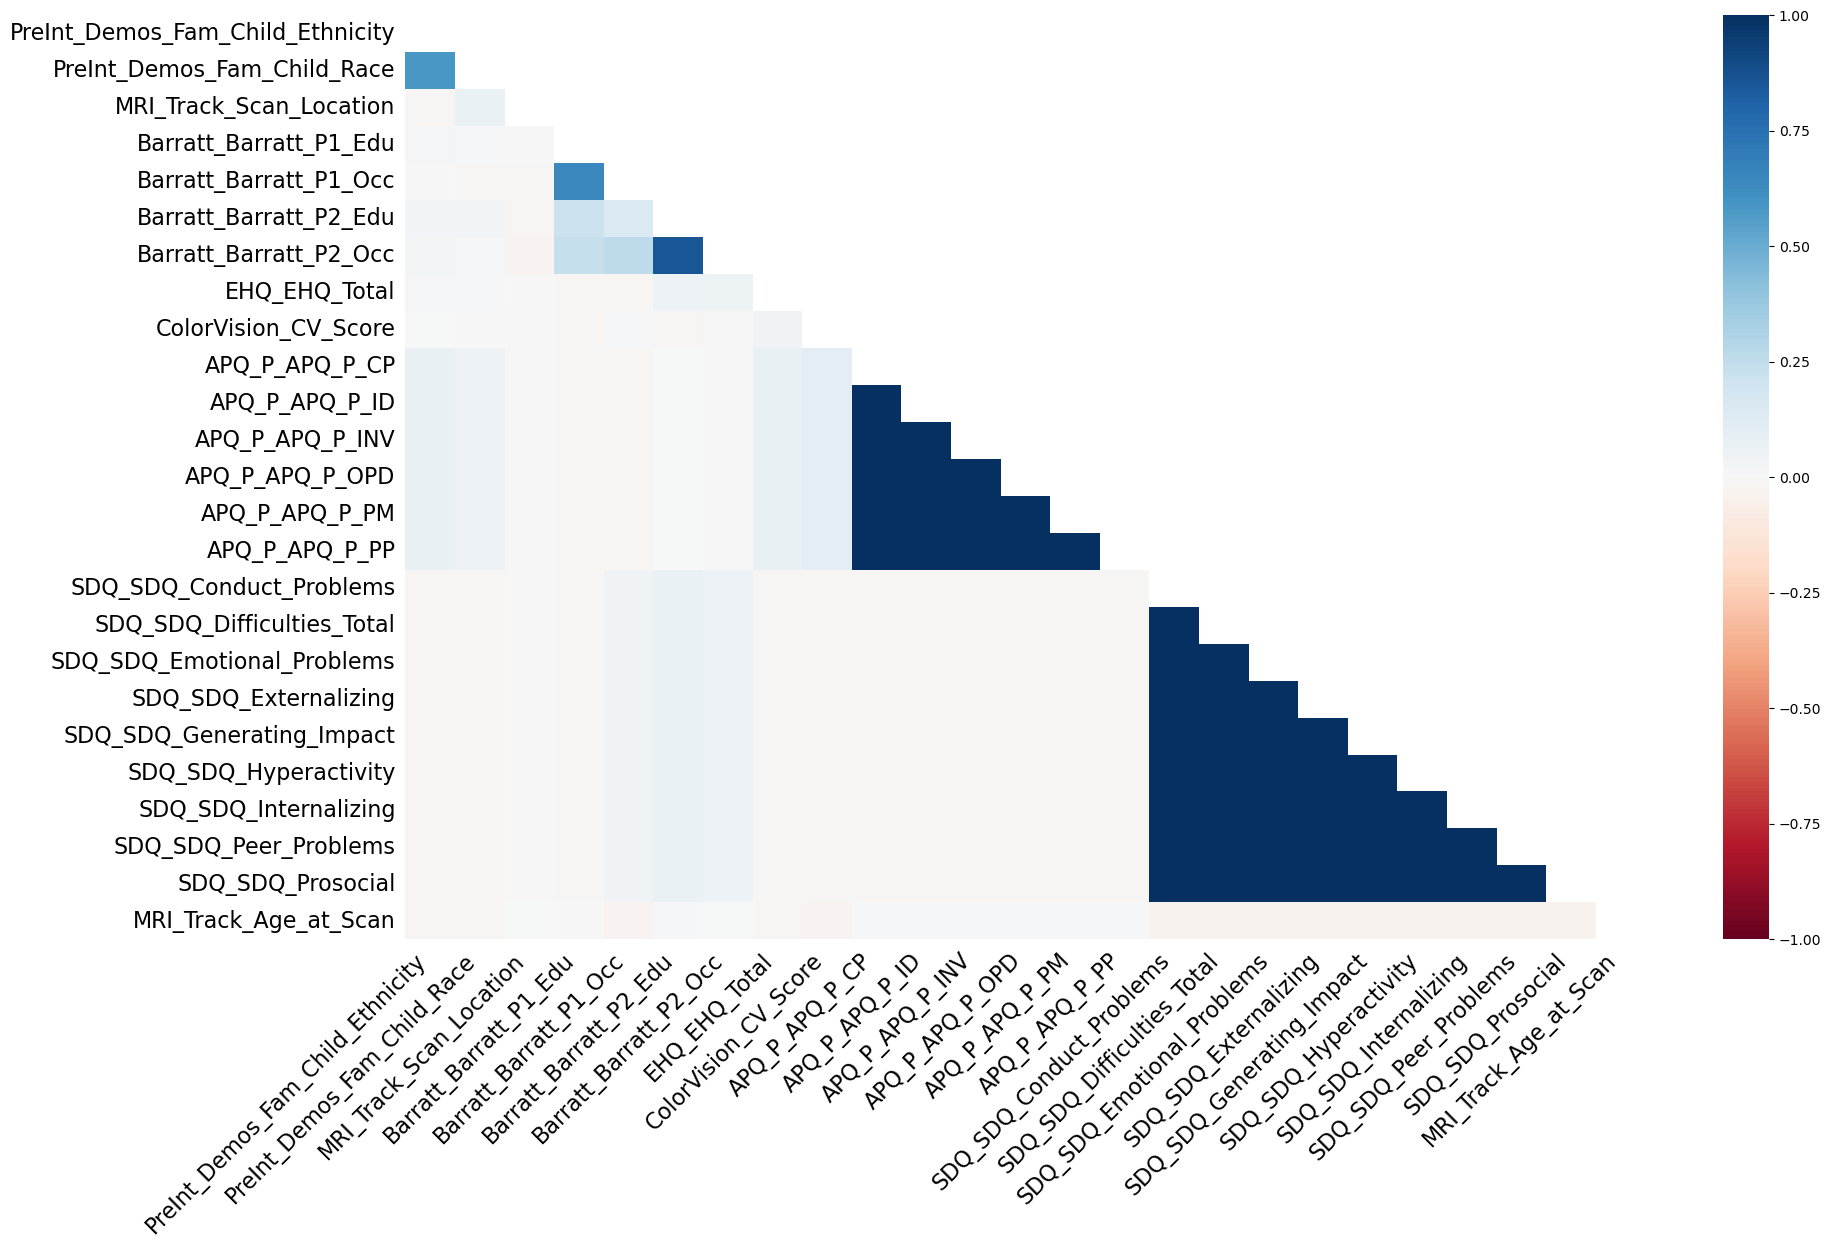

In [15]:
#Матрица корреляций пропущенных значений
msno.heatmap(df)

- Коррелирует отсутствие у ребенка расы и этноса в районе 0,5
- Коррелирует уровень образования и професии у первого и второго родителя
- Коррелируют все родительские отчеты
- Коррелируют отпросник сильных сторон и трудностей
  
Эти корреляции показывают, насколько сильно присутствие или отсутствие значений одного признака влияет на присутствие значений другого

In [60]:
#Удалим строчки, где немного пропущенных значений
df.dropna(axis = 'index', subset = ['MRI_Track_Scan_Location', 'APQ_P_APQ_P_CP', 'SDQ_SDQ_Conduct_Problems', 'EHQ_EHQ_Total'], inplace = True)

In [63]:
#Заполним пропуски
#для признаков PreInt_Demos_Fam_Child_Ethnicity = 3, PreInt_Demos_Fam_Child_Race = 10 соответствует значение unknow
#для признаков со значением -1, было выбрато значение несущестующее 
#для признака ColorVision_CV_Score была взята медиана
df.fillna({'PreInt_Demos_Fam_Child_Ethnicity' : 3,
           'PreInt_Demos_Fam_Child_Race': 10,
           'Barratt_Barratt_P1_Edu': -1,
           'Barratt_Barratt_P1_Occ': -1,
           'Barratt_Barratt_P2_Edu': -1,
           'Barratt_Barratt_P2_Occ': -1,
           'Barratt_Barratt_P2_Occ': -1,
           'MRI_Track_Age_at_Scan': -1,
           'ColorVision_CV_Score': 14
          }, inplace = True)

In [77]:
df_test.fillna({'PreInt_Demos_Fam_Child_Ethnicity' : 3,
           'PreInt_Demos_Fam_Child_Race': 10,
           'Barratt_Barratt_P1_Edu': -1,
           'Barratt_Barratt_P1_Occ': -1,
           'Barratt_Barratt_P2_Edu': -1,
           'Barratt_Barratt_P2_Occ': -1,
           'Barratt_Barratt_P2_Occ': -1,
           'MRI_Track_Age_at_Scan': -1,
           'ColorVision_CV_Score': 14
          }, inplace = True)

In [64]:
df.isna().sum()

participant_id                      0
Basic_Demos_Enroll_Year             0
Basic_Demos_Study_Site              0
PreInt_Demos_Fam_Child_Ethnicity    0
PreInt_Demos_Fam_Child_Race         0
MRI_Track_Scan_Location             0
Barratt_Barratt_P1_Edu              0
Barratt_Barratt_P1_Occ              0
Barratt_Barratt_P2_Edu              0
Barratt_Barratt_P2_Occ              0
EHQ_EHQ_Total                       0
ColorVision_CV_Score                0
APQ_P_APQ_P_CP                      0
APQ_P_APQ_P_ID                      0
APQ_P_APQ_P_INV                     0
APQ_P_APQ_P_OPD                     0
APQ_P_APQ_P_PM                      0
APQ_P_APQ_P_PP                      0
SDQ_SDQ_Conduct_Problems            0
SDQ_SDQ_Difficulties_Total          0
SDQ_SDQ_Emotional_Problems          0
SDQ_SDQ_Externalizing               0
SDQ_SDQ_Generating_Impact           0
SDQ_SDQ_Hyperactivity               0
SDQ_SDQ_Internalizing               0
SDQ_SDQ_Peer_Problems               0
SDQ_SDQ_Pros

In [16]:
#Основные описательные статистики для числовых признаков
df.iloc[:, 1:].describe()

,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,EHQ_EHQ_Total,ColorVision_CV_Score,...,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan,ADHD_Outcome
count,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,...,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000,1177.000000
mean,2.036534,0.519116,2.484282,2.313509,17.676296,25.050977,14.024639,24.662702,59.989431,13.431606,...,12.177570,2.319456,7.604078,4.101954,5.536958,4.573492,2.254036,7.740867,7.635037,0.687341
std,1.137423,0.824693,3.500238,0.740768,4.018417,17.019070,7.480149,17.374504,49.552051,2.090378,...,6.498292,2.151942,4.125116,2.796950,2.796171,3.498043,2.083512,2.093878,6.228055,0.463774
min,1.000000,0.000000,0.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-100.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,0.000000
25%,1.000000,0.000000,0.000000,2.000000,15.000000,0.000000,12.000000,5.000000,46.670000,14.000000,...,7.000000,1.000000,5.000000,2.000000,4.000000,2.000000,0.000000,6.000000,-1.000000,0.000000
50%,1.000000,0.000000,1.000000,2.000000,18.000000,30.000000,18.000000,30.000000,80.000000,14.000000,...,12.000000,2.000000,8.000000,4.000000,6.000000,4.000000,2.000000,8.000000,9.090805,1.000000
75%,3.000000,1.000000,3.000000,3.000000,21.000000,40.000000,21.000000,40.000000,94.470000,14.000000,...,17.000000,4.000000,10.000000,6.000000,8.000000,7.000000,4.000000,10.000000,11.993611,1.000000
max,4.000000,3.000000,11.000000,4.000000,21.000000,45.000000,21.000000,45.000000,100.000000,14.000000,...,34.000000,10.000000,20.000000,10.000000,10.000000,17.000000,9.000000,10.000000,21.564453,1.000000


In [17]:
df.ADHD_Outcome.value_counts(ascending=True)

ADHD_Outcome
0    368
1    809
Name: count, dtype: int64

In [18]:
df.Sex_F.value_counts(ascending=True)

Sex_F
1    401
0    776
Name: count, dtype: int64

## Гипотезы
1. Пол влияет на вероятность СДВГ
2. Определённые диагнозы в категориальных признаках сильно коррелируют с СДВГ у девочек
3. Образование родителей связанно с СДВГ у девочек
4. Родительская профессия связана с СДВГ у девочек
5. Склонность к трудностям в поведении коррелирует с СДВГ у девочек
6. Эмоционально/поведенческие подшкалы предсказывают СДВГ (SDQ) у девочек
7. Родительский стиль воспитания связан с СДВГ у девочек
8. Раса влиет на вероятность СДВГ у девочек
9. Гиперактивность больше связана с СДВГ у мальчиков, а у девочек по большей части СДВ
10. На СДВГ у девочек влияет количество родителей в семье


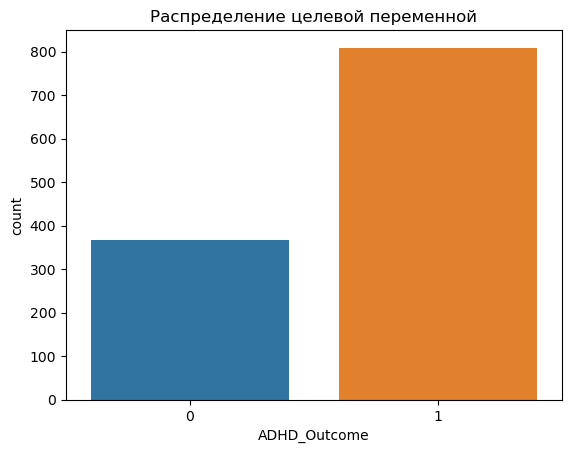

In [10]:
# Анаоиз целевой переменной
target_col = 'ADHD_Outcome' 
sns.countplot(x = target_col, data = df)
plt.title('Распределение целевой переменной')
plt.show()

- дисбаланс классов (с СДВГ детей больше, чем без) практически в два раза

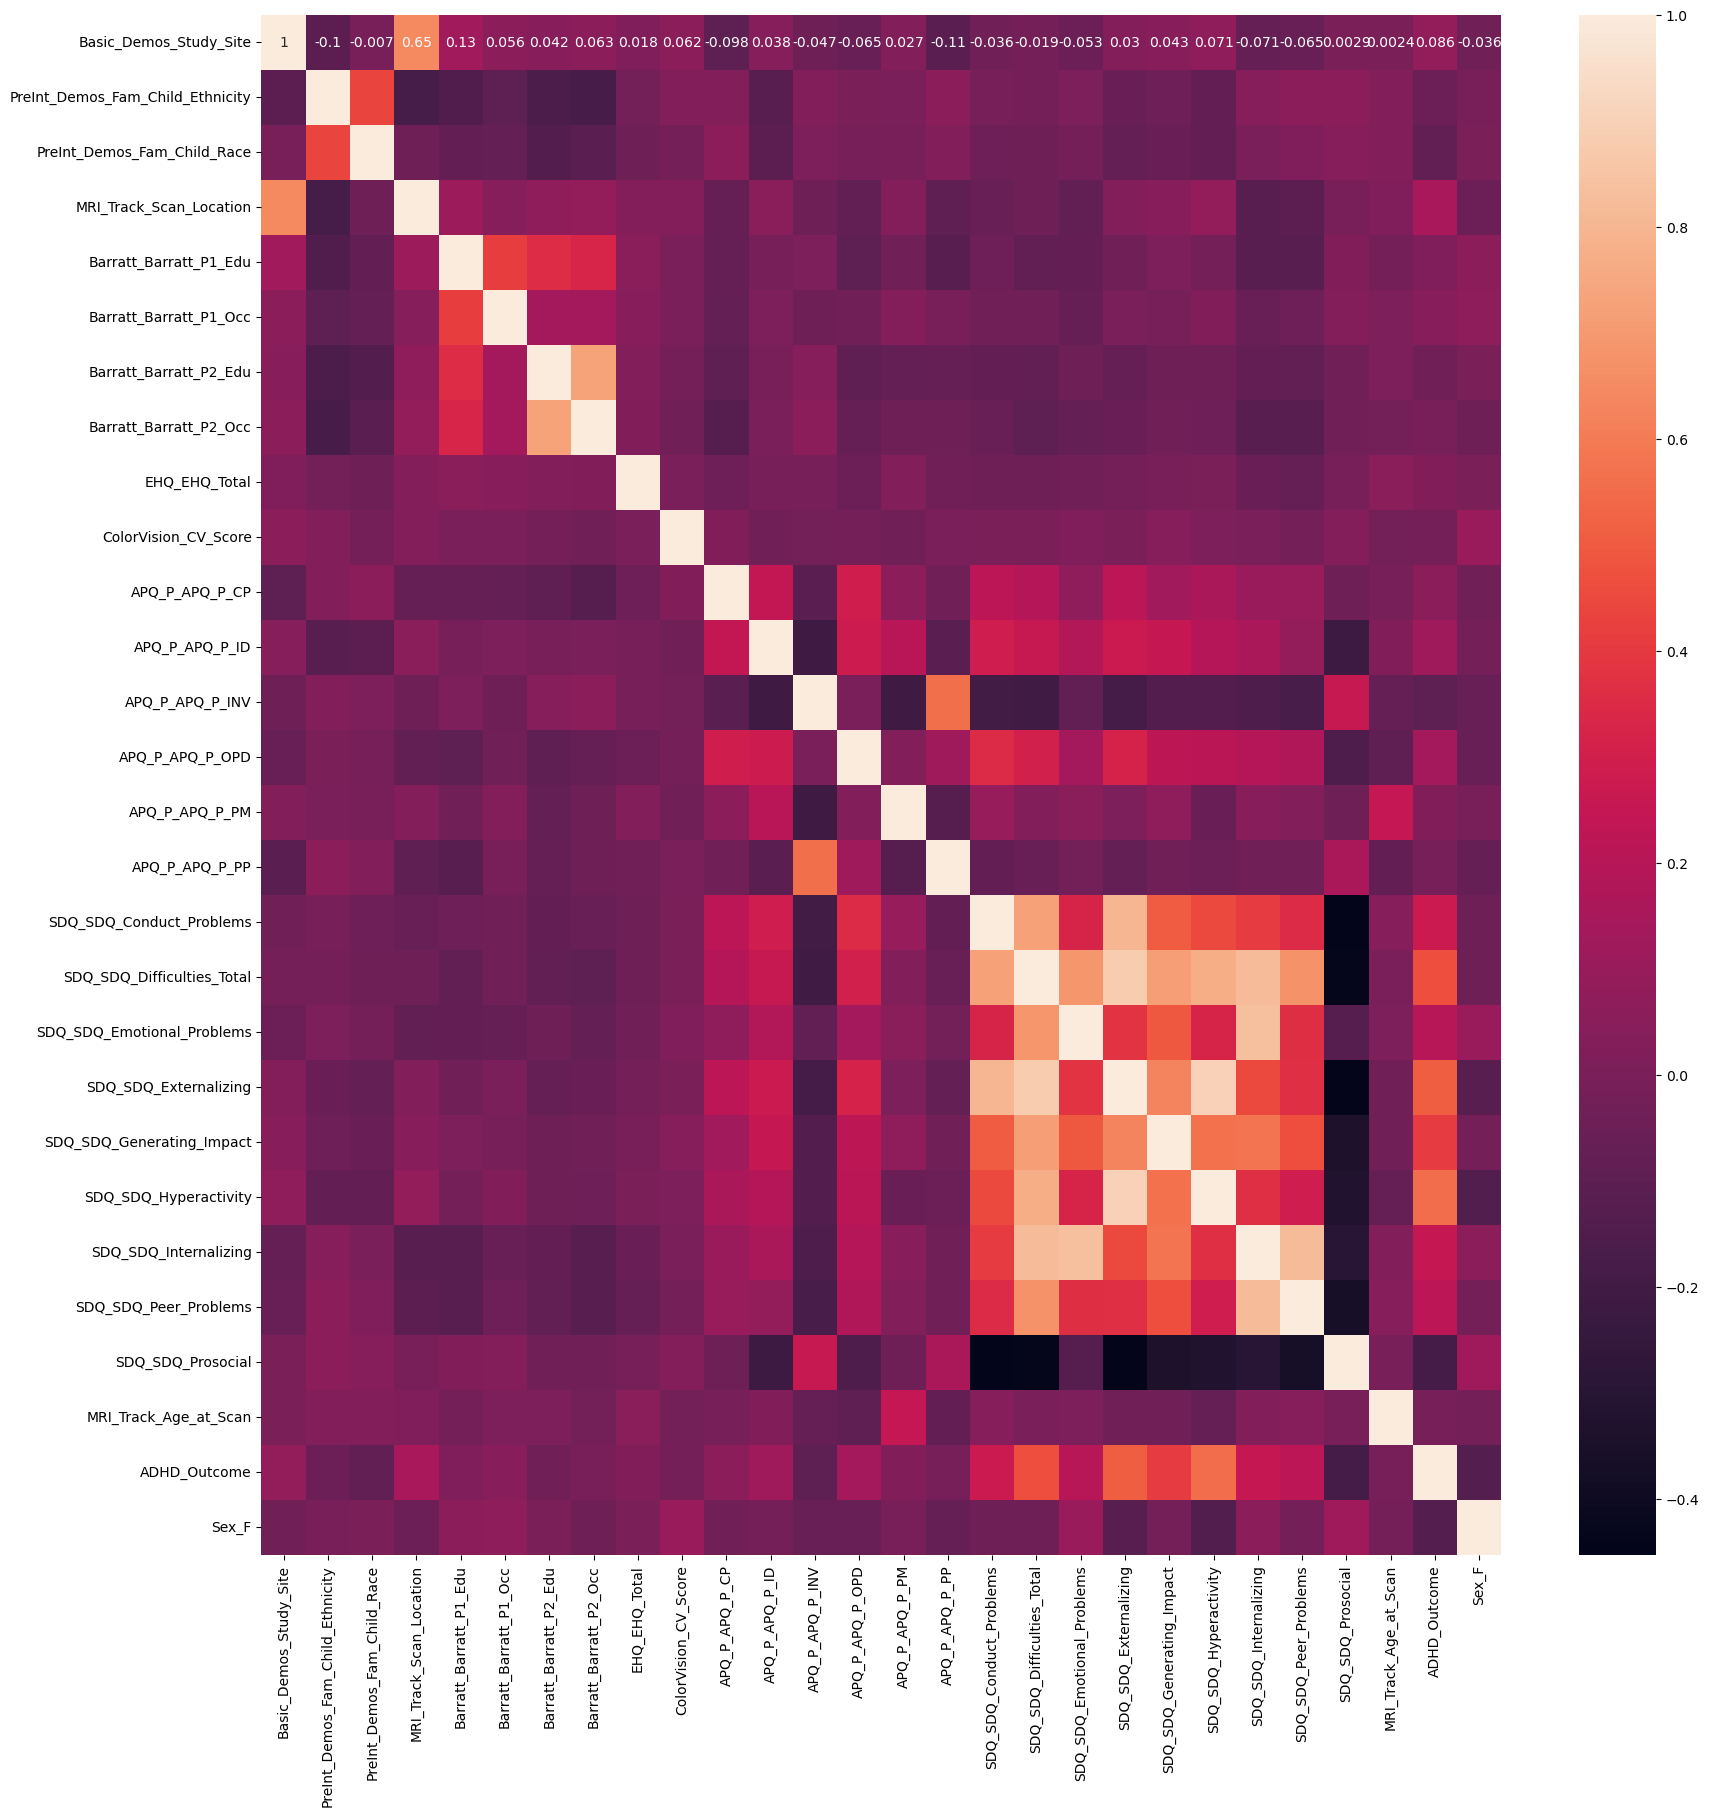

In [82]:
fig, axes = plt.subplots(nrows = 1, figsize=(20, 20))
sns.heatmap(df.iloc[:, 1:].corr(),
            annot=True)
plt.show()

In [12]:
quant_cols = df.select_dtypes(include=['number']).columns.drop(target_col)

In [13]:
def barplot_group(df_data: pd.DataFrame, col_main: str, col_group: str,
                  title: str) -> None:
    """
    Построение barplot с нормированными данными с выводом значений на графике
    """

    plt.figure(figsize=(15, 6))

    data = (df_data.groupby(
        [col_group])[col_main].value_counts(normalize=True).rename(
            'percentage').mul(100).reset_index().sort_values(col_group))

    ax = sns.barplot(x=col_main,
                     y="percentage",
                     hue=col_group,
                     data=data,
                     palette='rocket')

    for p in ax.patches:
        percentage = '{:.1f}%'.format(p.get_height())
        ax.annotate(
            percentage,  # текст
            (p.get_x() + p.get_width() / 2., p.get_height()),  # координата xy
            ha='center',  # центрирование
            va='center',
            xytext=(0, 7),
            textcoords='offset points',  # точка смещения относительно координаты
            fontsize=12)

## 1 Гипотеза

- Пол влияет на вероятность СДВГ

In [15]:
df["ADHD_Outcome"] = df["ADHD_Outcome"].astype(str) 
df["Sex_F"] = df["Sex_F"].astype(str) 

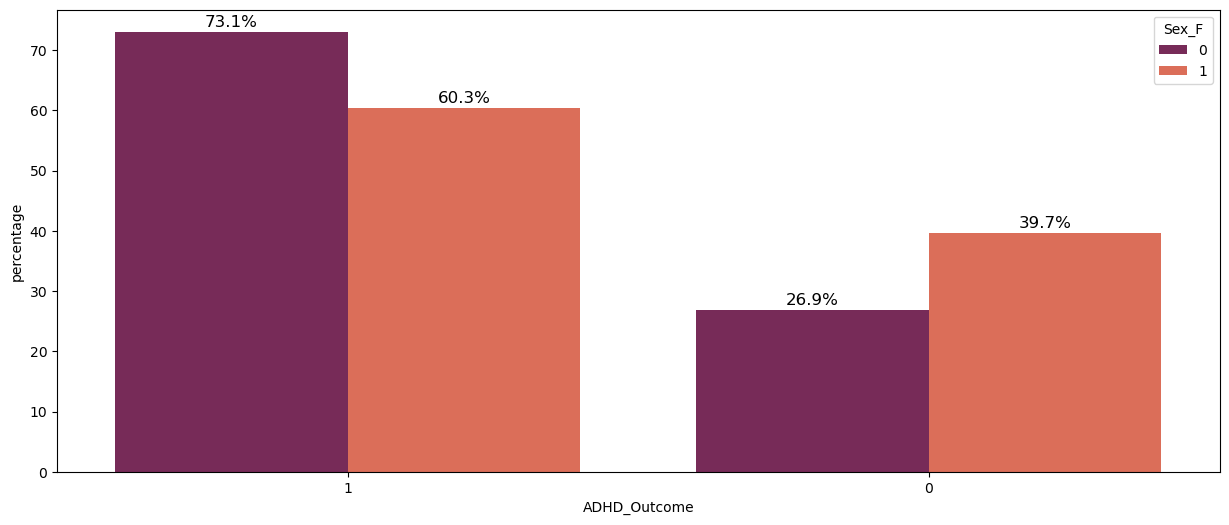

In [95]:
barplot_group(df, "ADHD_Outcome", "Sex_F", 'Education-Default')

- СДВГ у мальчиков диагностируется чаще, чем у девочек на 12.8%, гипотеза подтвердилась

In [107]:
cat_cols = df.select_dtypes(include=['number']).columns
cat_cols = cat_cols.drop(['EHQ_EHQ_Total', 'MRI_Track_Age_at_Scan'])

In [108]:
cat_cols

Index(['Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ', 'ColorVision_CV_Score', 'APQ_P_APQ_P_CP',
       'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV', 'APQ_P_APQ_P_OPD',
       'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP', 'SDQ_SDQ_Conduct_Problems',
       'SDQ_SDQ_Difficulties_Total', 'SDQ_SDQ_Emotional_Problems',
       'SDQ_SDQ_Externalizing', 'SDQ_SDQ_Generating_Impact',
       'SDQ_SDQ_Hyperactivity', 'SDQ_SDQ_Internalizing',
       'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial'],
      dtype='object')

In [173]:
#Разделим датасет на два датасета, в первом только мальчики, во втоом только девочки
df_m = df.loc[df['Sex_F'] == '0']
df_f = df.loc[df['Sex_F'] == '1']

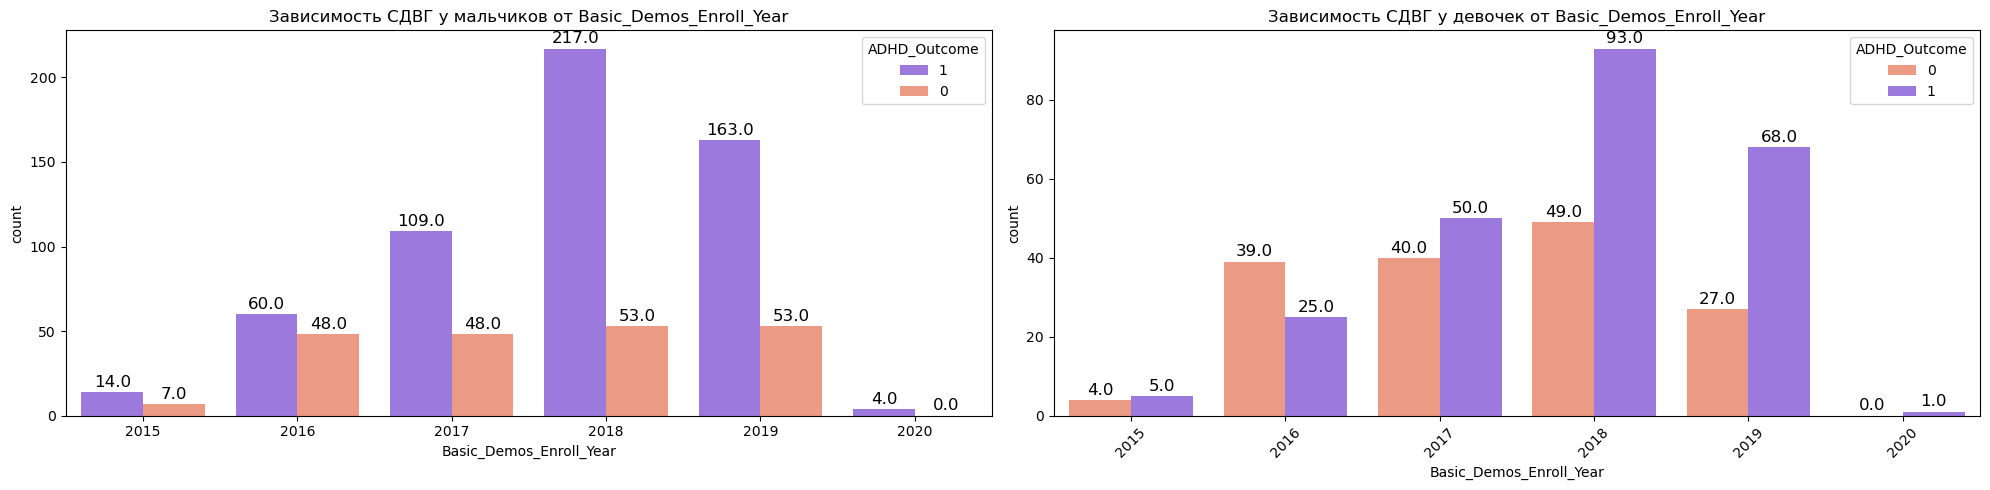

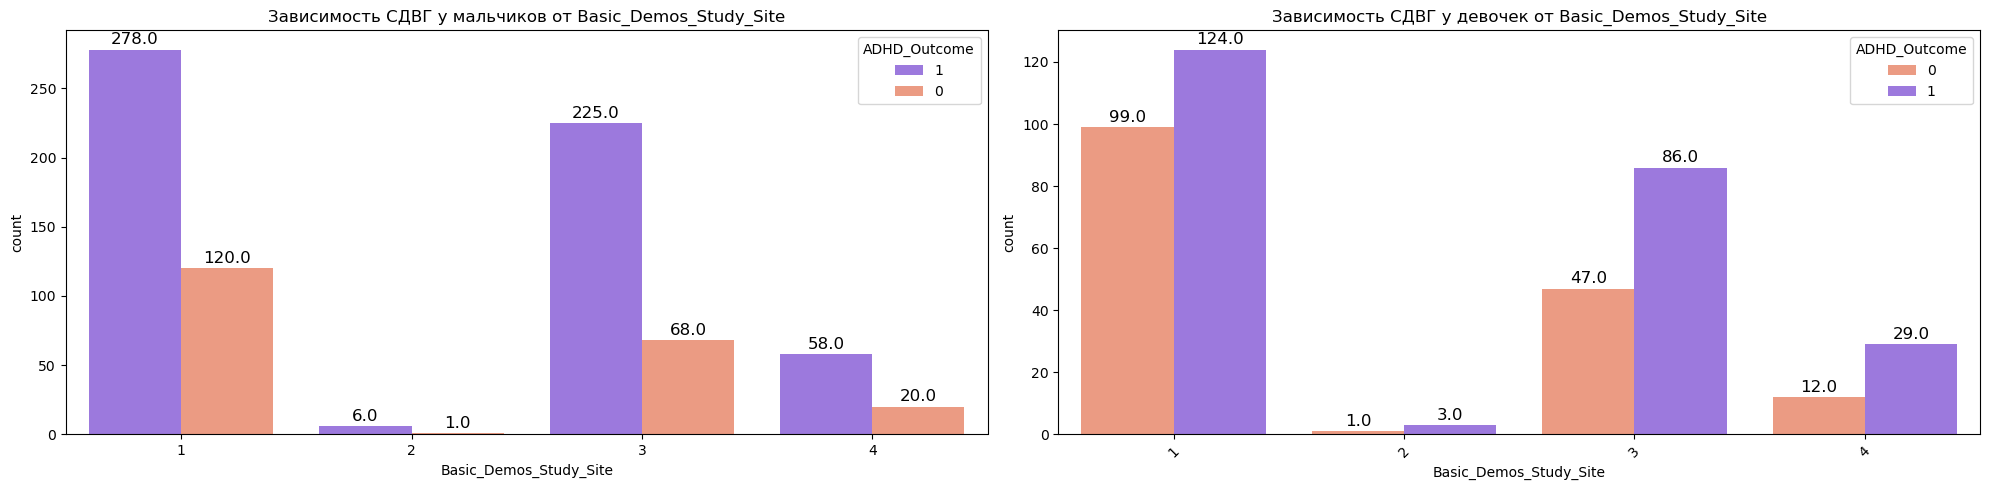

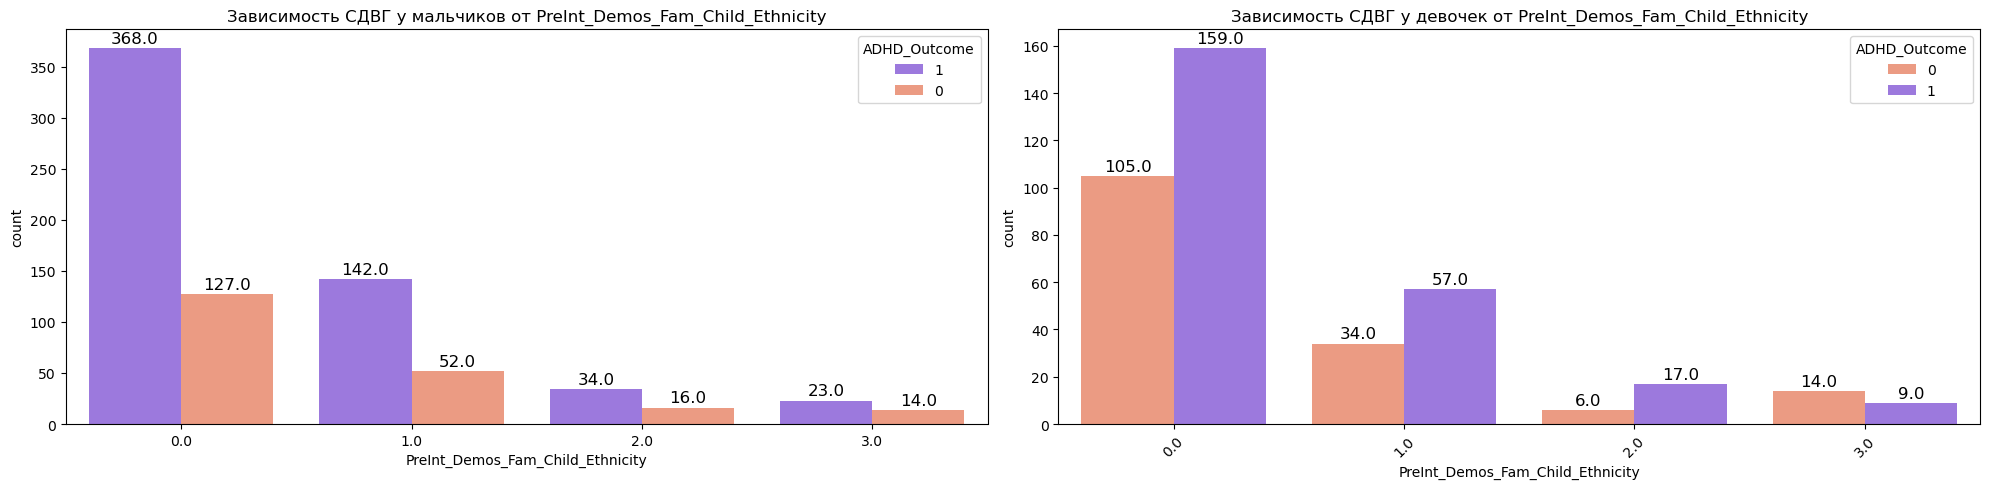

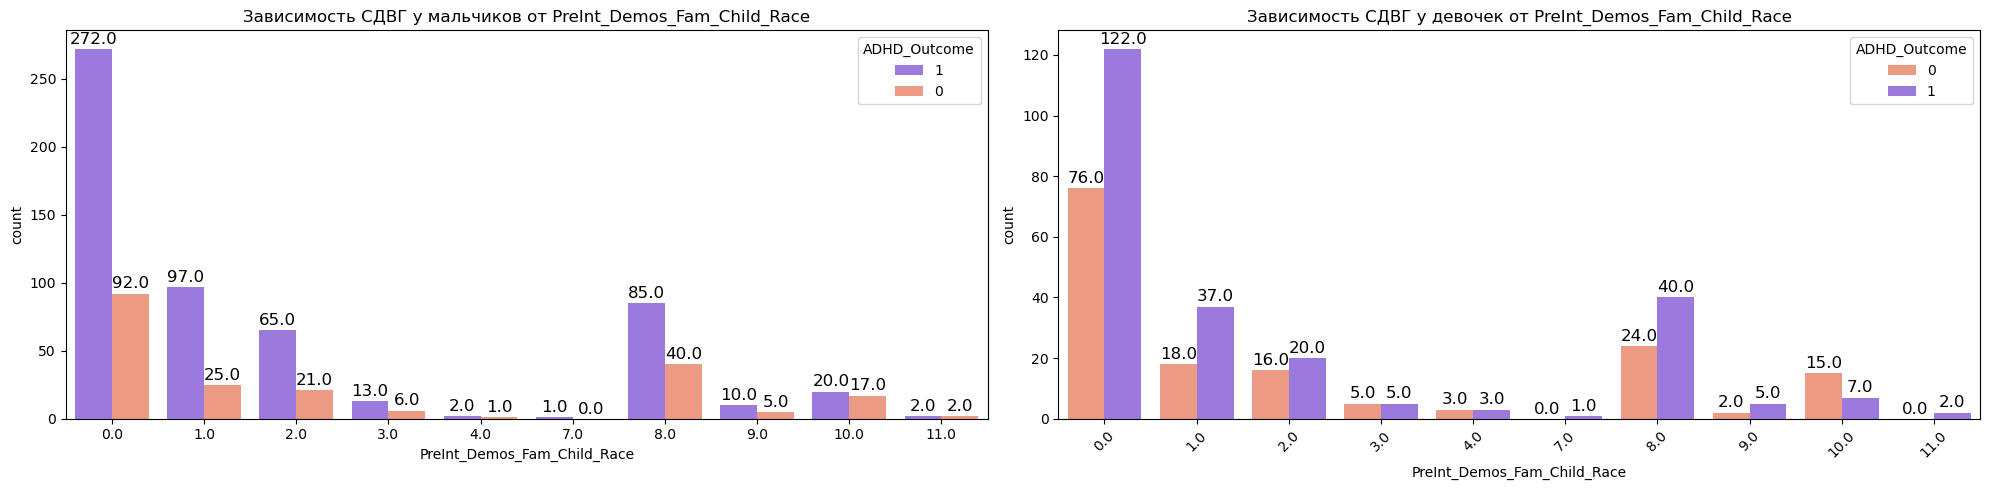

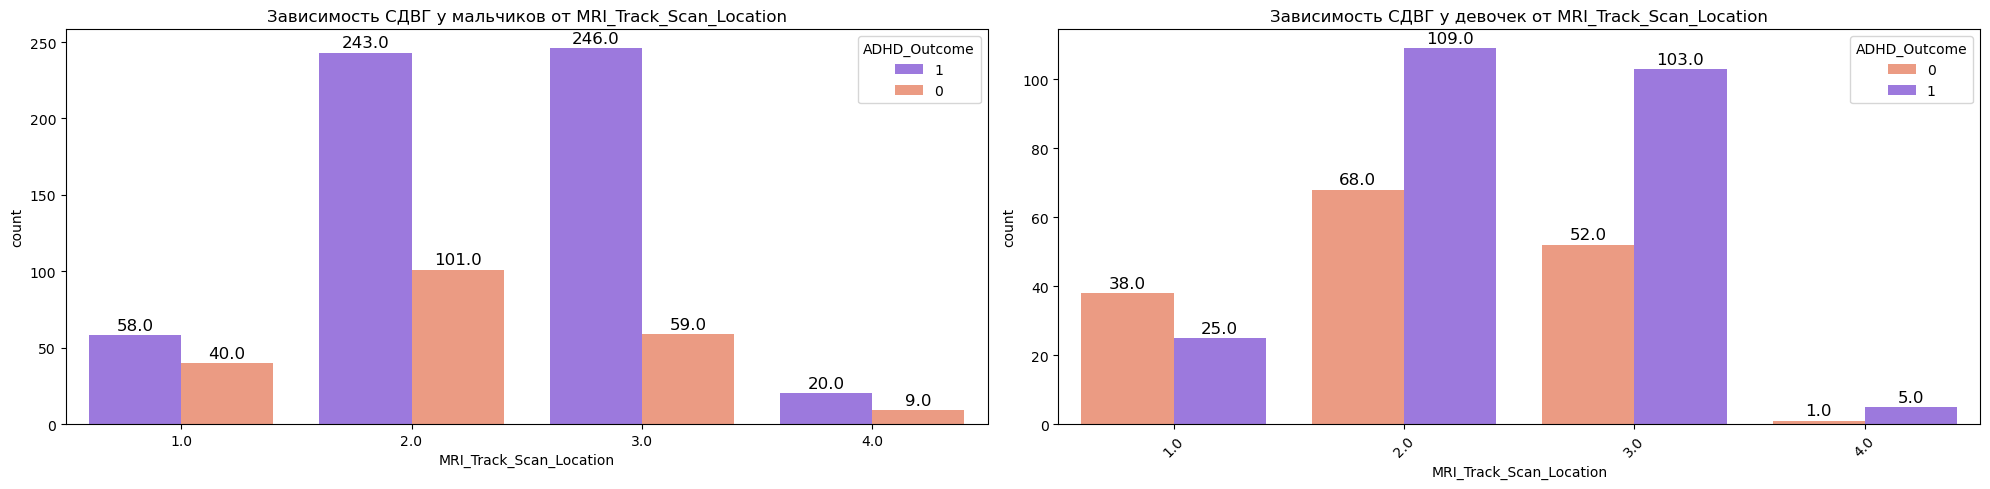

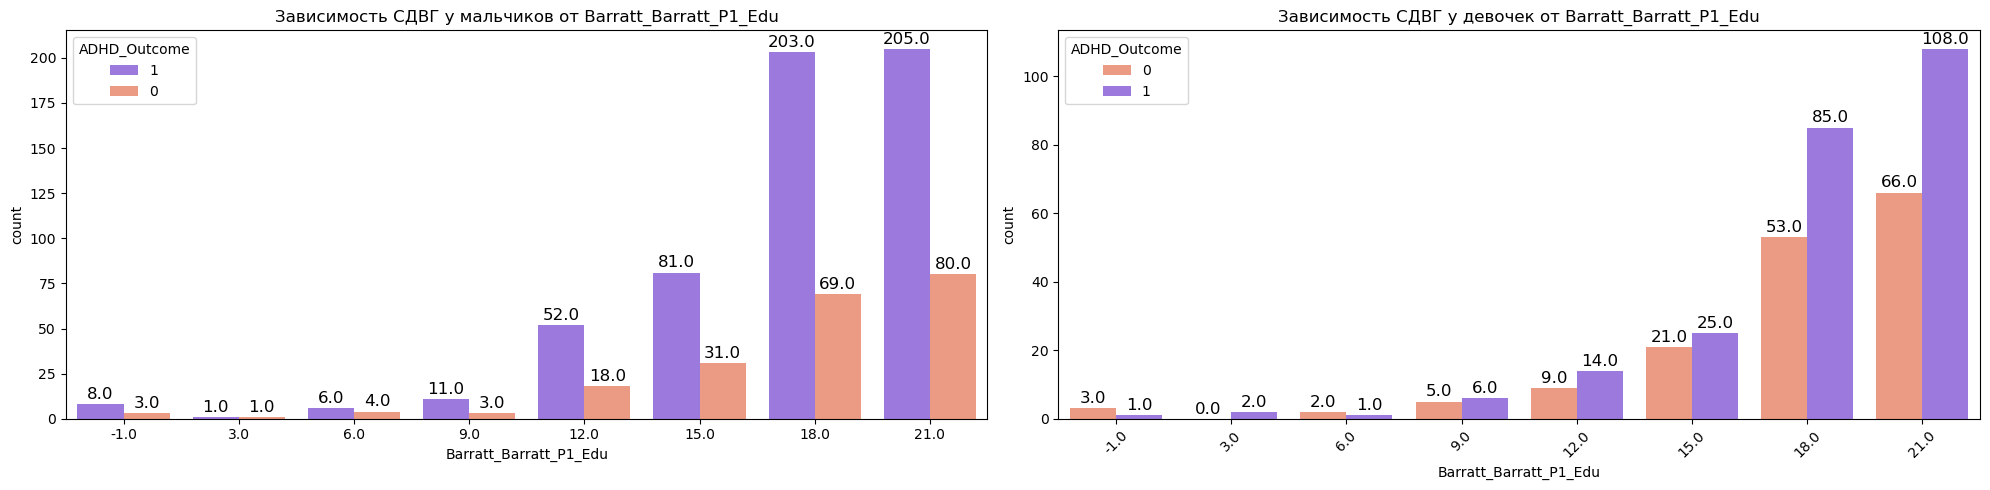

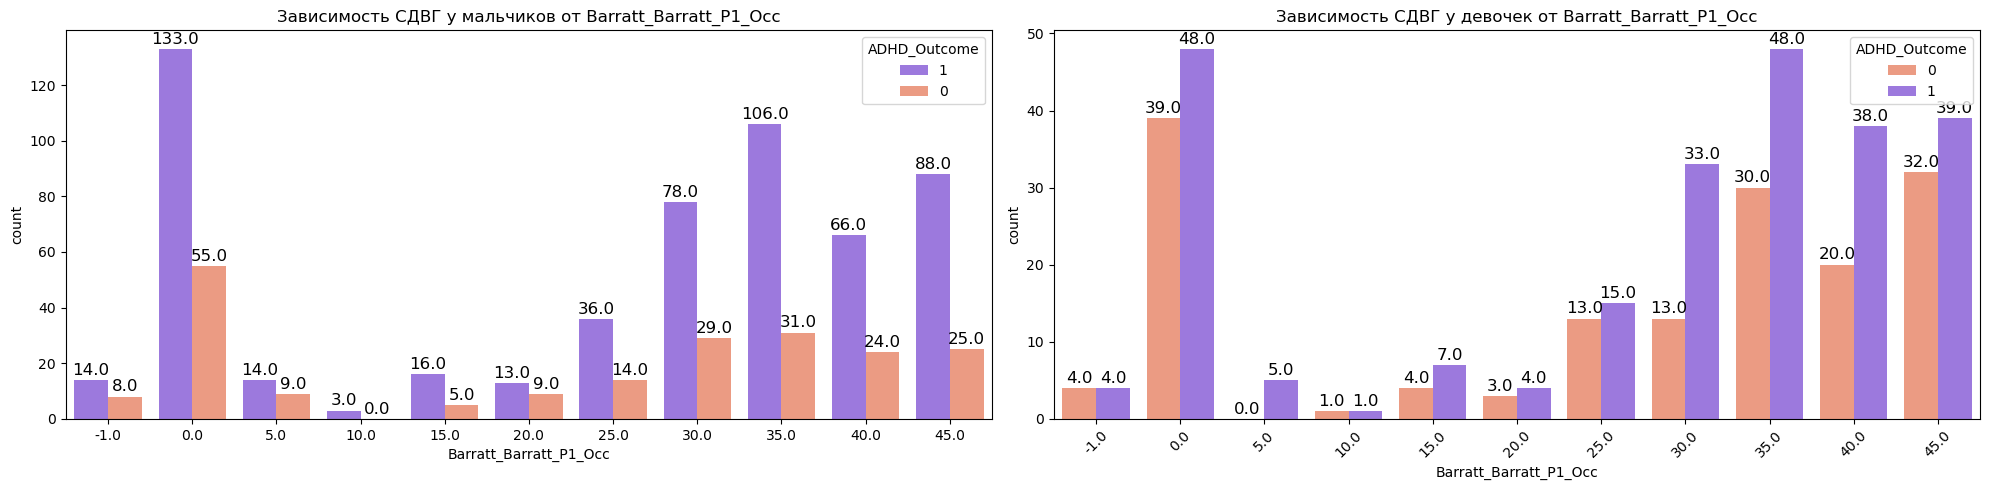

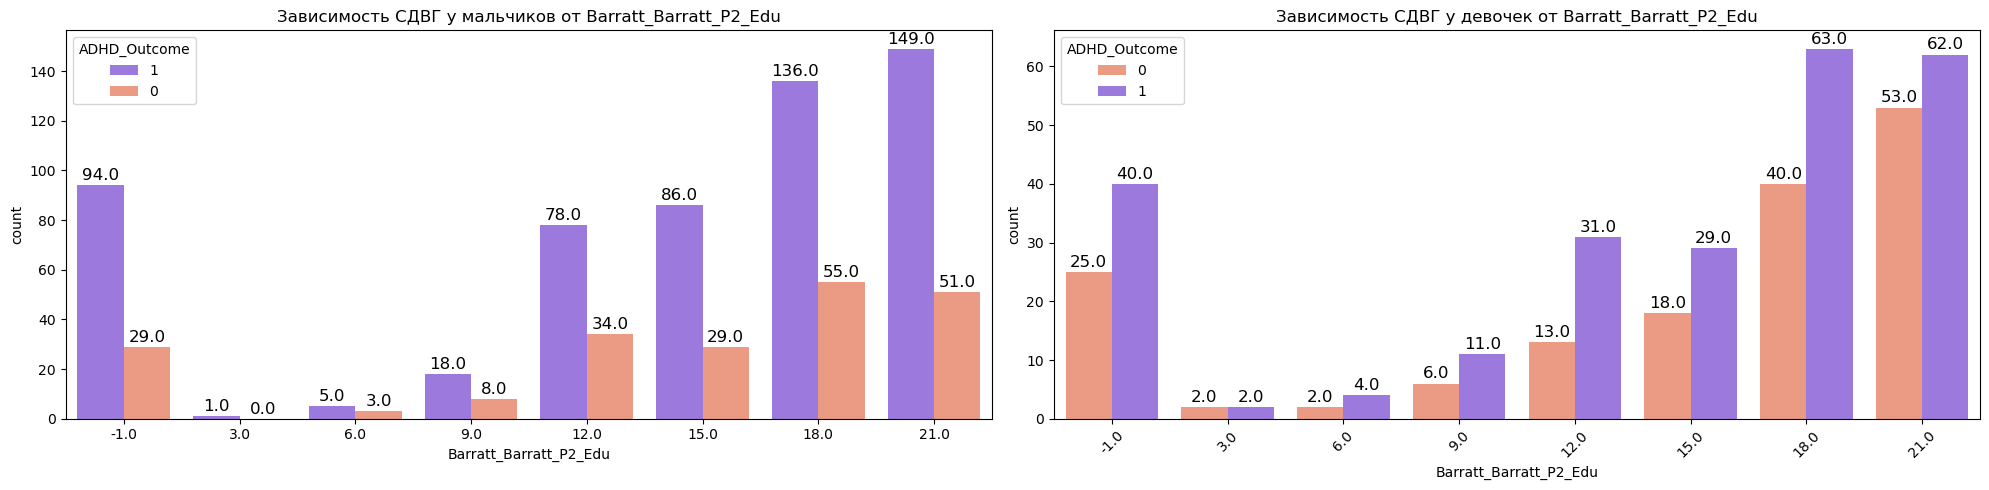

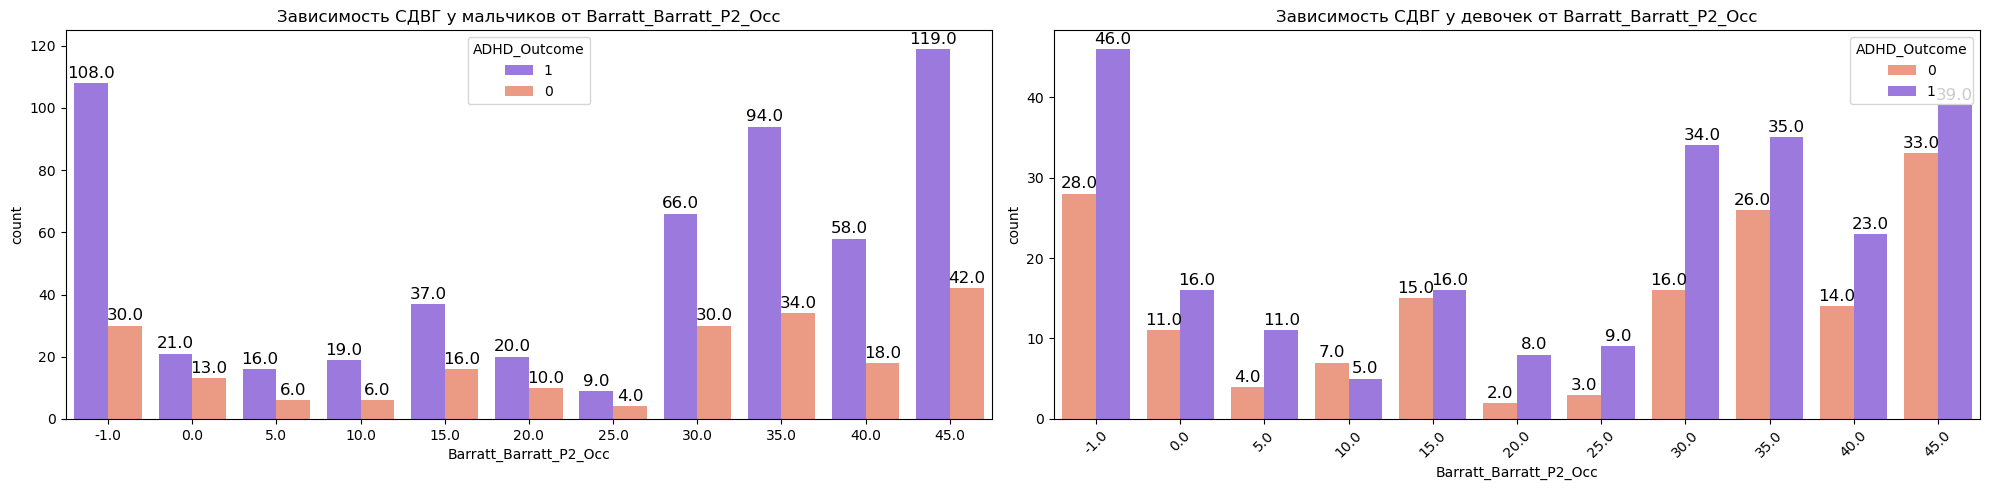

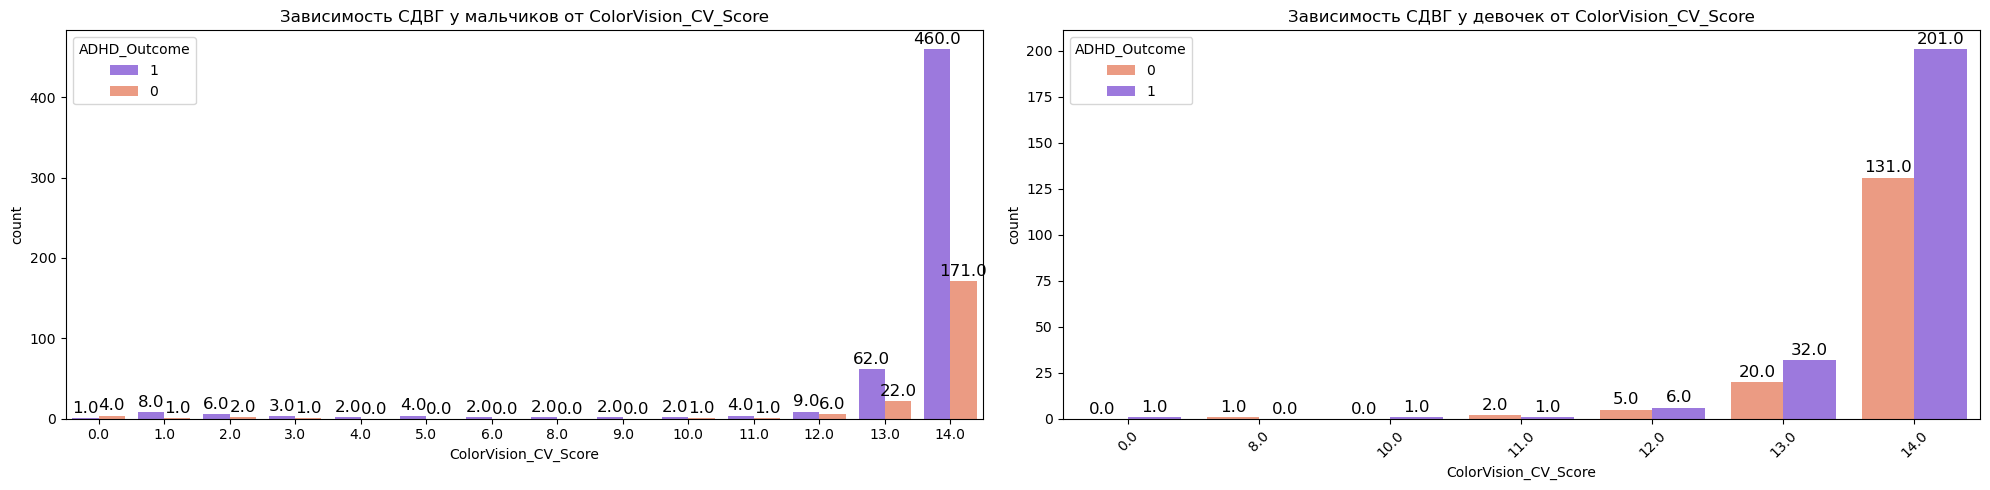

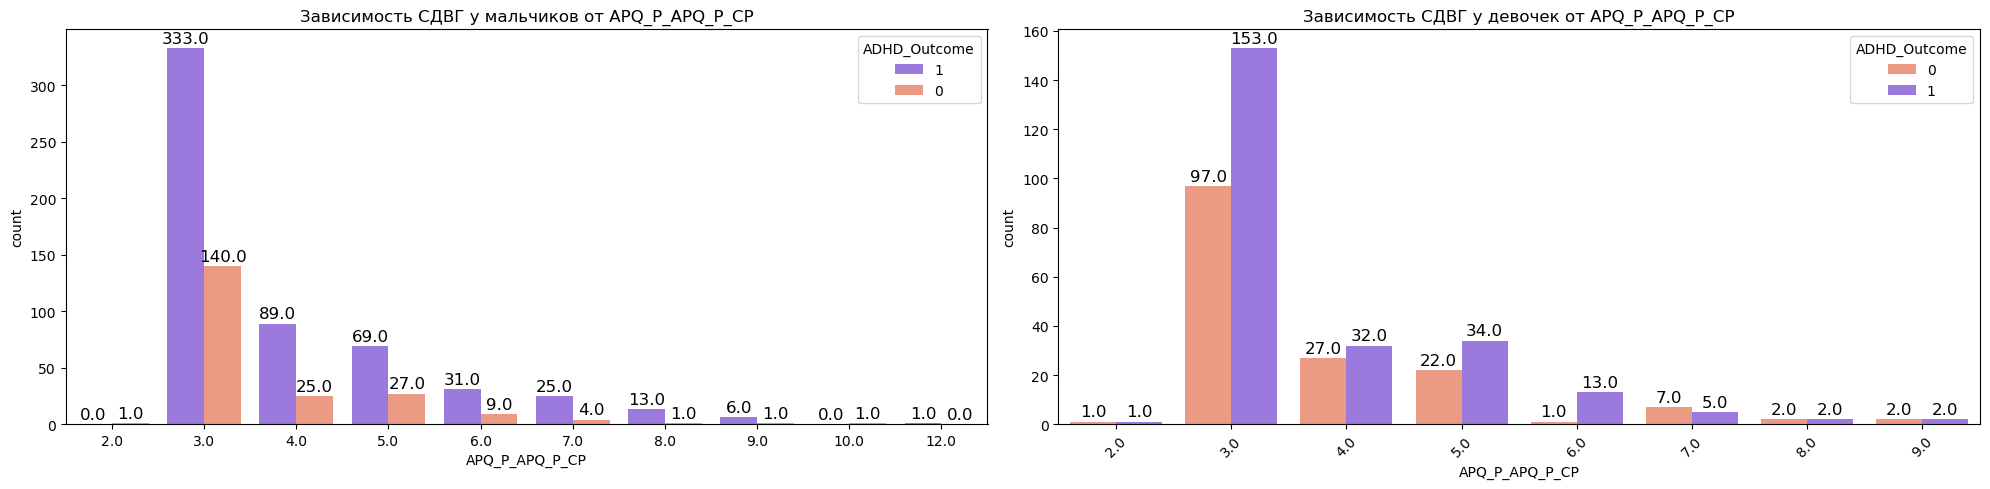

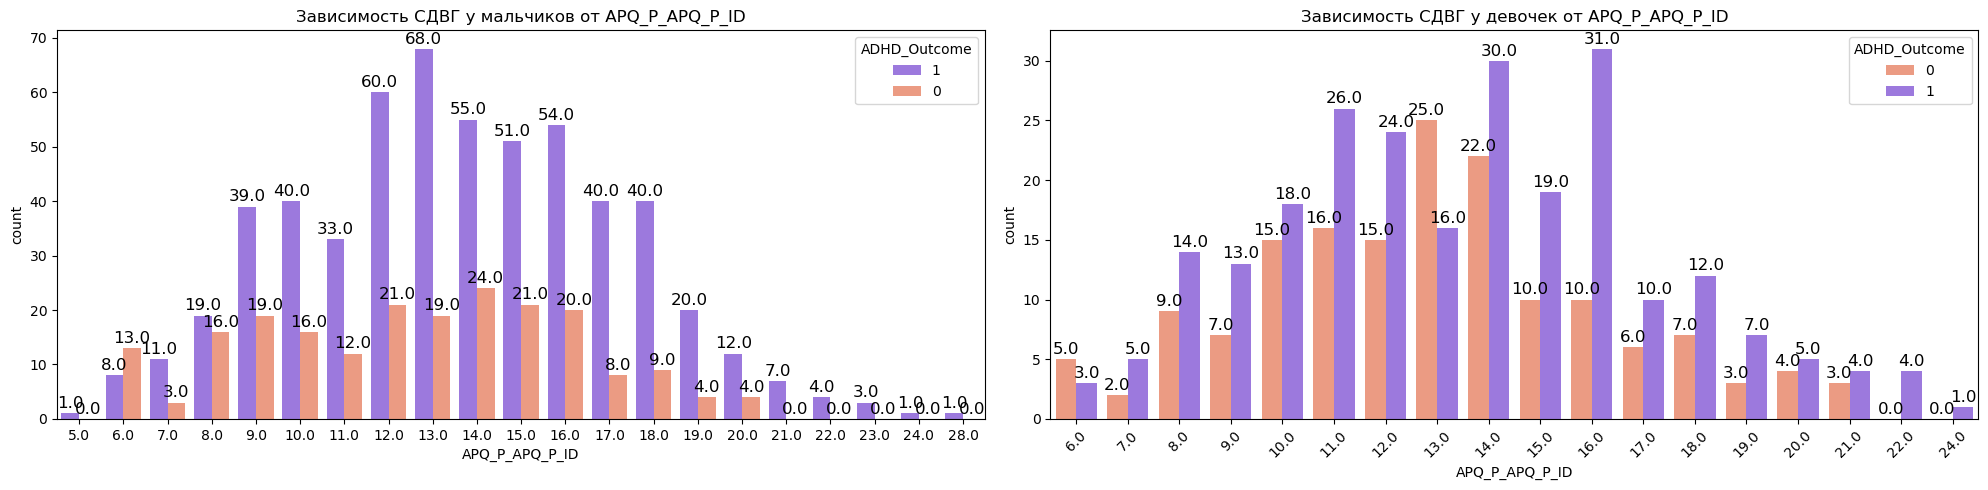

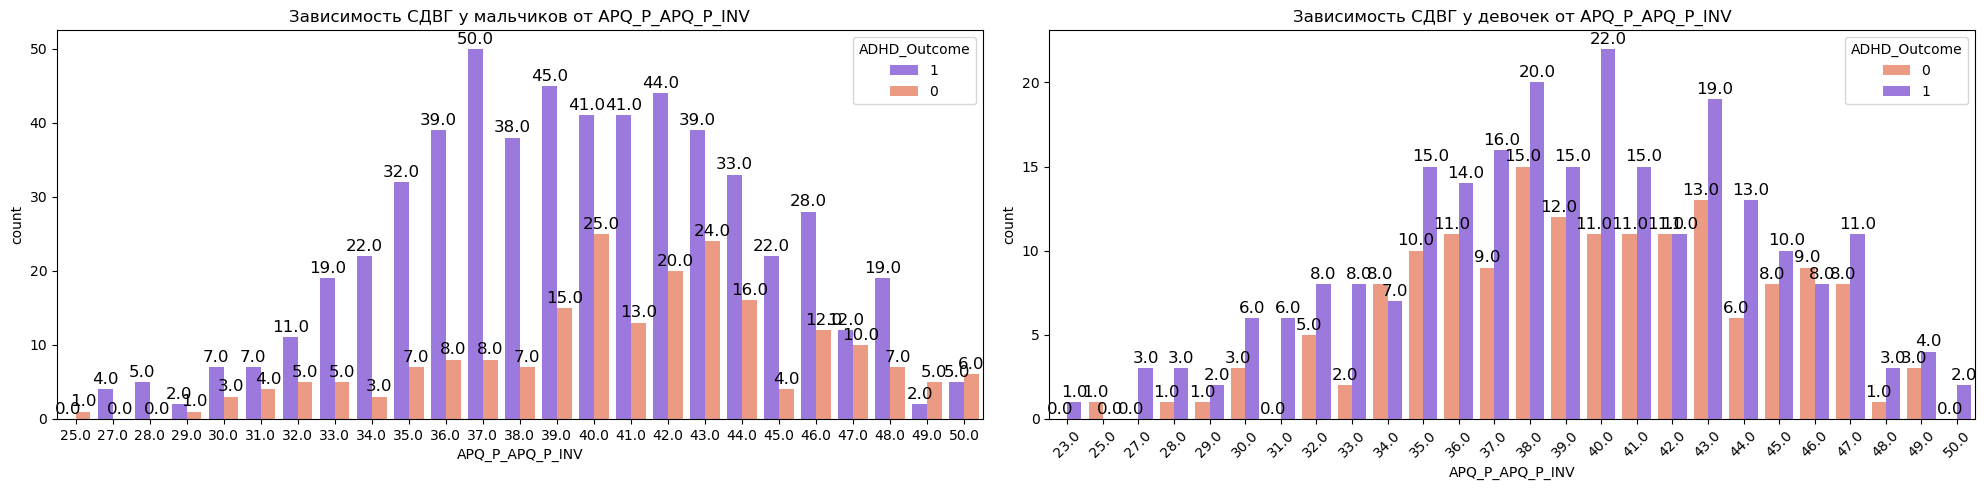

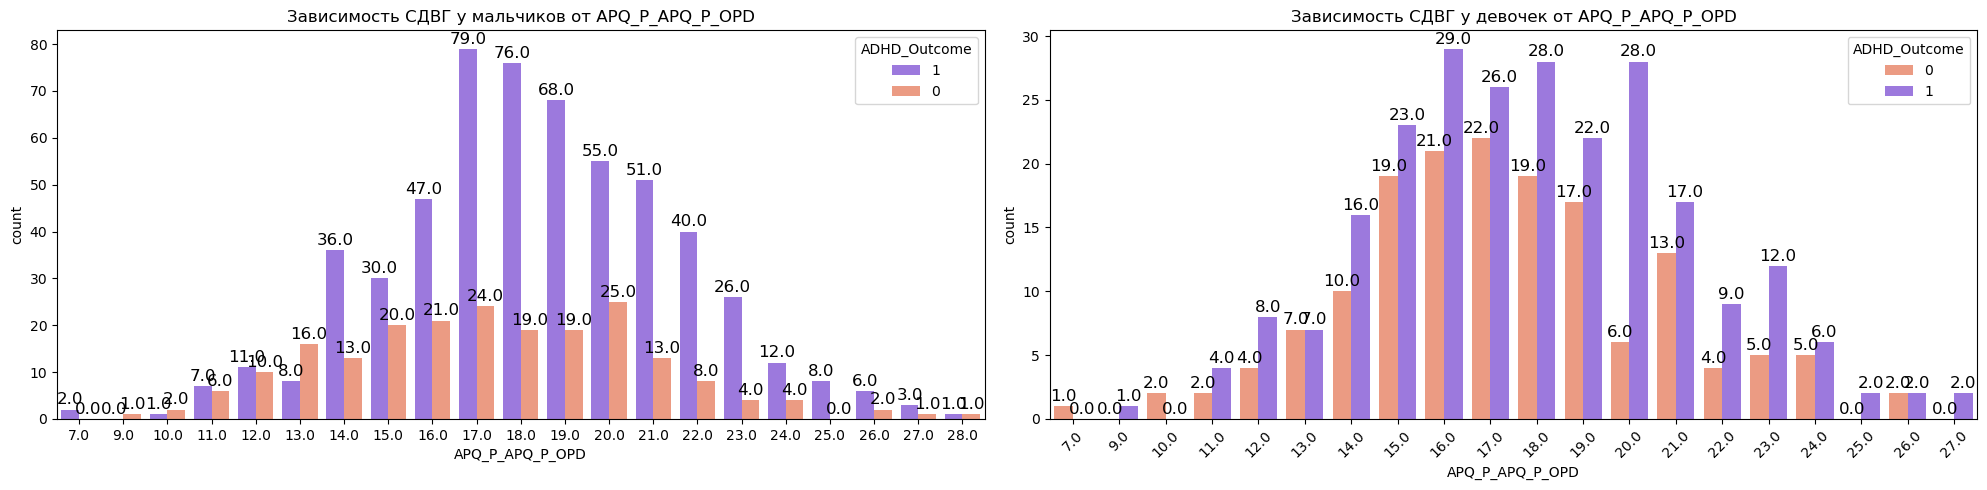

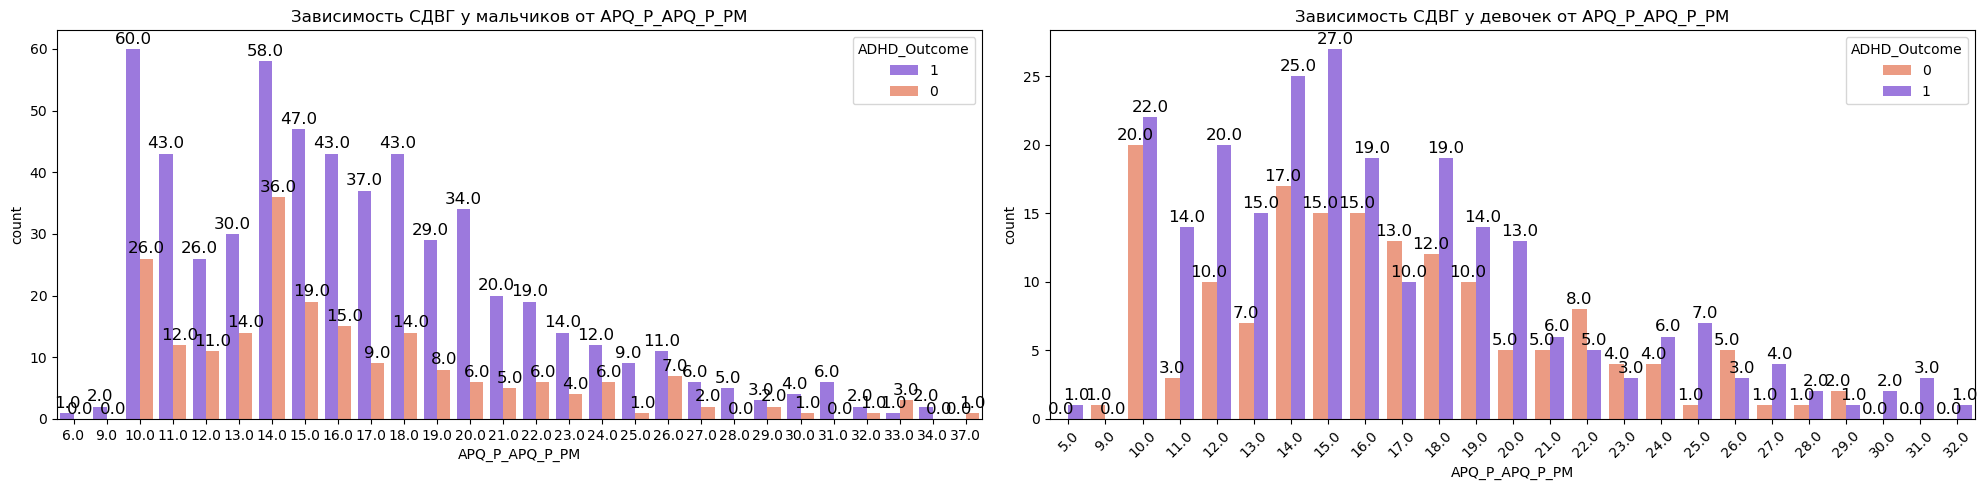

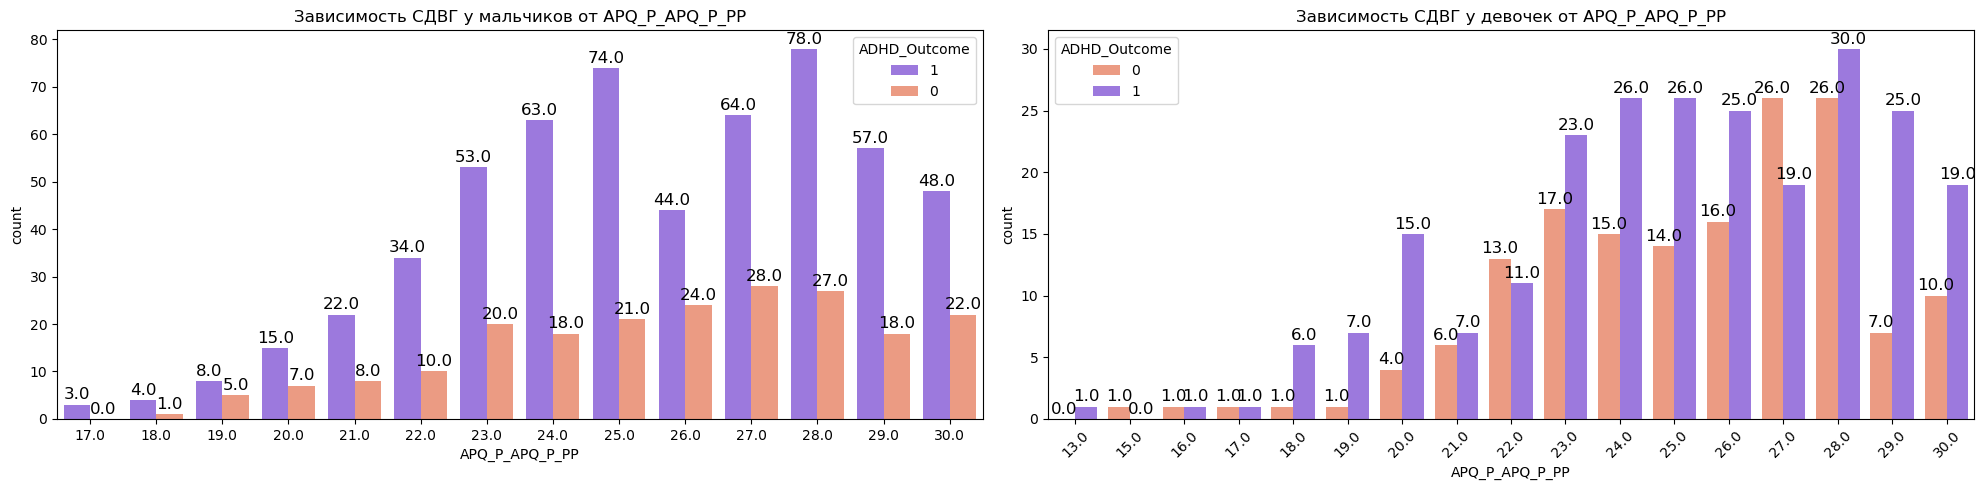

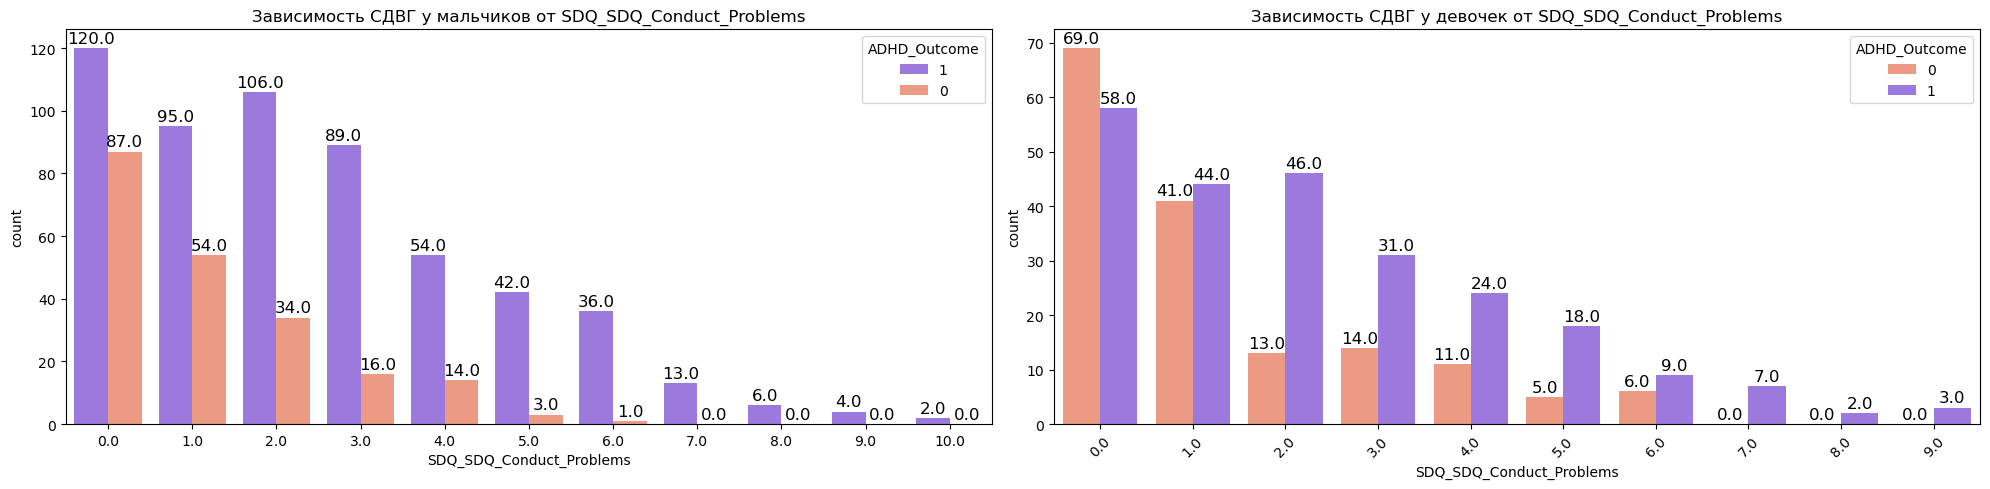

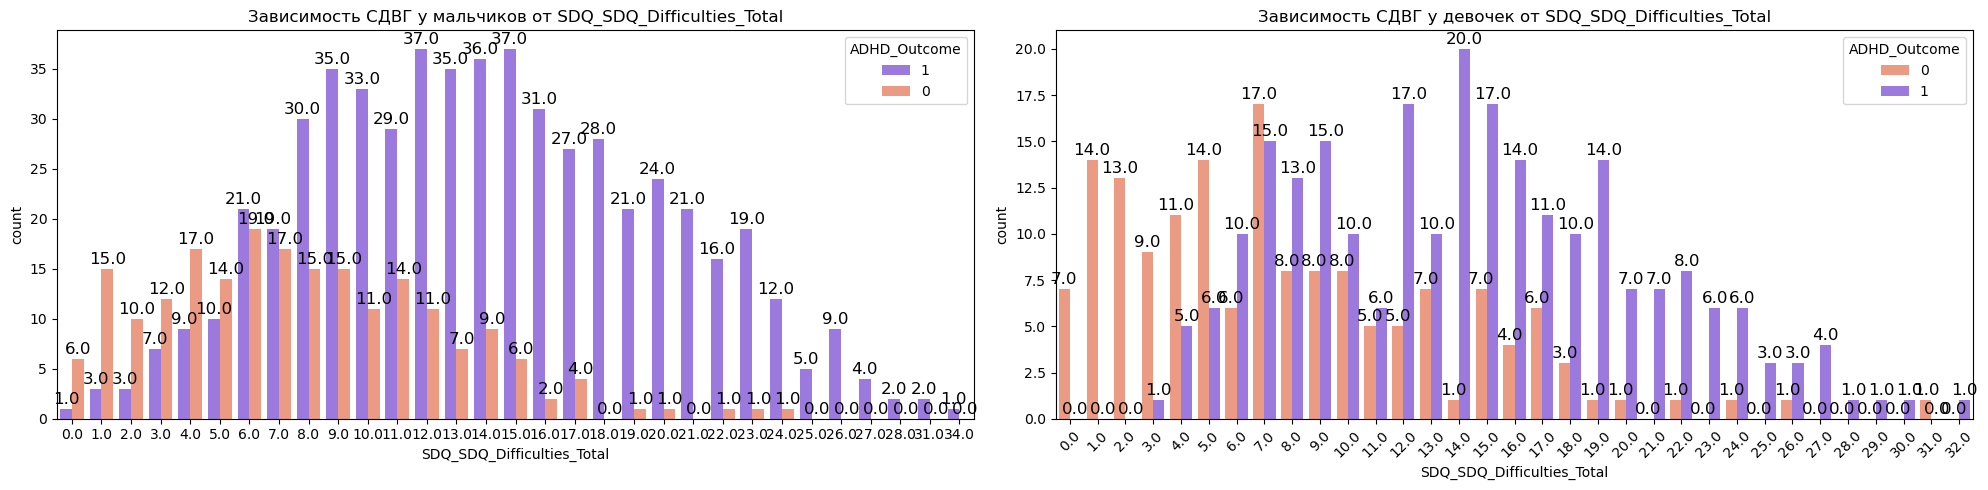

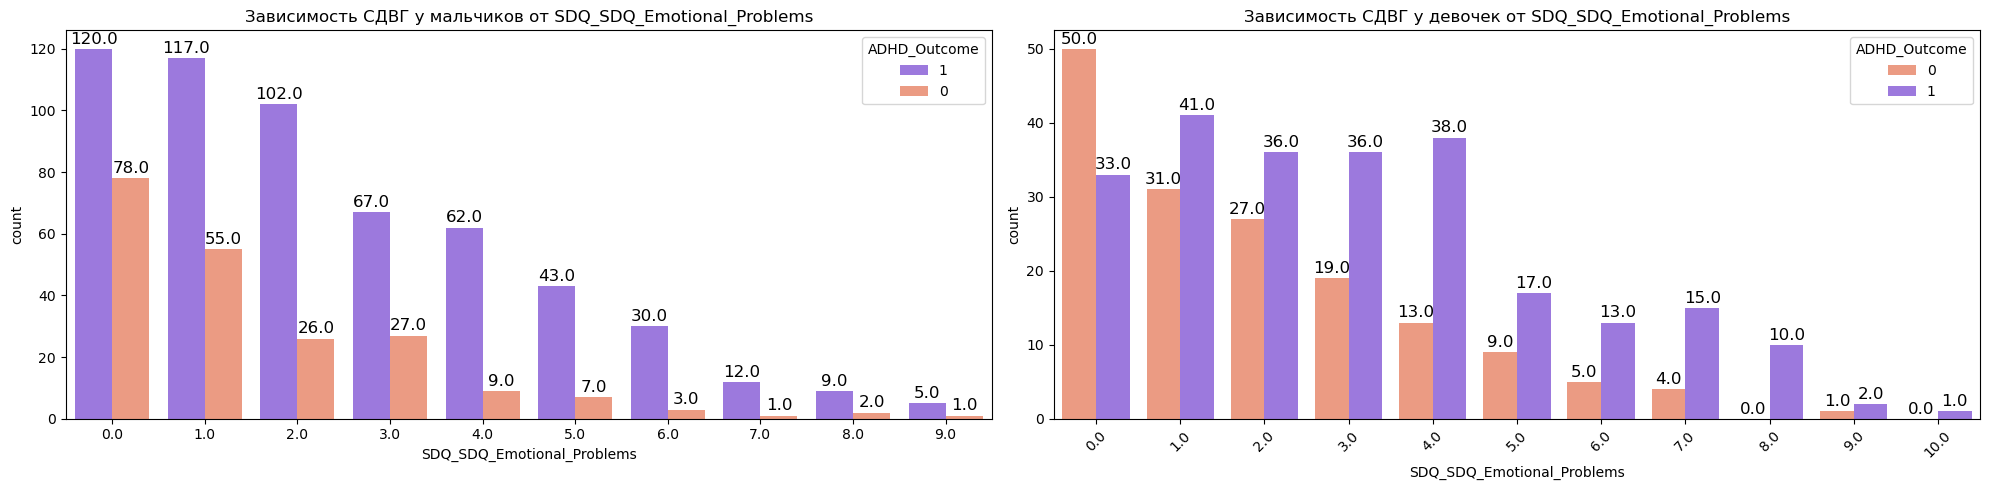

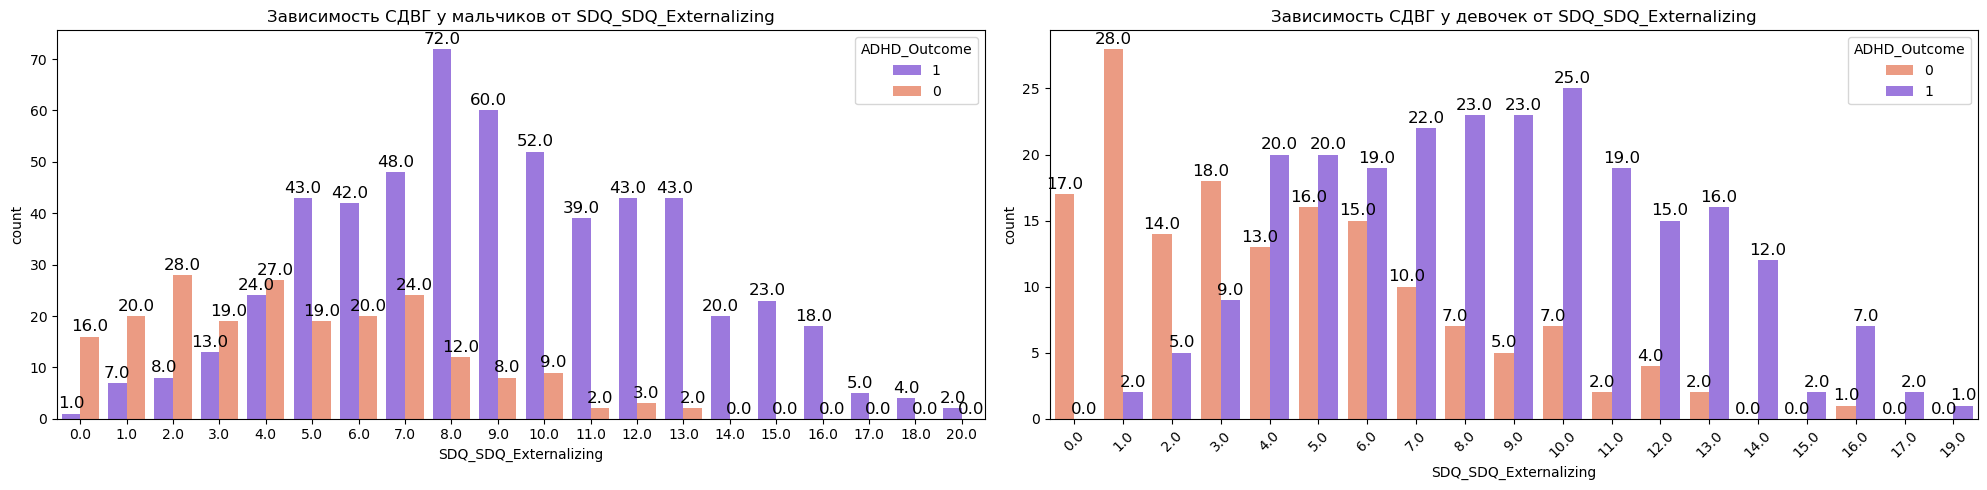

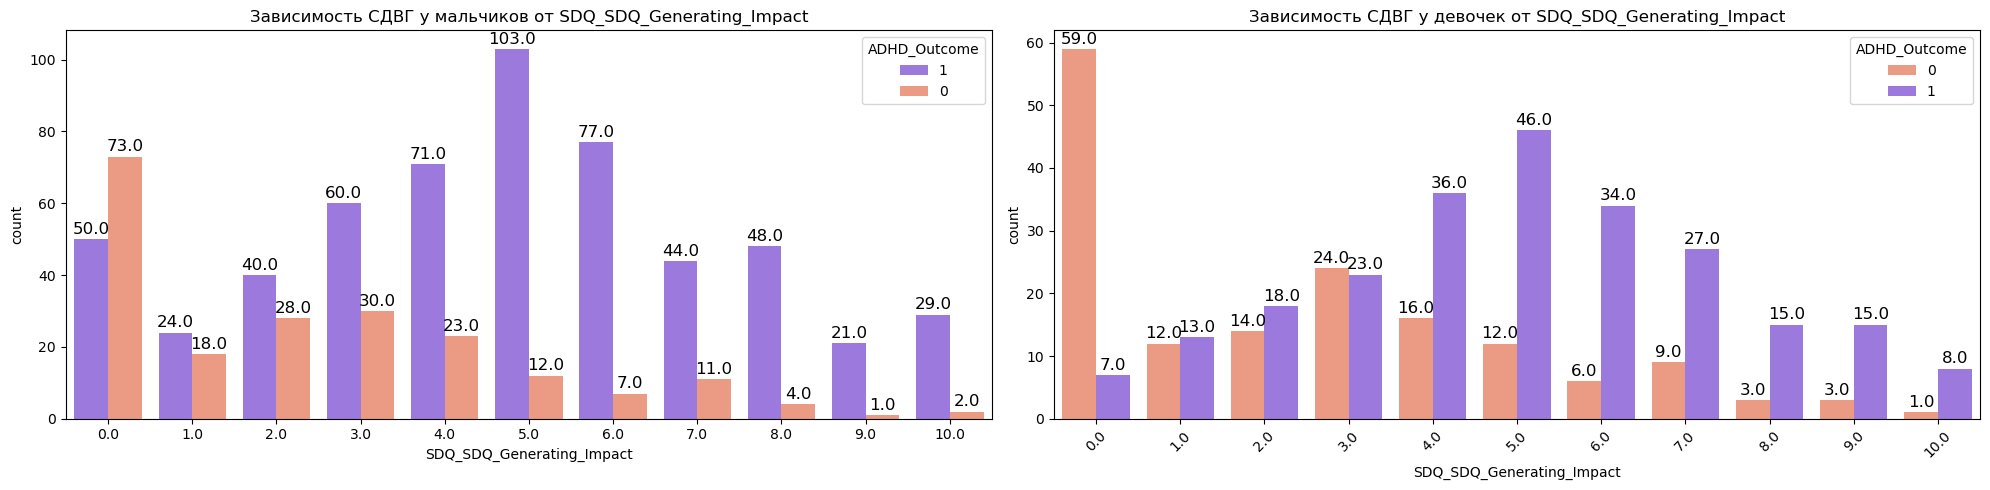

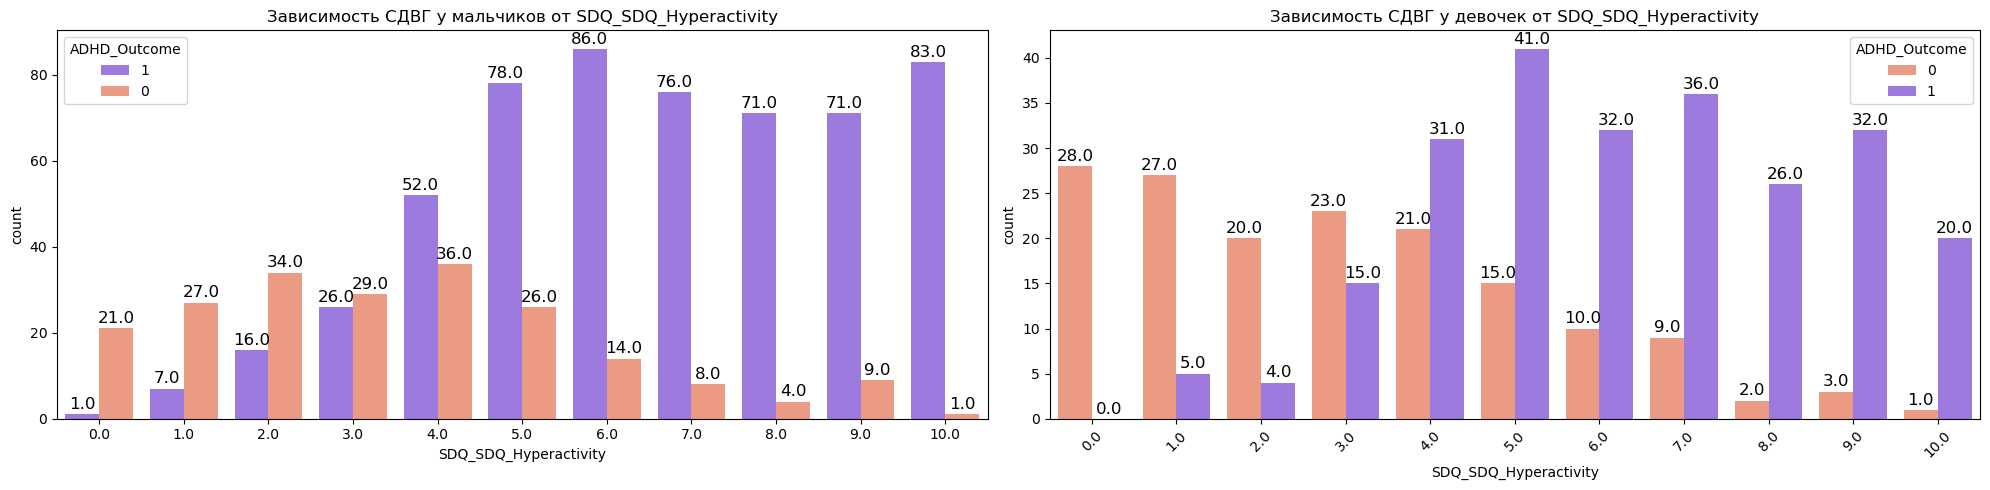

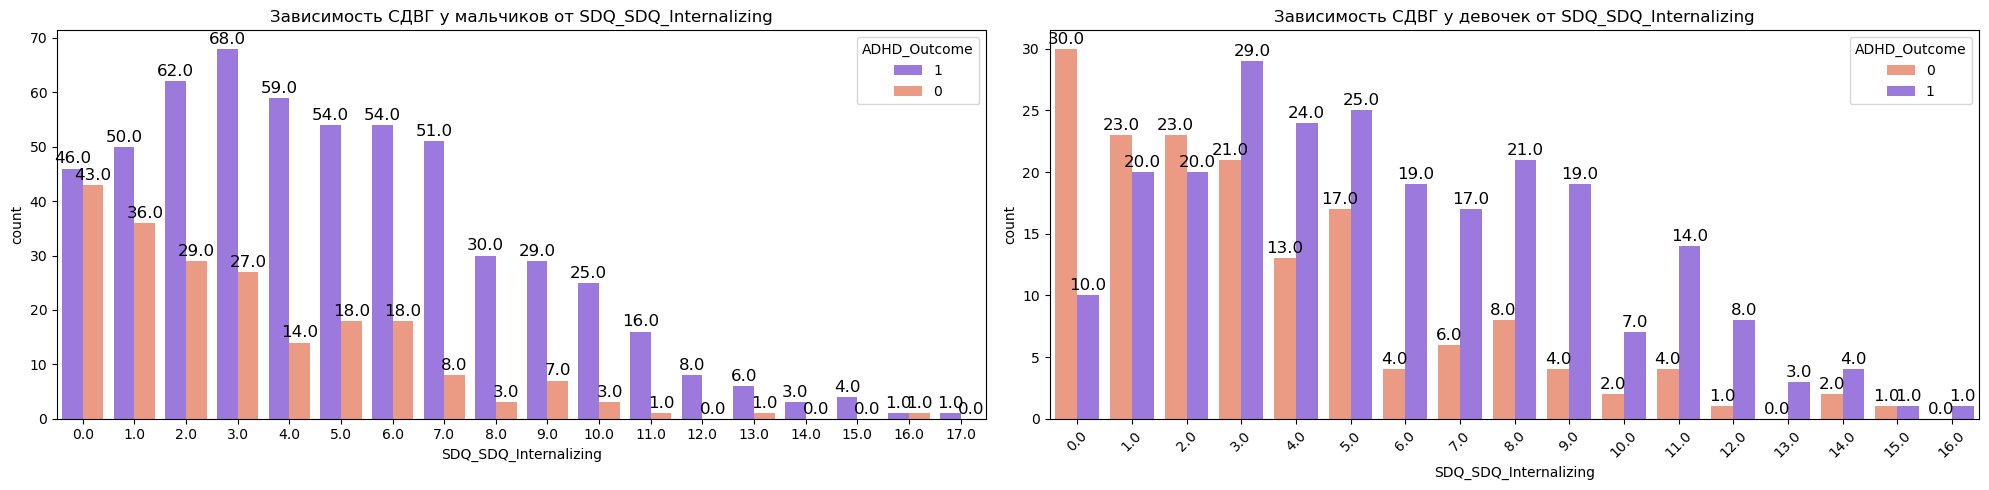

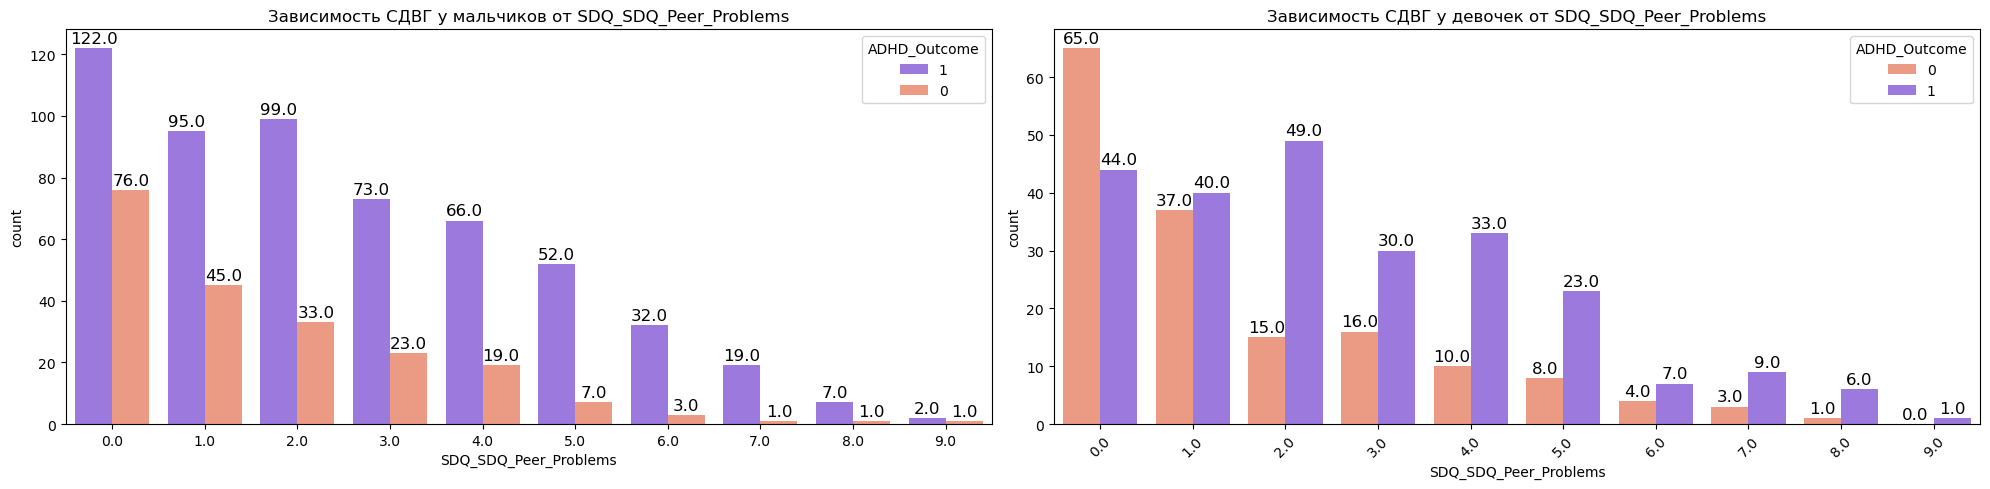

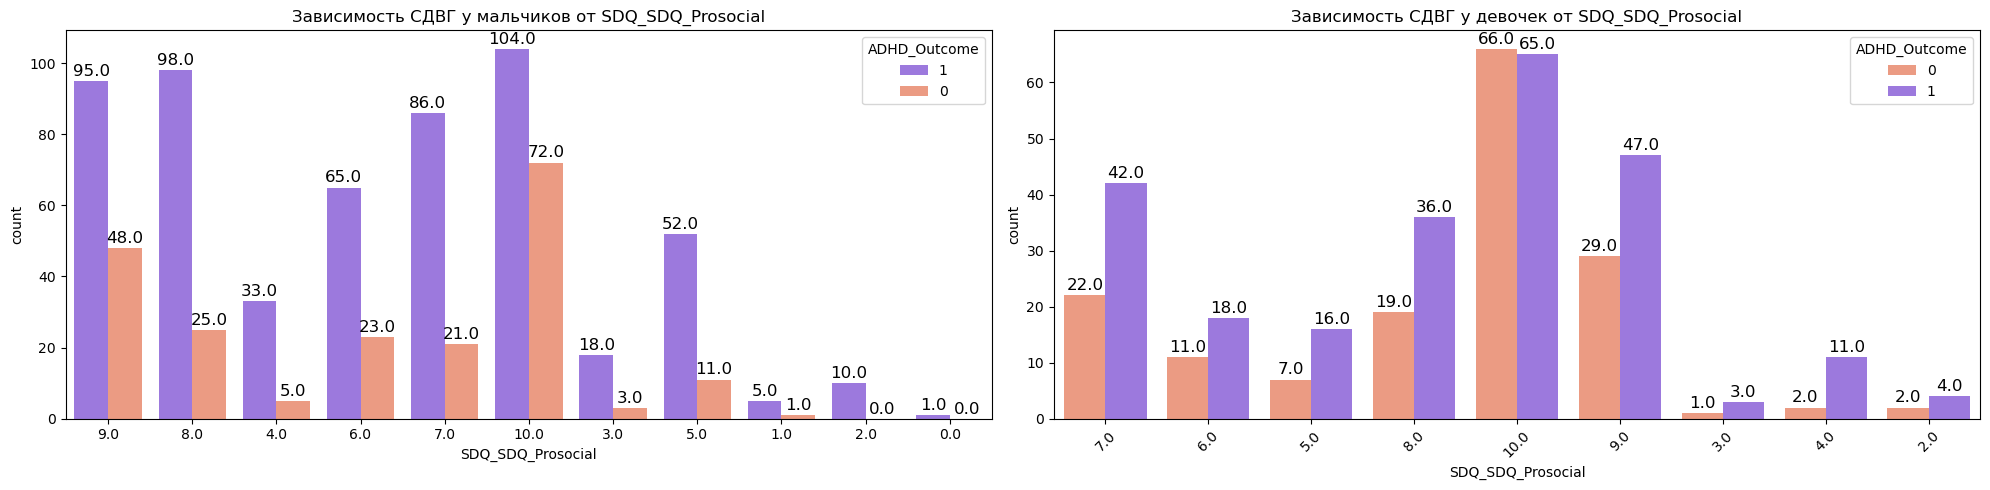

In [198]:
#Анализ числовых и категориальных признаков

for col in cat_cols:
    fig, axes = plt.subplots(ncols=2, figsize=(20,5))
    ax = sns.countplot(x=col, data=df_m, hue=target_col, palette=["#9768ee","#fc9272"], ax=axes[0])
    for p in ax.patches:
        percentage = '{:.1f}'.format(p.get_height())
        ax.annotate(
            percentage,  # текст
            (p.get_x() + p.get_width() / 2., p.get_height()),  # координата xy
            ha='center',  # центрирование
            va='center',
            xytext=(0, 7),
            textcoords='offset points',  # точка смещения относительно координаты
            fontsize=12)    
    ax = sns.countplot(x=col, data=df_f, hue=target_col, palette=["#fc9272","#9768ee"], ax=axes[1])
    for p in ax.patches:
        percentage = '{:.1f}'.format(p.get_height())
        ax.annotate(
            percentage,  # текст
            (p.get_x() + p.get_width() / 2., p.get_height()),  # координата xy
            ha='center',  # центрирование
            va='center',
            xytext=(0, 7),
            textcoords='offset points',  # точка смещения относительно координаты
            fontsize=12)    
    axes[0].set_title(f'Зависимость СДВГ у мальчиков от {col}')
    axes[1].set_title(f'Зависимость СДВГ у девочек от {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [188]:
#Посмотрим на эти же графики в процентах для каждого года и категории 

In [194]:
df_m[col] = df_m[col].astype(str)
df_f[col] = df_f[col].astype(str)

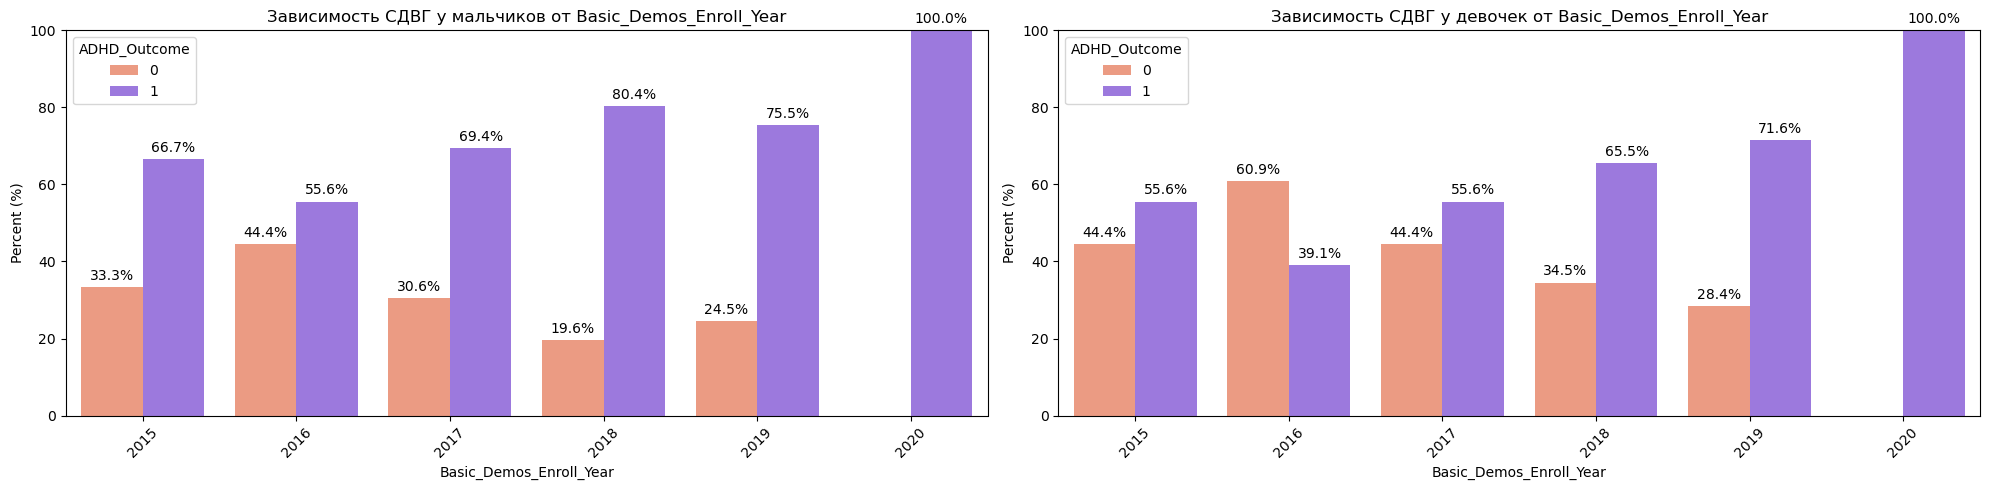

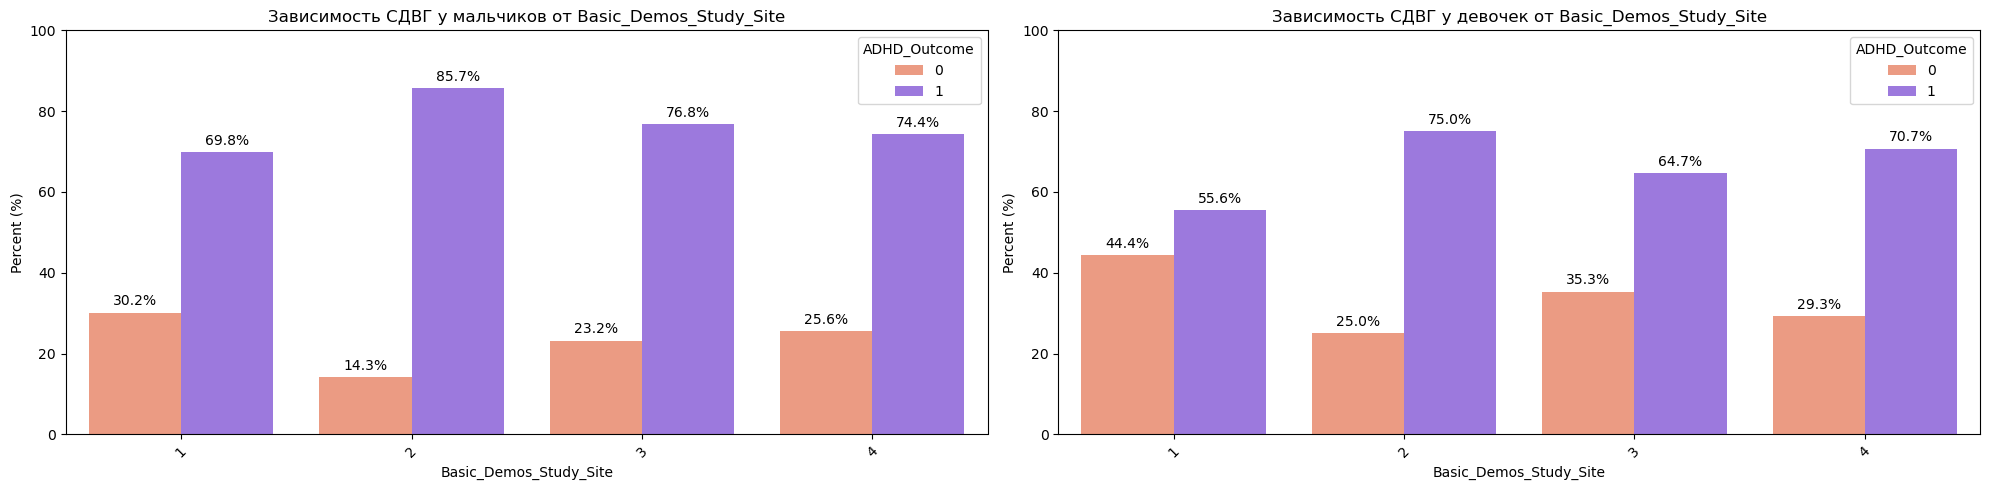

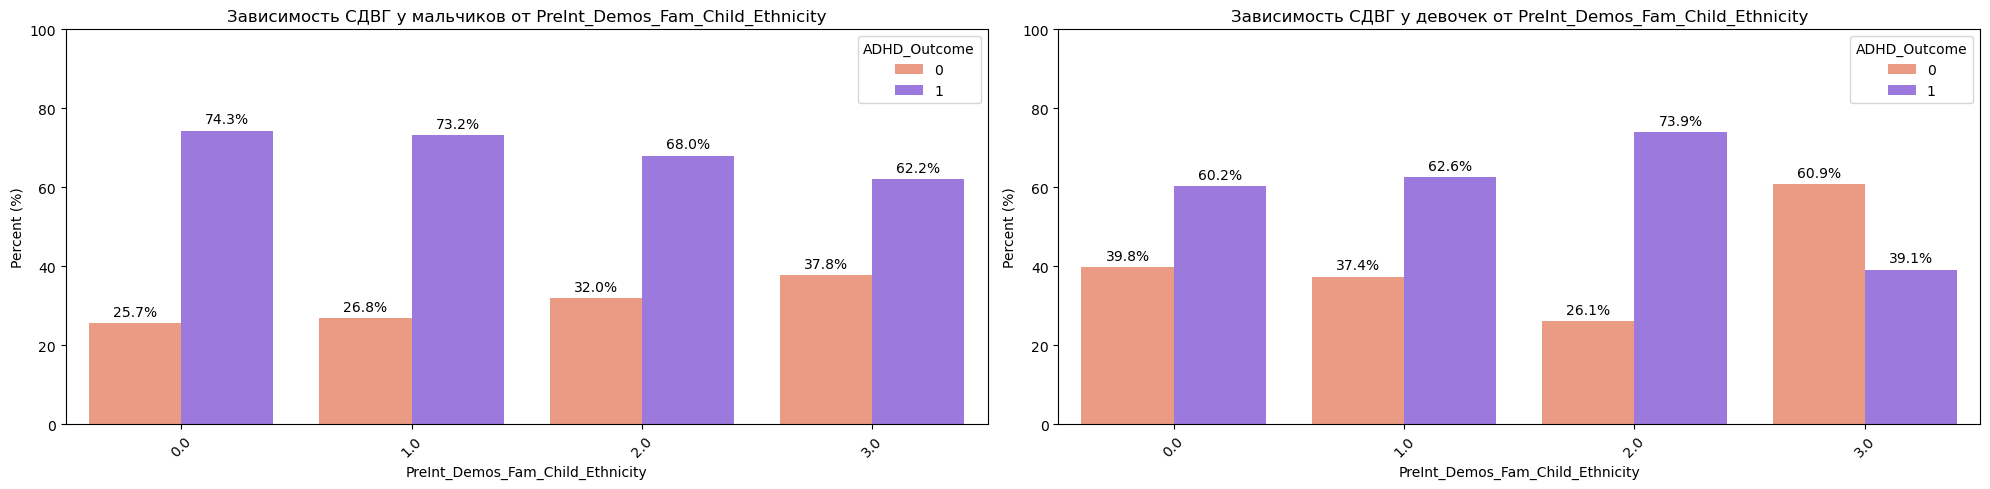

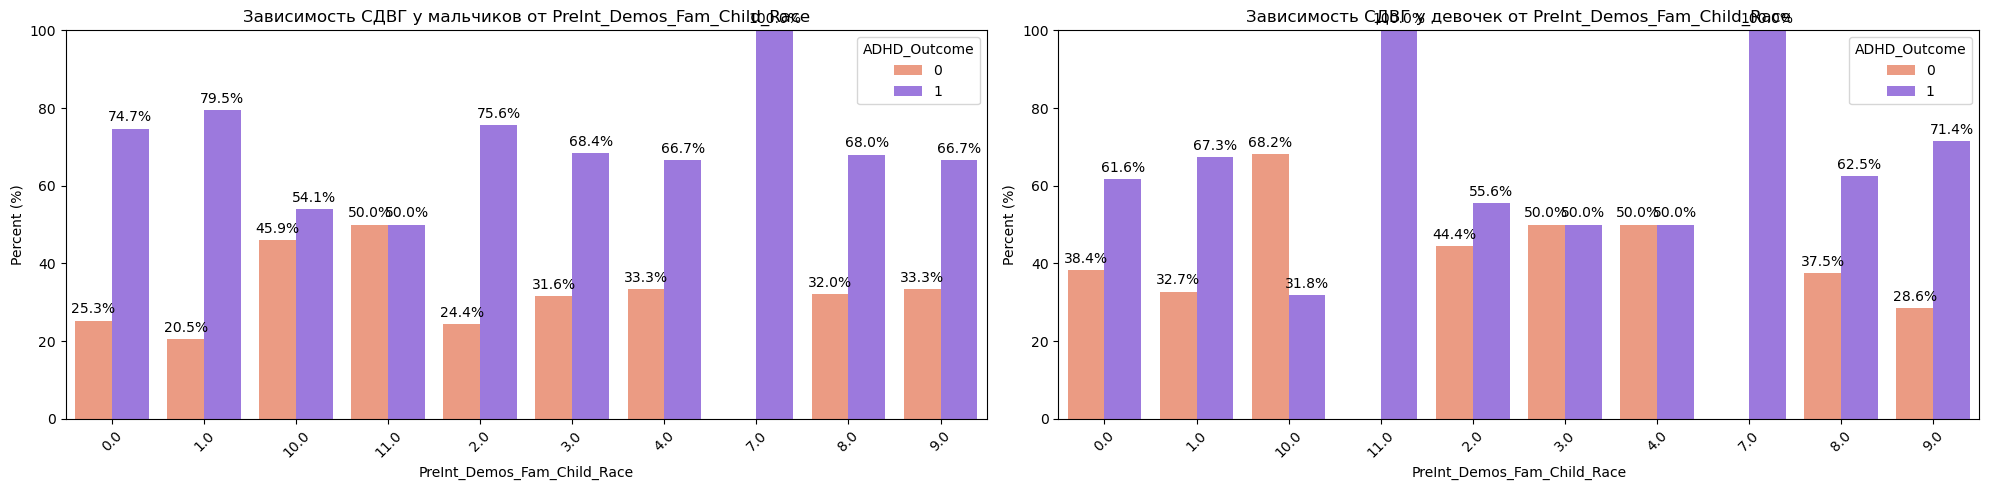

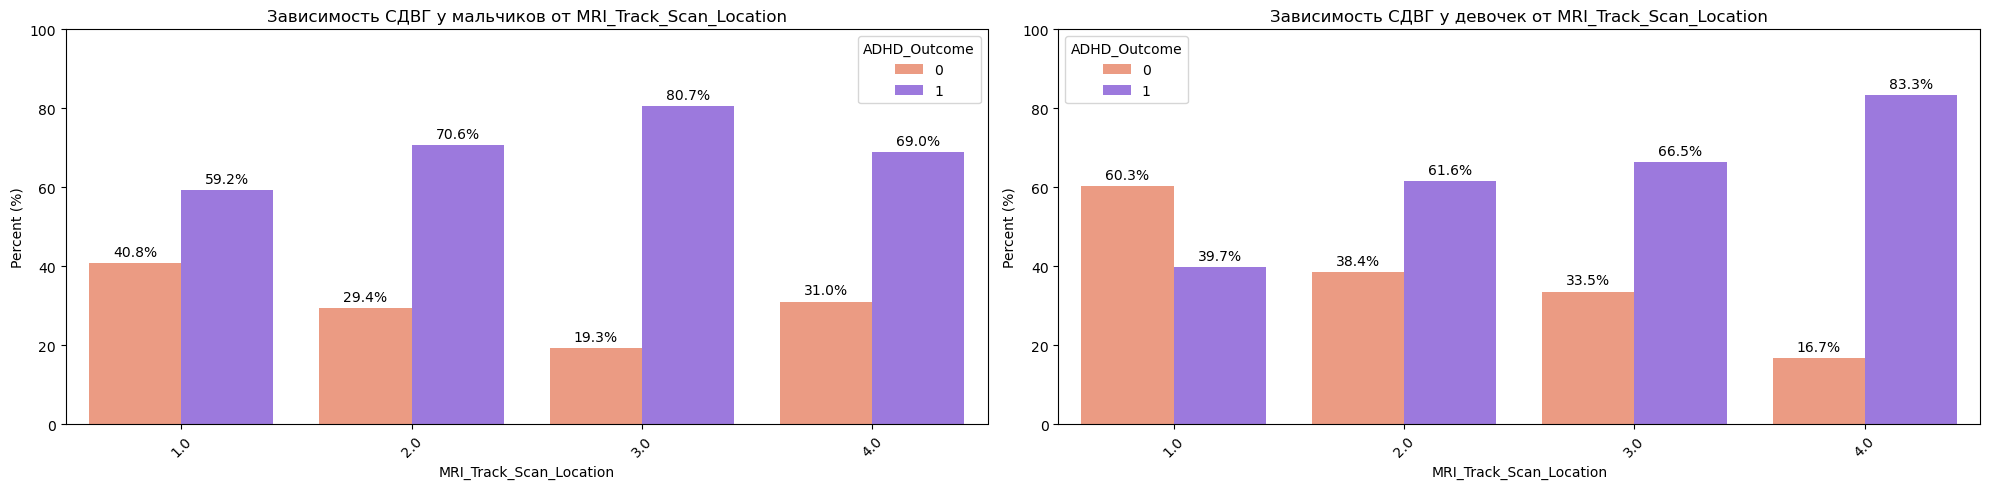

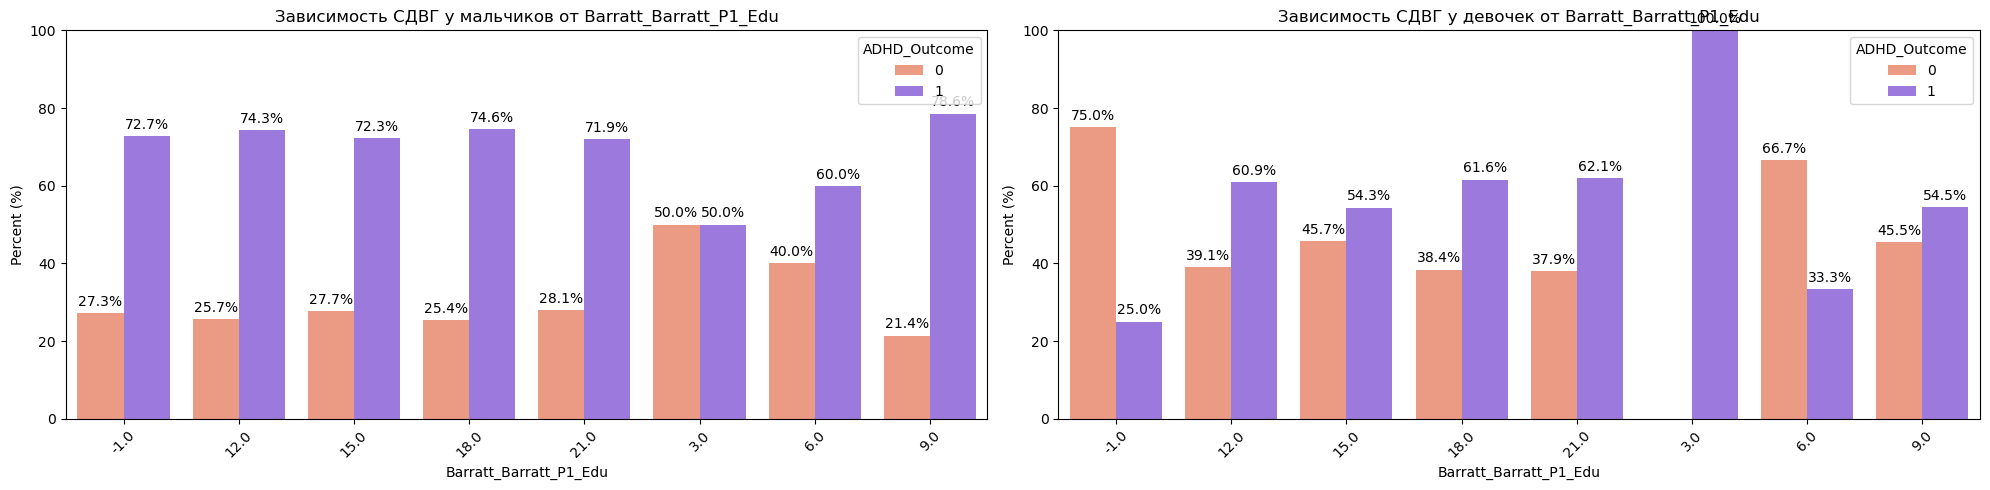

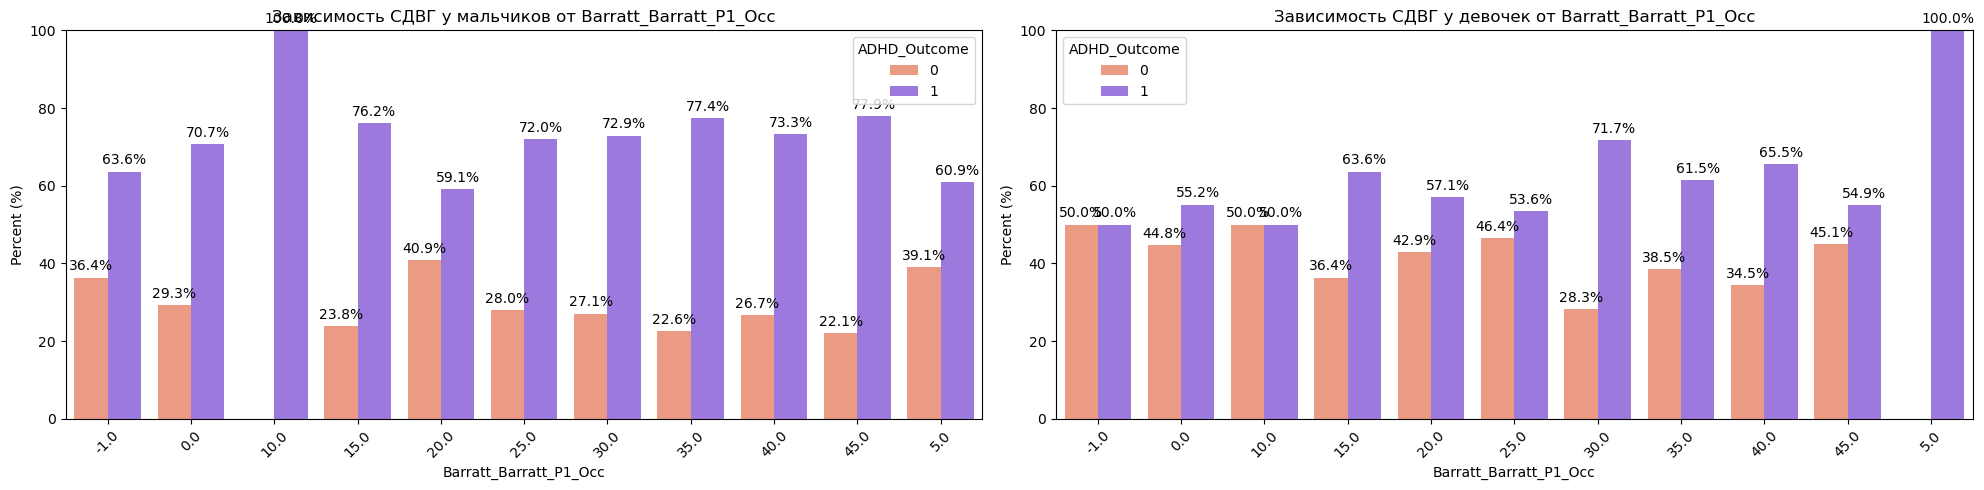

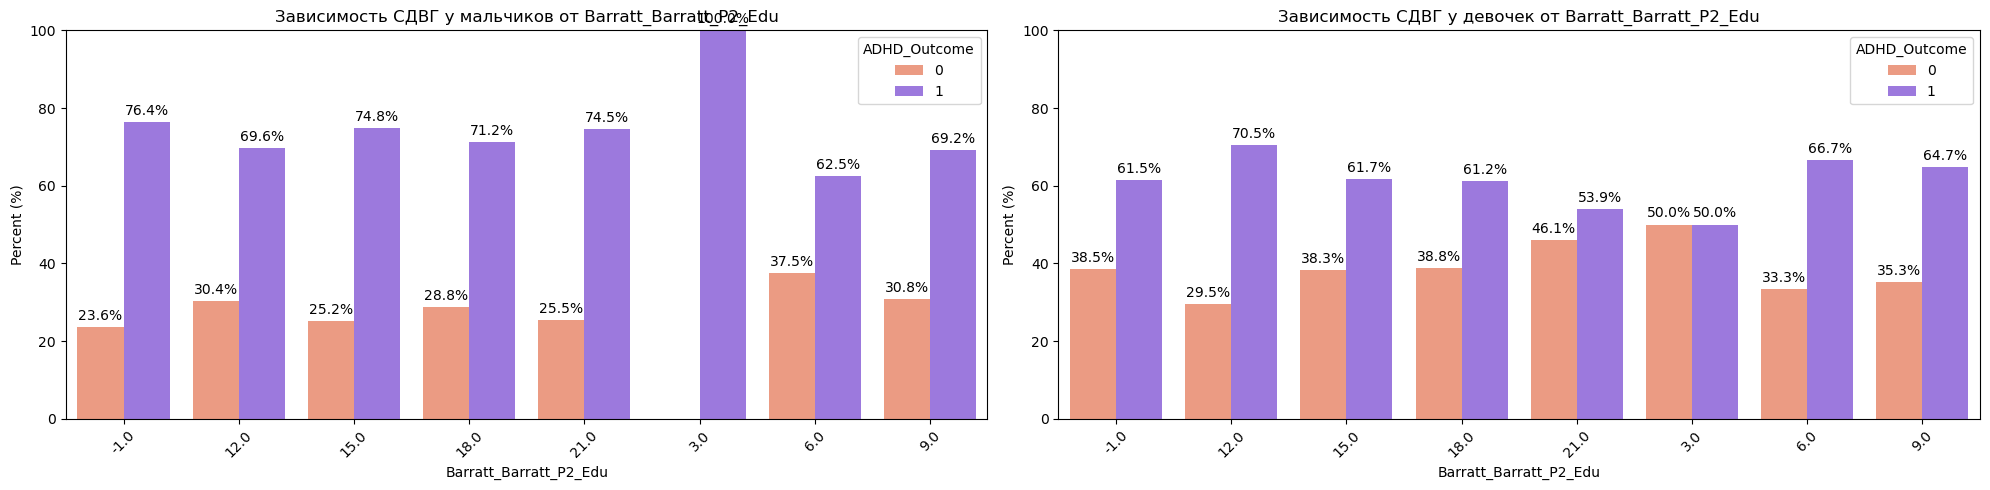

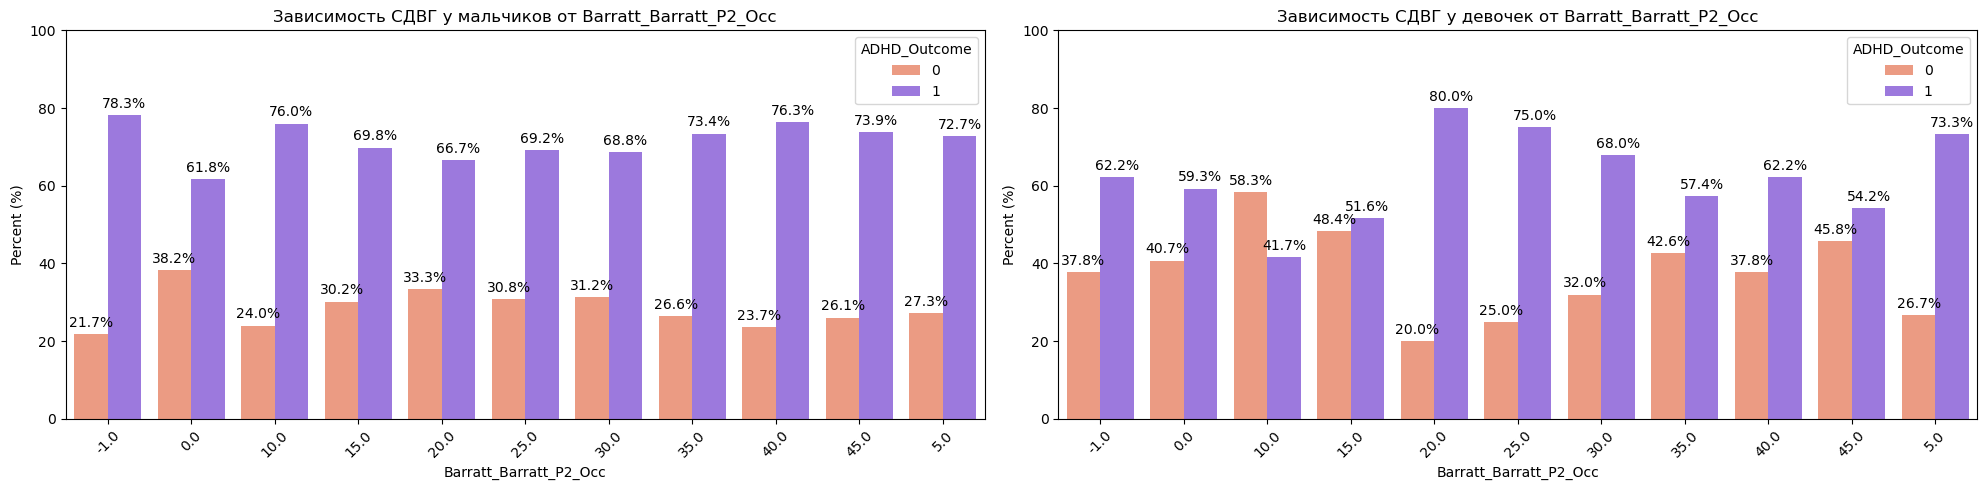

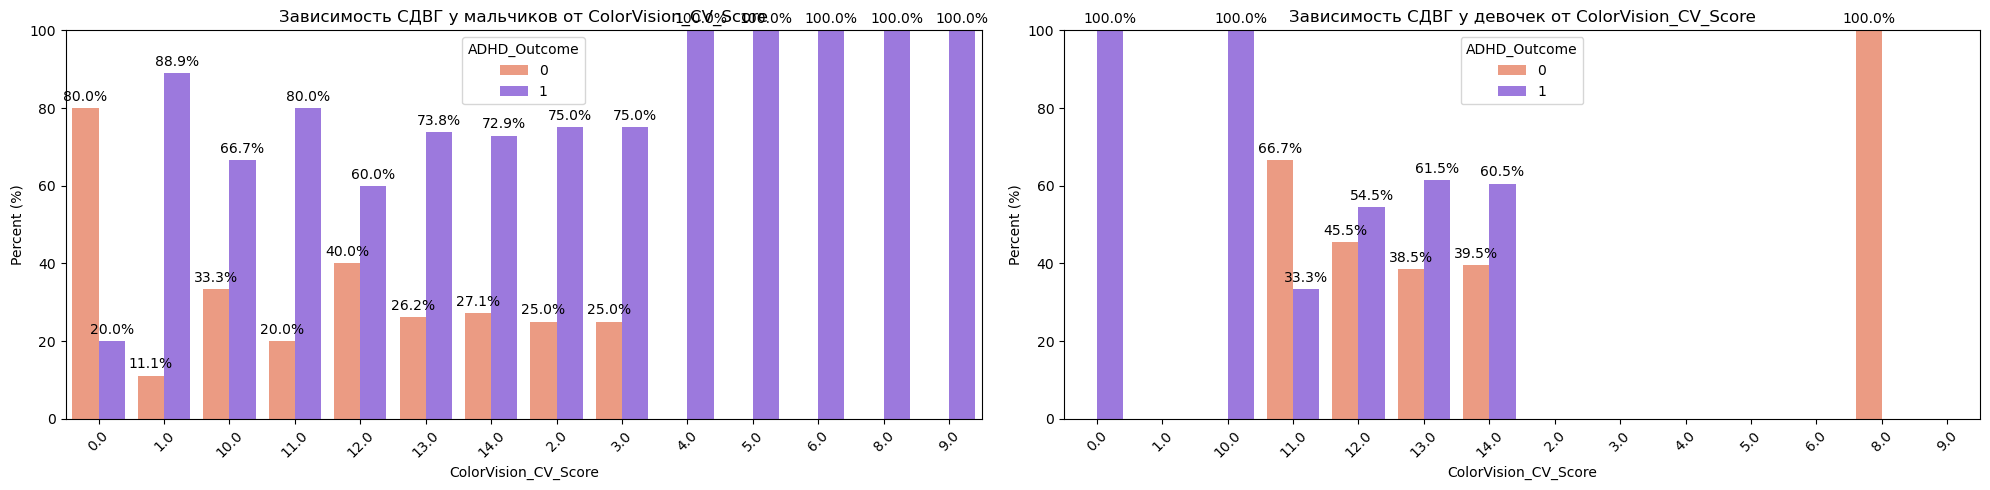

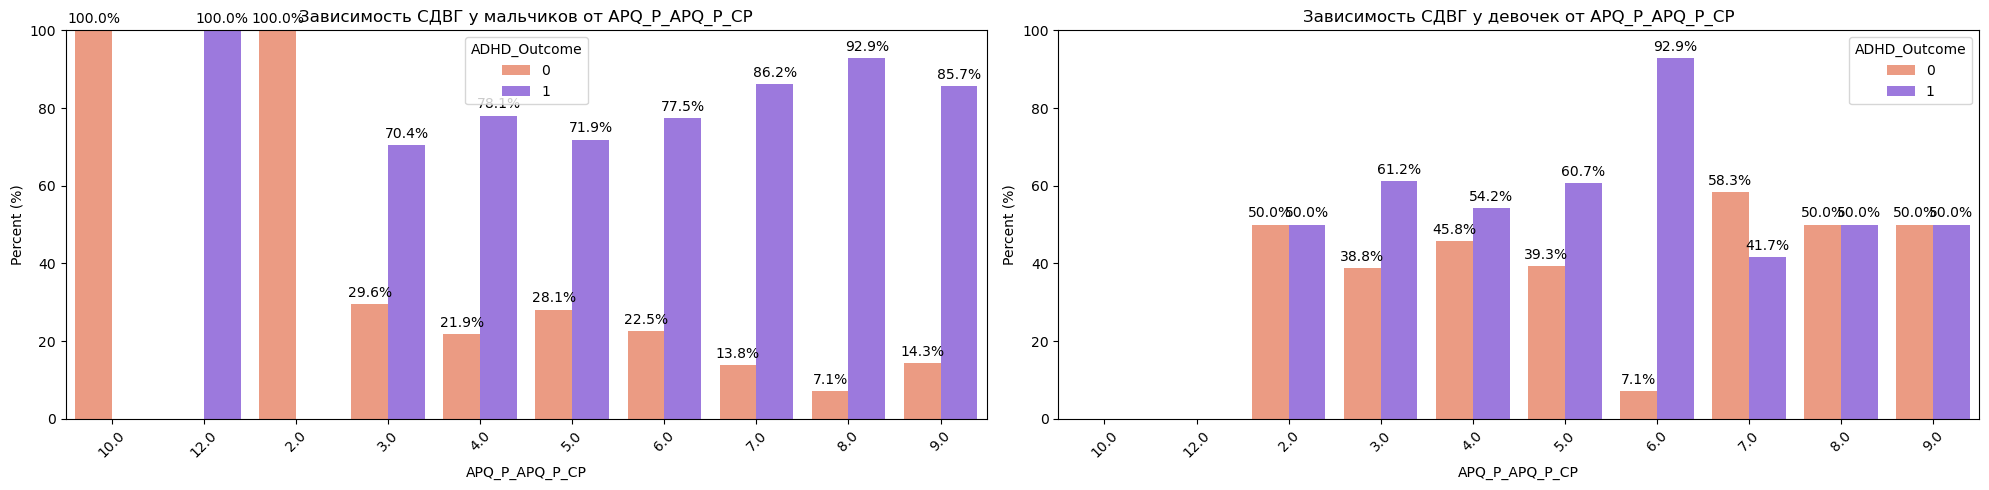

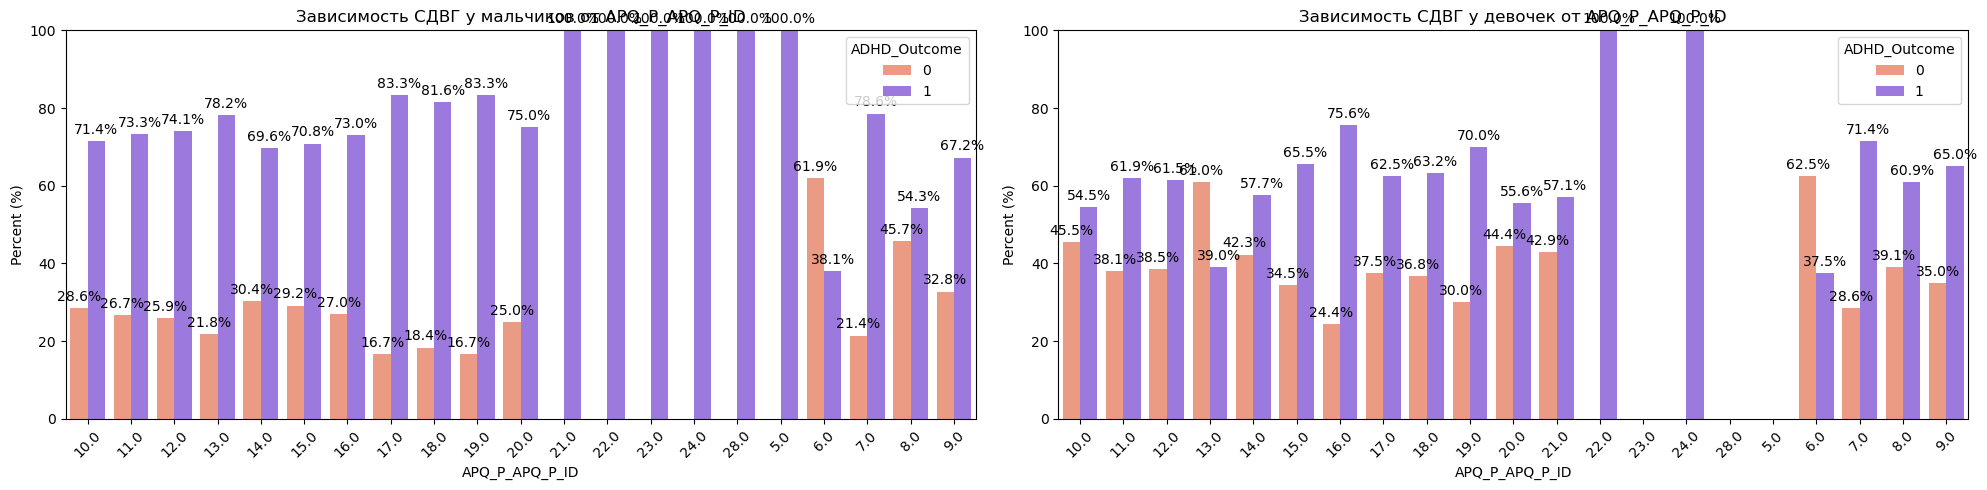

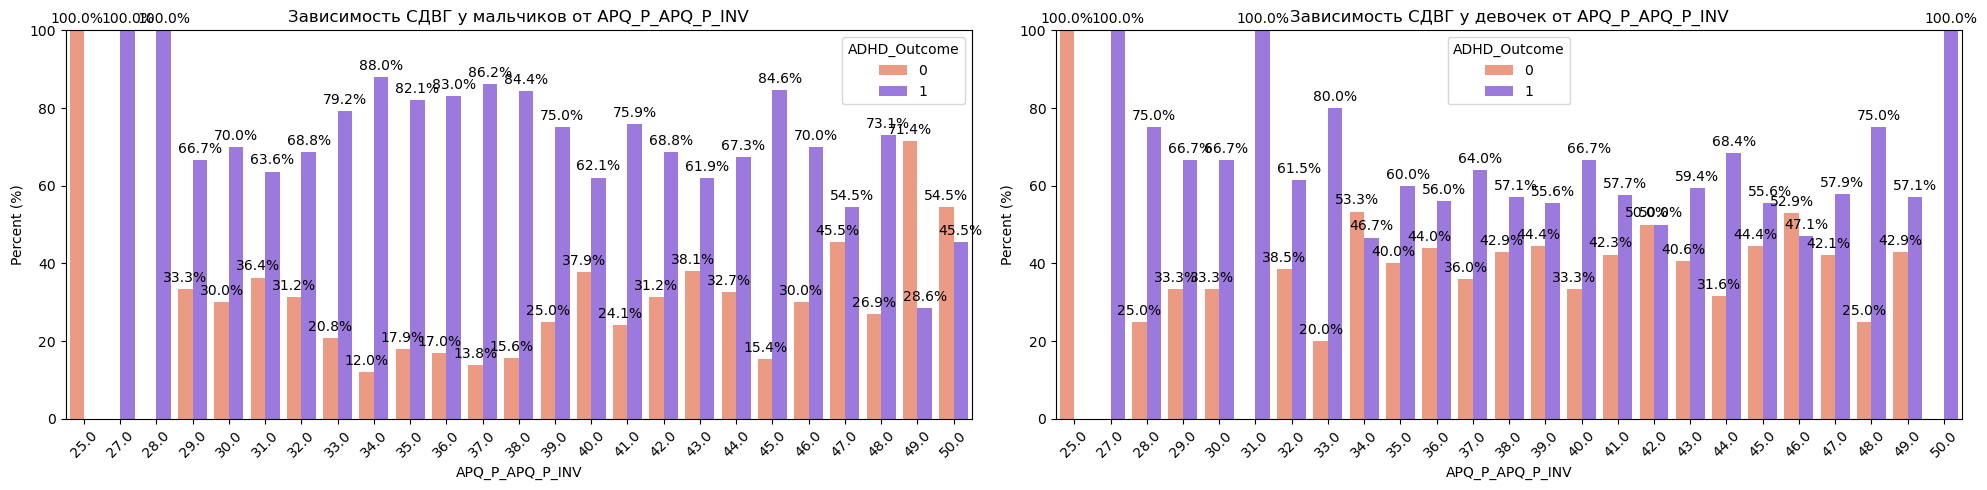

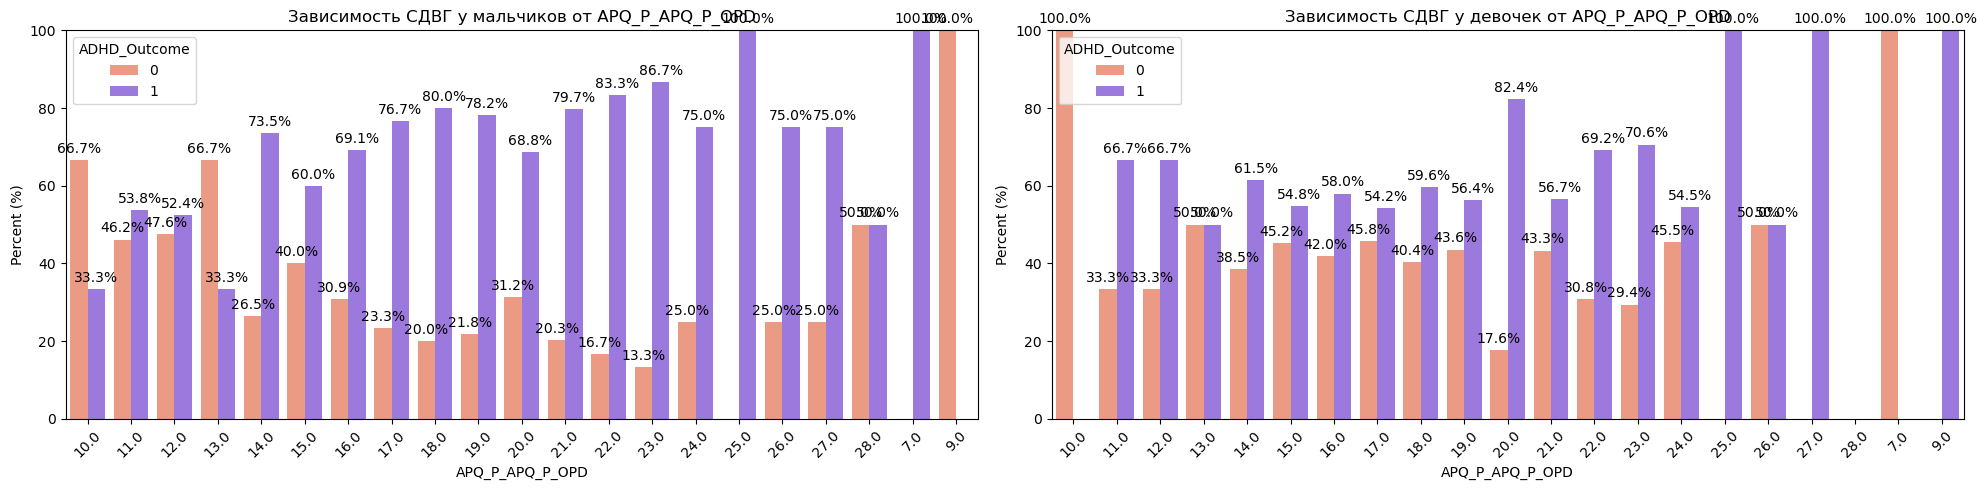

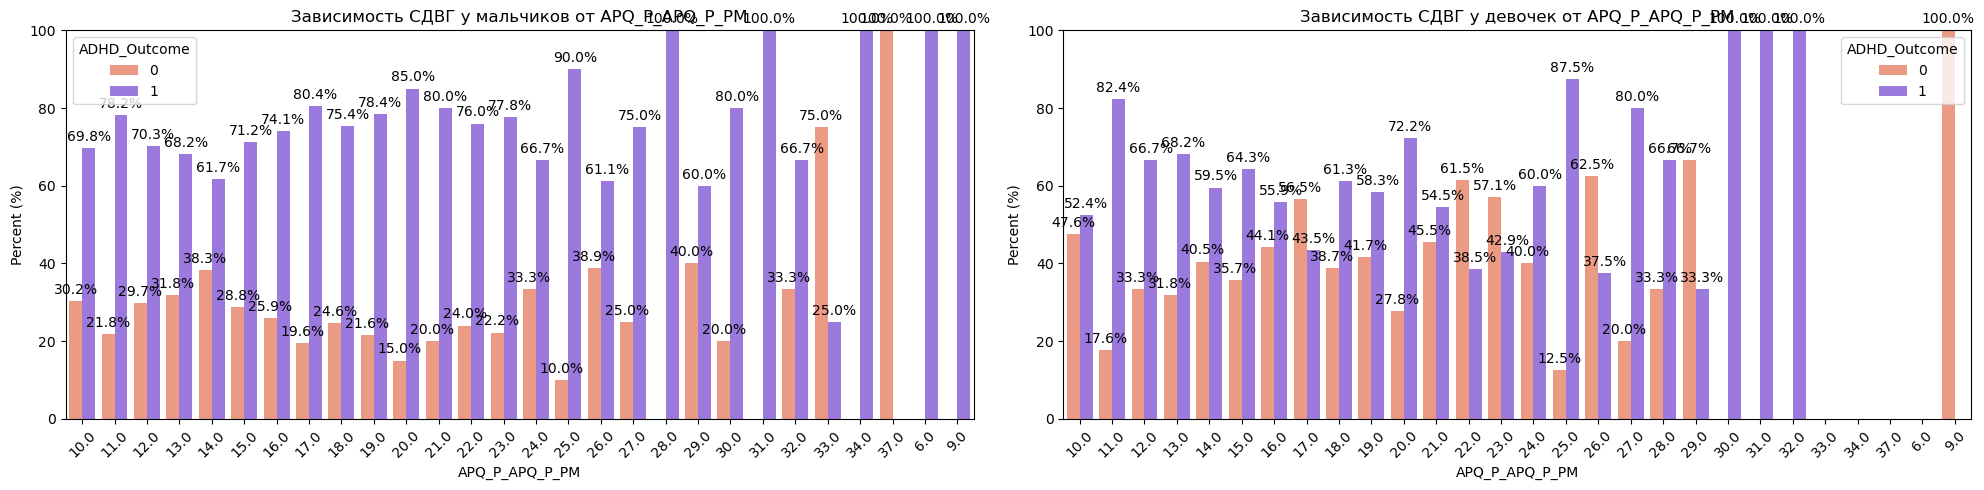

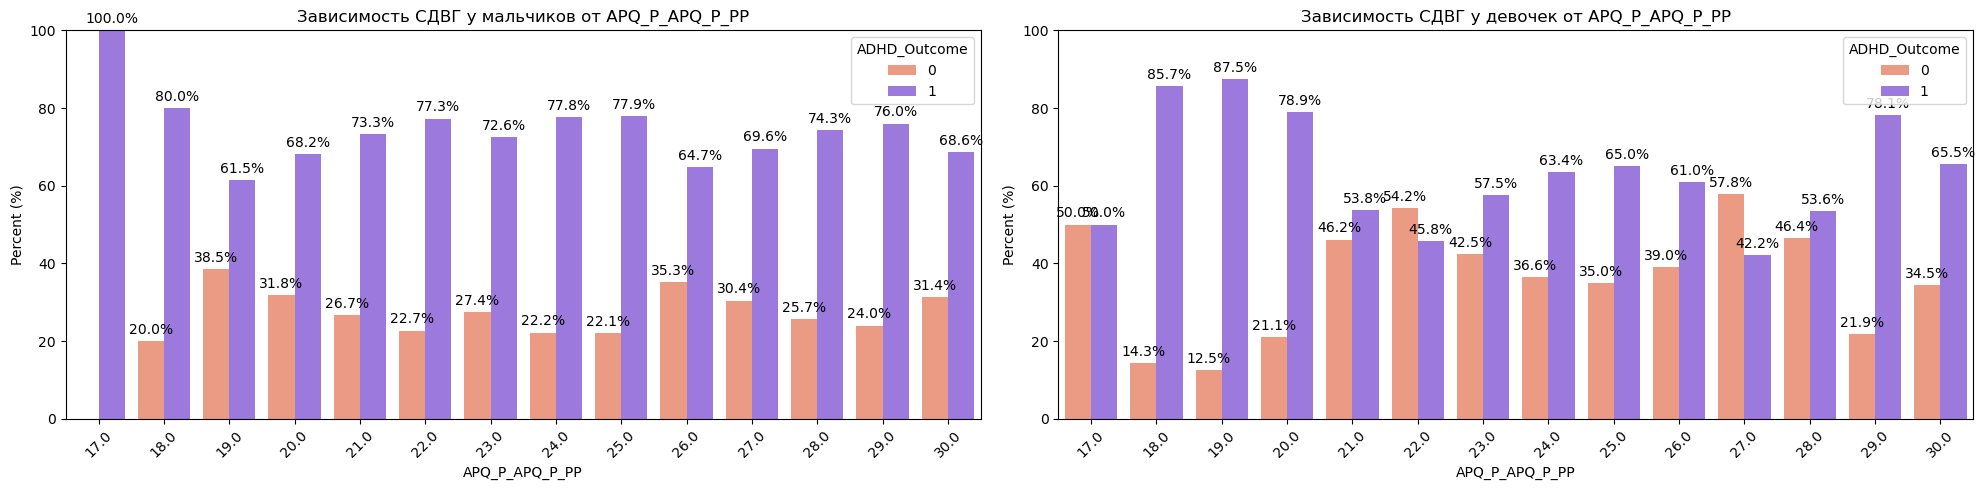

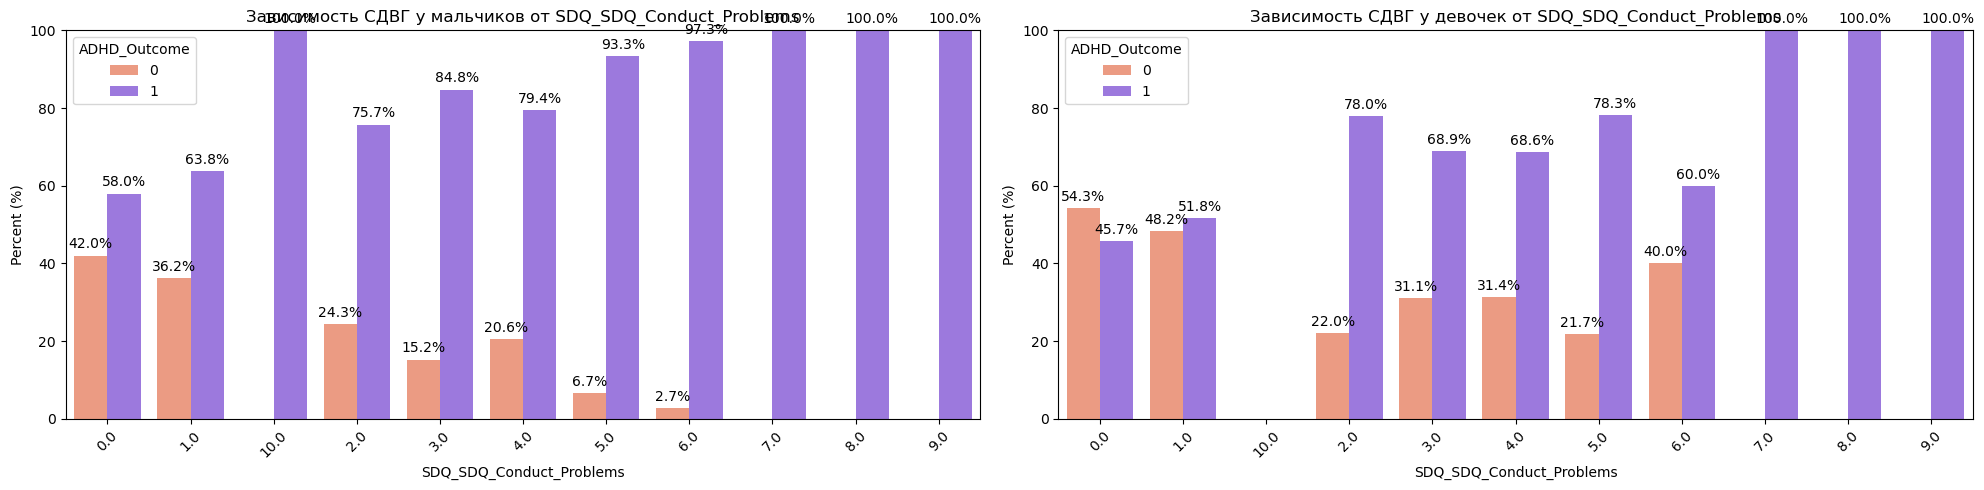

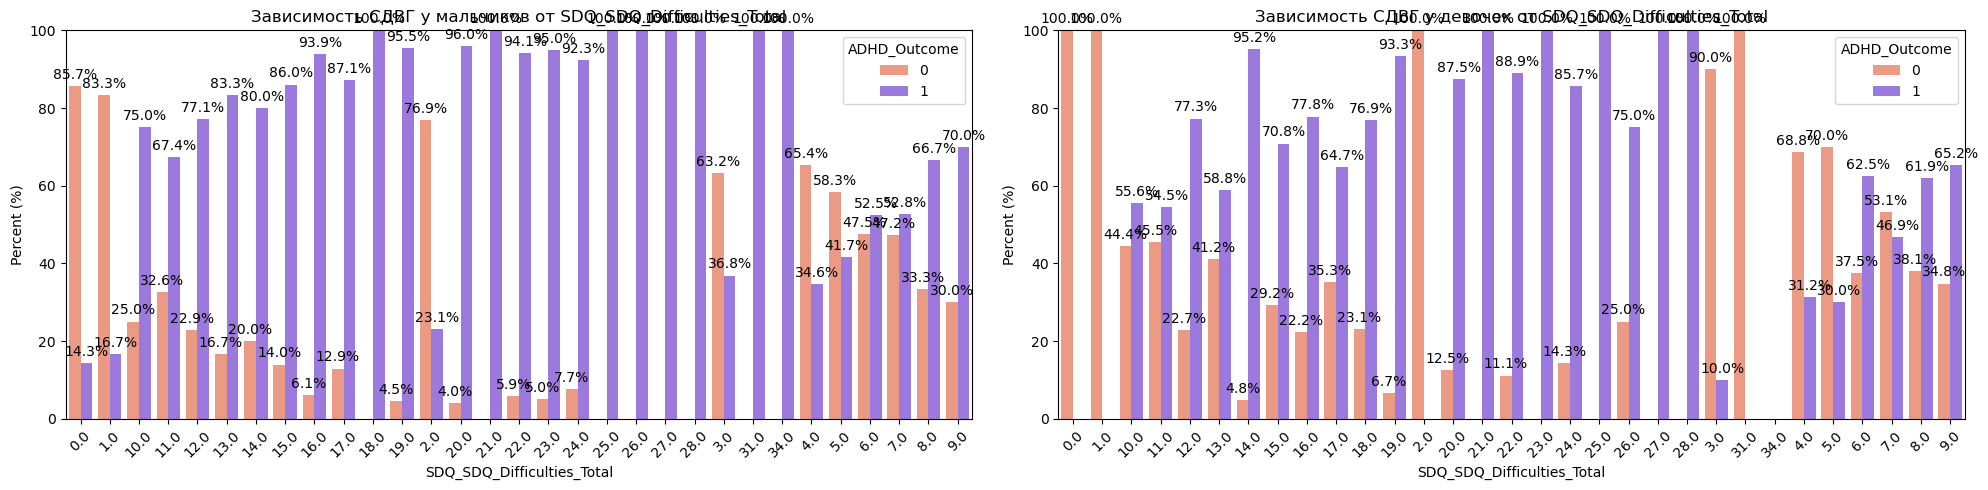

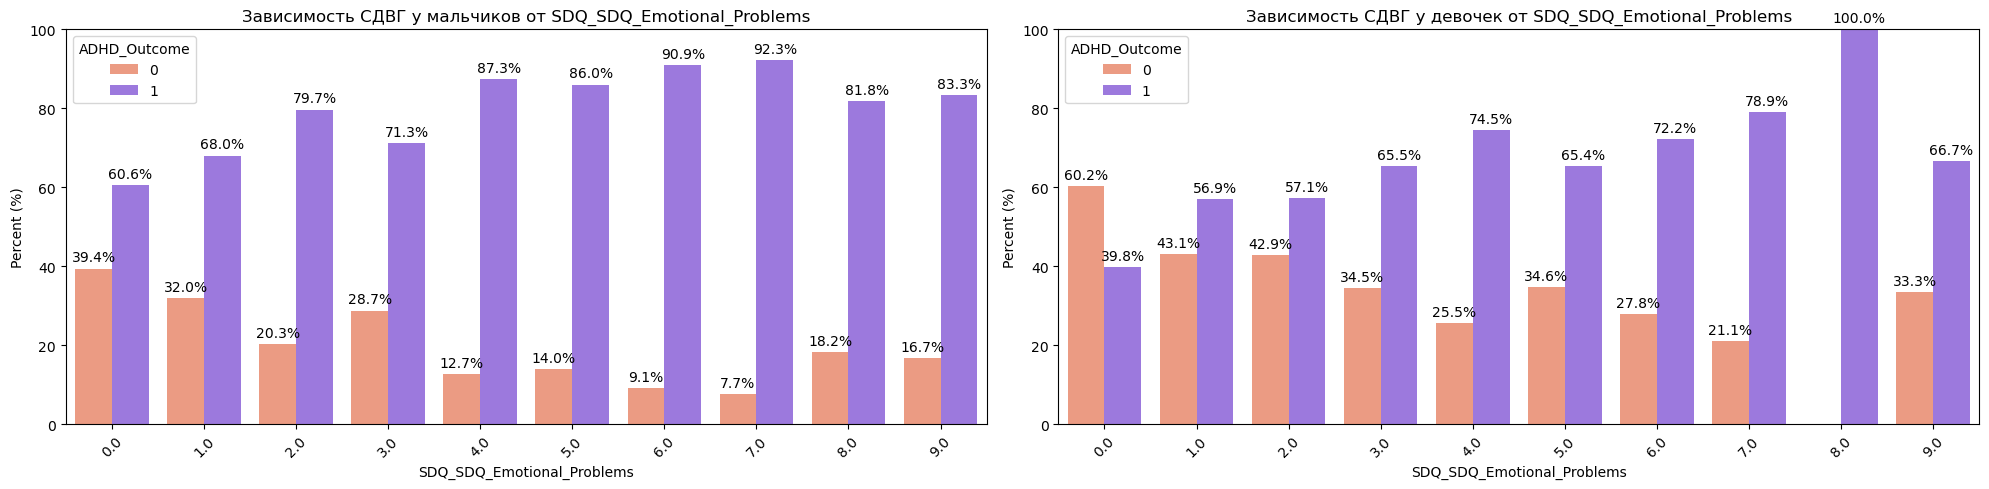

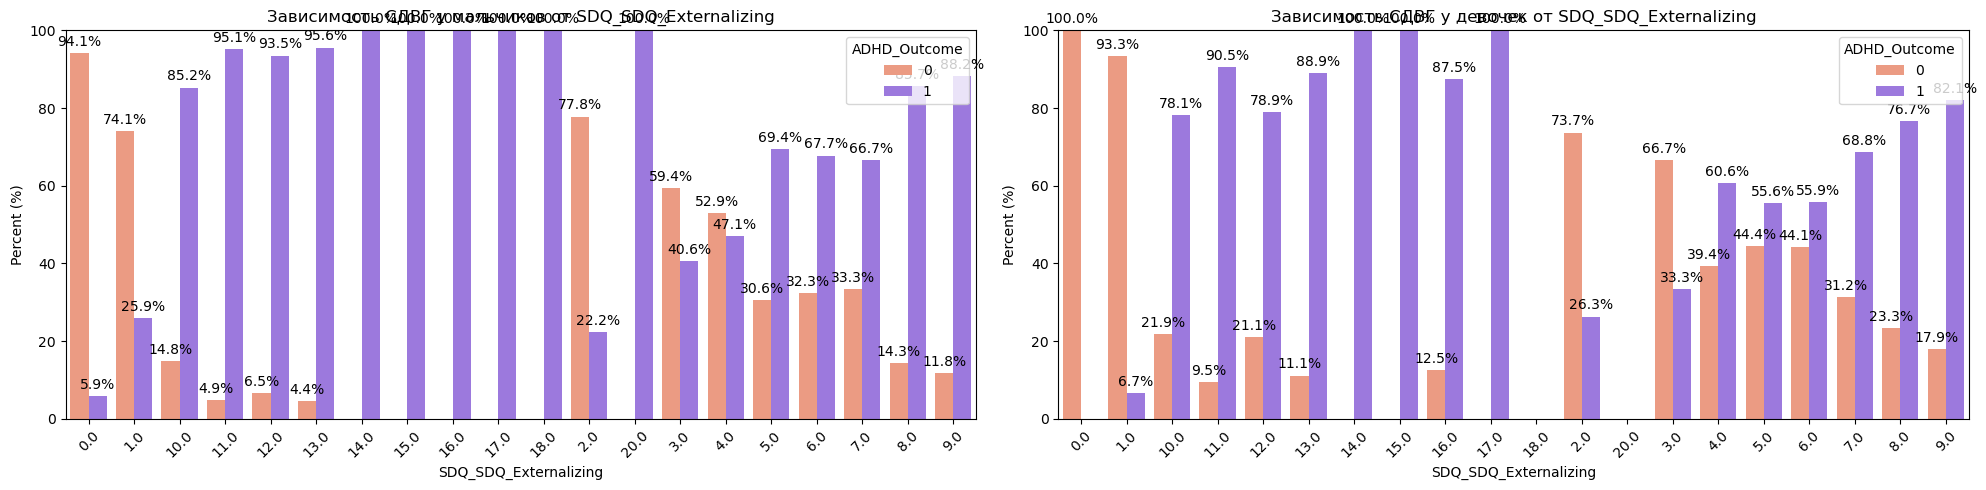

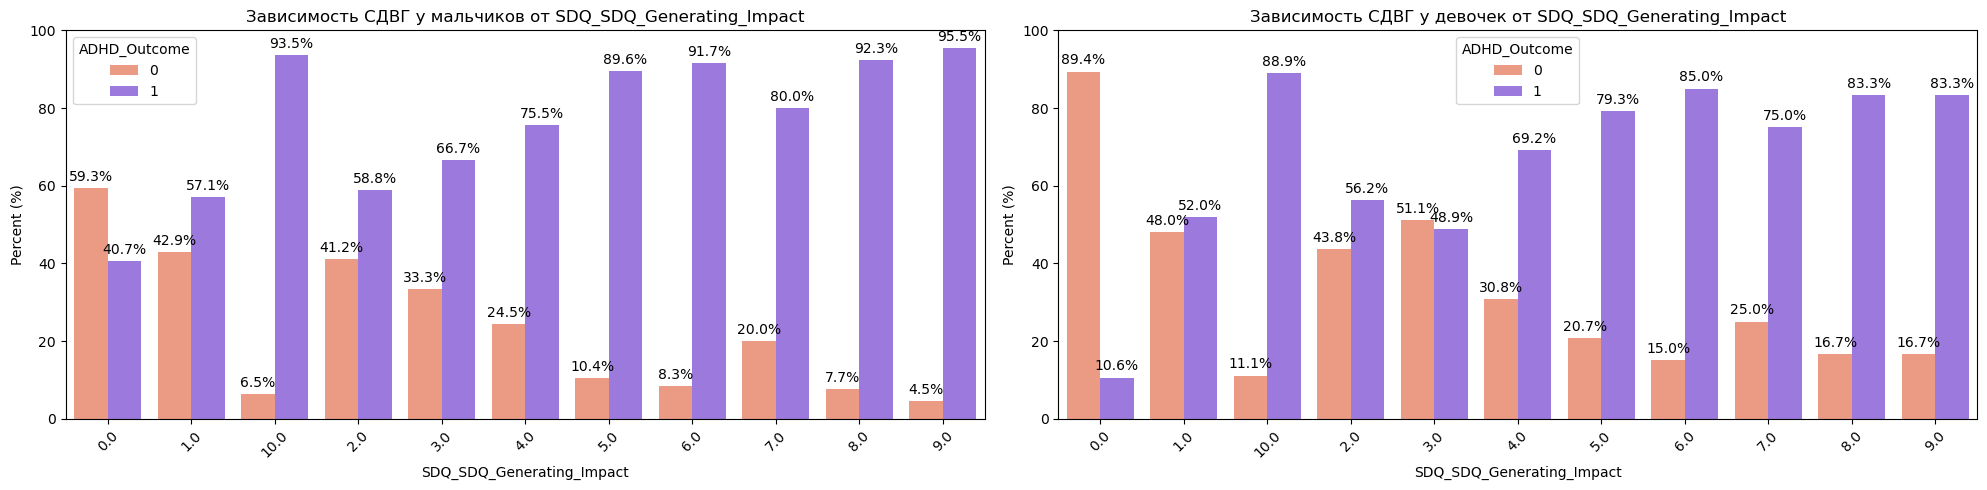

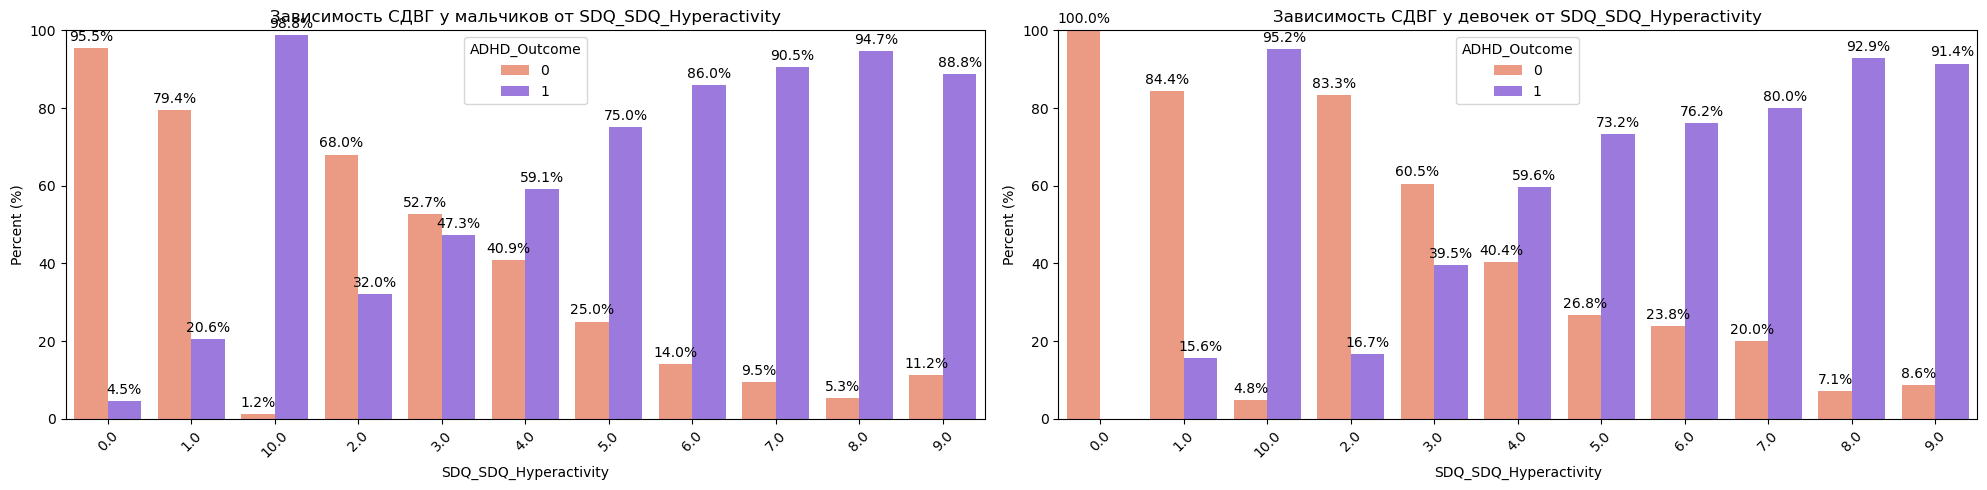

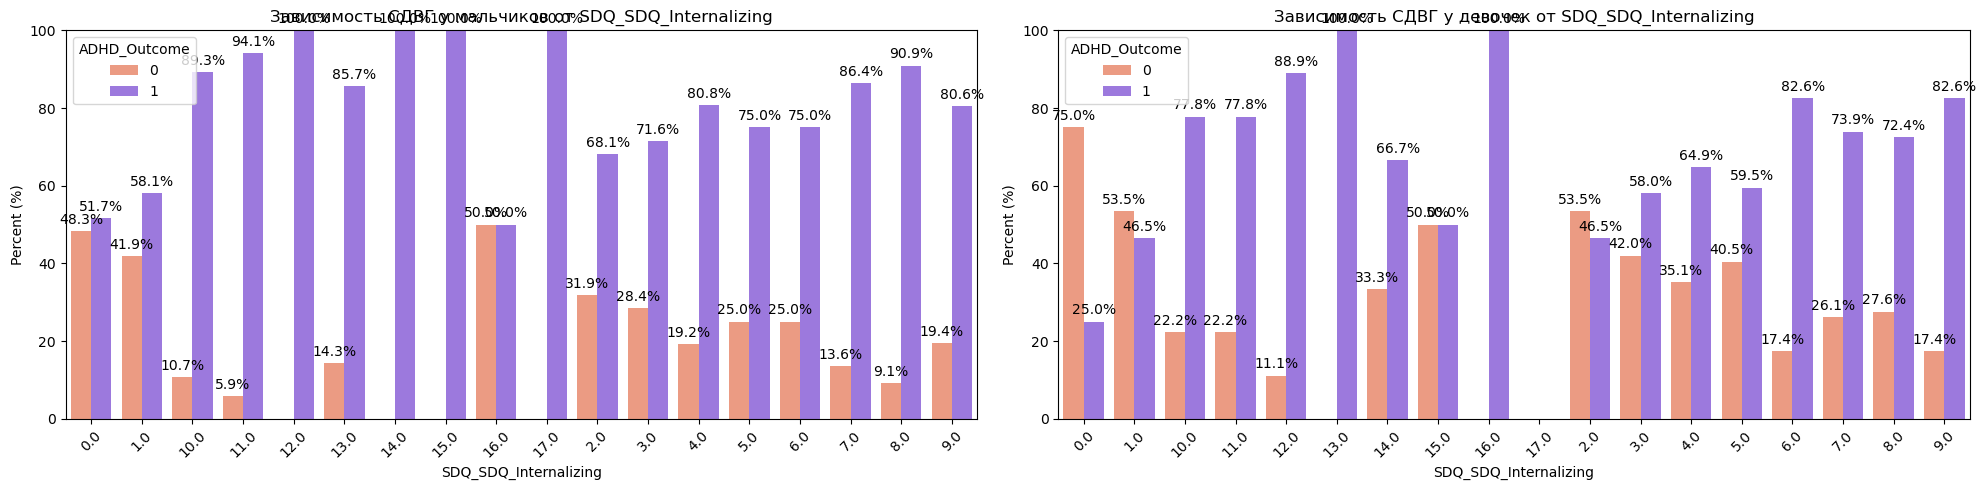

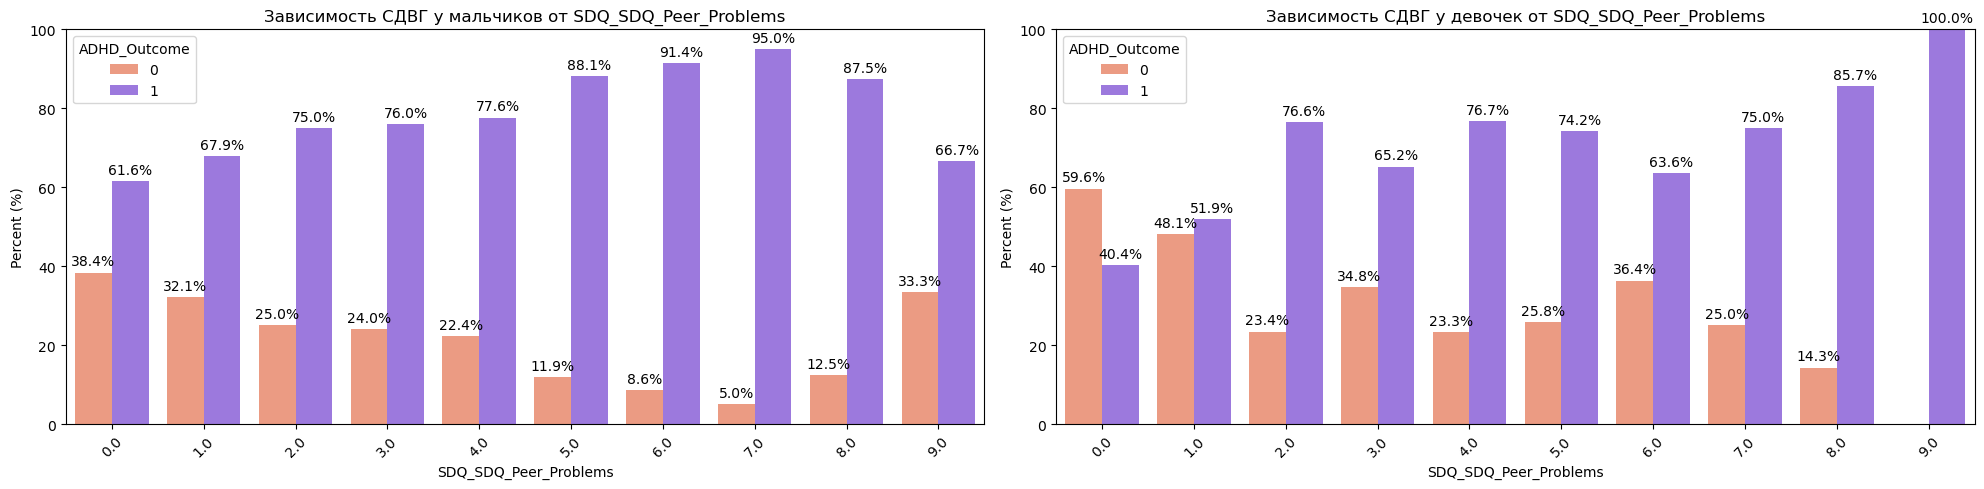

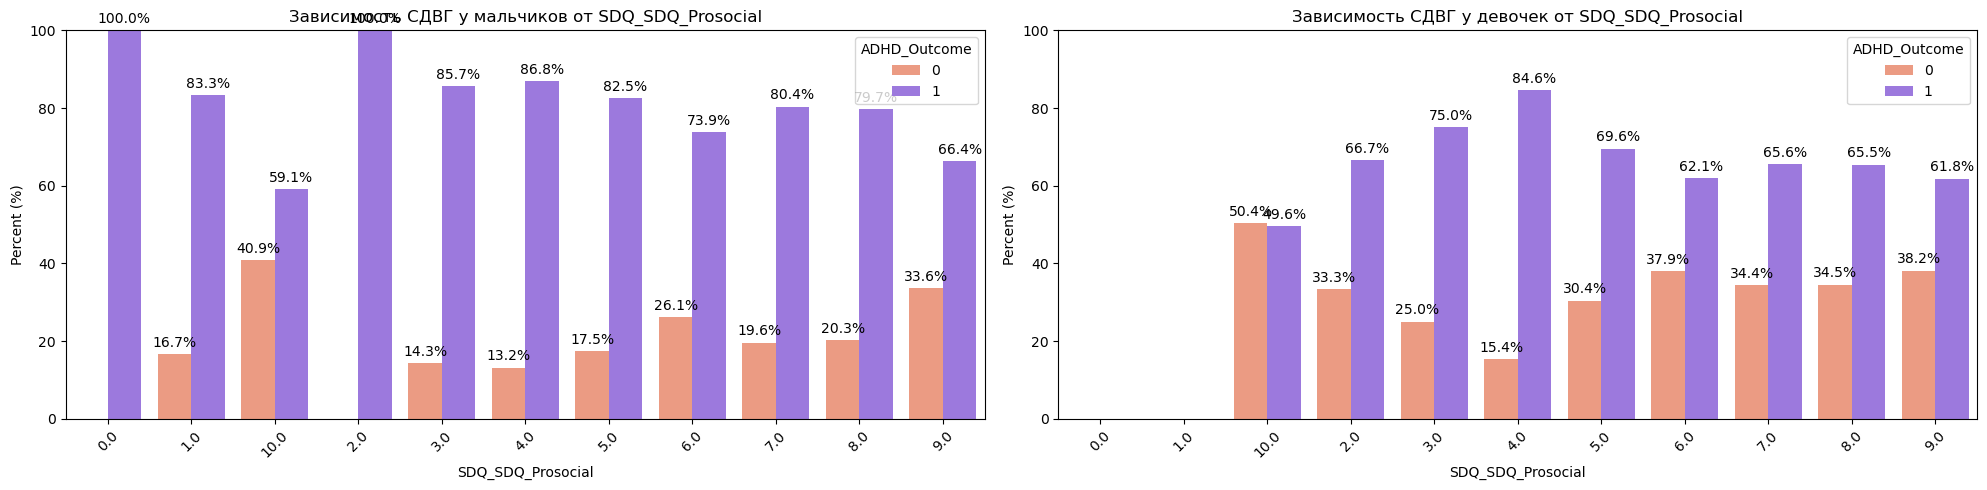

In [196]:
def plot_percent_by_cat(data, col, target_col, palette, ax, title, order=None, hue_order=None):
    # Копия данных, приводим col и target_col к строкам (чтобы типы совпадали)
    df = data.copy()
    df[col] = df[col].astype(str)
    df[target_col] = df[target_col].astype(str)

    # Если order не задан — возьмём отсортированные уникальные значения col
    if order is None:
        order = sorted(df[col].unique())
    else:
        # Убедимся, что order — список строк
        order = list(map(str, order))
        
    # Если hue_order не задан — возьмём отсортированные уникальные значения target_col
    if hue_order is None:
        hue_order = sorted(df[target_col].unique())
    else:
        hue_order = list(map(str, hue_order))

    # Подсчёт количества в каждой группе
    counts = df.groupby([col, target_col]).size().unstack(fill_value=0)

    # Убедимся, что индексы и колонки counts соответствуют order и hue_order
    counts = counts.reindex(index=order, columns=hue_order, fill_value=0)

    # Считаем проценты внутри каждой категории col (сумма по target_col = 100%)
    denom = counts.sum(axis=1).replace(0, 1)  # чтобы не делить на ноль
    percents = counts.div(denom, axis=0) * 100

    # Преобразуем в длинный формат для seaborn
    long = percents.reset_index().melt(id_vars=col, var_name=target_col, value_name='percent')

    sns.barplot(
        data=long, x=col, y='percent', hue=target_col,
        order=order, hue_order=hue_order, palette=palette, ax=ax, ci=None
    )

    # Добавляем подписи процентов над барами
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2, height),
                ha='center', va='bottom',
                xytext=(0, 3),
                textcoords='offset points',
                fontsize=10
            )

    ax.set_ylim(0, 100)
    ax.set_ylabel("Percent (%)")
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title=str(target_col))

def sorted_categories(cat_list):
    unique_vals = list(set(cat_list))
    try:
        nums = list(map(int, unique_vals))
        sorted_vals = list(map(str, sorted(nums)))
    except:
        sorted_vals = sorted(unique_vals)
    return sorted_vals

for col in cat_cols:
    fig, axes = plt.subplots(ncols=2, figsize=(20, 5))
    
    # Приводим категории к строкам и сортируем
    cats = df_m[col].astype(str).unique()
    order = sorted_categories(cats)

    plot_percent_by_cat(
        df_m, col, target_col,
        palette=["#fc9272", "#9768ee"], ax=axes[0],
        title=f"Зависимость СДВГ у мальчиков от {col}",
        hue_order=[0, 1],
        order=order
    )

    plot_percent_by_cat(
        df_f, col, target_col,
        palette=["#fc9272", "#9768ee"], ax=axes[1],
        title=f"Зависимость СДВГ у девочек от {col}",
        hue_order=[0, 1],
        order=order
    )

    plt.tight_layout()
    plt.show()

Год регистрации:
- Количество мальчиков росло до 2018 года, также как и у девочек, в 2019 году немного уменьшилось
- Количество тех детей у которых нет сдвг практически не менялось за все время, как у мальчиков, так и у девочек в районе 40 человек
.
- Количество мальчиков с СДВГ выросло с 2016 до 2018 года в 4 раза с 60 человек до 210, в 2019 году уменьшилось на 50 человек. Если смотреть в процентах, то можно увидеть что в 2016 году 55.6 %, а в 2018 80.4%, т.е. увеличилось на 24.8% постановления диагноза СДВГ
- Количество девочек с СДВГ также росло, но темп роста не такой сильный, в 2016 году больше девочек было без СДВГ, потом постепенно эта разница менялась в противоположную сторону и в 2018 году, количество девочек с СДВГ было в 2 раза больше, чем без, в процентах увеличилось на 26.4%. В 2019 году разница увеличилась на 6,1% по сравнению с предыдущим годом

Место тестирования:
- В Статен-Айленд мы видим самое большое количество детей, у мальчиков в 2,5 раза большьше ставили диагноз СДВГ, чем не ставили, на 39.6%
- В этом же месте у девочек разница всего лишь в 1,2 раза в пользу СДВГ на 11,2%
- В MRV у мальчиков на 71.4% больше ставят диагноз, чем нет
- В MRV у девочек на 50% больше ставят диагноз, чем нет
- В Харлеме аналогично с MRV, что у мальчиков, что у девочек

Этнос ребенка:
- Вне зависимости от этноса мальчиков практически всегда в 3 раза больше с СДВГ, чем нет
- Вне зависимости от этноса девочек практически всегда в 1,5 раза больше с СДВГ, чем нет

Раса ребенка:
- У мальчиков имеющих 2 или более рас, диагностировали СДВГ примерно в 2 раза чаще, чем нет. В остальных случаях в 3 раза
- У девочек диагностируют СДВГ в 1,5 раза чаще, чем нет. 

Место сканирования:
- В Staten Island менее часто ставили диагноз СДВГ, чем в других местах
- В CBIC чаще всего ставили СДВГ
  
Уровень образования родителя 1:
- В основном у всех детей родитель 1 имеет высшее образование или ученую степень
- У мальчиков, чем выше образование родителя 1, тем реже диагностируют СДВГ
- У девочек, наоборот
  
Профессия родителя 1:
- У мальчиков чаще всего диагностируют СДВГ, если родитель 1 имеет профессию:  Медсестра, квалифицированный техник, медицинский техник, консультант, менеджер, сотрудник полиции и пожарной охраны, финансовый менеджер, физиотерапевт, трудотерапевт, логопед.
- У мальчиков меньше всего диагностируют СДВГ, если родитель 1 имеет профессию: Автомеханик, машинистка, слесарь, фермер, плотник, администратор, строитель, парикмахер.
- У девочек чаще всего диагностируют СДВГ, если родитель 1 имеет профессию: также как и у мальчиков, и дополнительно: Инженер-механик, инженер-атомщик и инженер-электрик, администратор в сфере образования, ветеринар, военный офицер, учитель начальной и средней школы, а также преподаватель специального образования.
- У девочек меньше всего диагностируют СДВГ, если родитель 1 имеет профессию: Машинист, музыкант, бухгалтер, секретарь, страховой агент, краснодеревщик, специалист по кадрам, сварщик, Врач, адвокат, профессор, инженер-химик и аэрокосмический инженер, судья, генеральный директор, старший менеджер, государственный служащий, психолог, фармацевт, бухгалтер.

Уровень образования родителя 2:
- Чем выше уровень образования родителя 2, тем больше детей участвовует в диагностике
- У мальчикам ставят СДВГ в 69% случаях до 74.8%, чем выше образование, тем скорей всего будет СДВГ
- У девочек ставят СДВГ в диапазоне с 53.9% случаях до 70.5%, чем ниже образование, тем скорей всего будет СДВГ

Профессия родителя 2:
- У мальков не сильно зависит от профессии родителя 2 наличие СДВГ, небольшой есть рост в сторону СДВГ, если более сложная профессия
- У девочек самое большое количество СДВГ, если родитель 2 имеет профессию: Автомеханик, машинистка, слесарь, фермер, плотник, администратор, строитель, парикмахер.
- У девочек самое маленькое количество СДВГ, если родитель 2 имеет профессию: Сборщик мусора, повар быстрого приготовления, водитель такси, продавец обуви, рабочий сборочной линии, каменщик, носильщик багажа.
- Так же у девочек прослеживается тенденция к уменьшению диагностирования СДВГ, если родитель имеет более сложную профессию

Результат теста на цветовое зрение:
- Большинство детей имеют результ 14 и немного 13, остальных результатов единицы
- У мальчиков вне зависимости от результата, СДВГ ставят в 73% случаях
- У девочек аналогично в 61% случае

Оценка телесных наказаний:
- Большинство детей телесно наказывают на 3 балла и все меньше и меньше дальше
- У мальчиков СДВГ меньше всего ставилось, если было 3 балла в 70.4% случаях, и чем больше тем больше процент возникновения СДВГ в 8 баллов можно увидеть 92,9%, и есть немного понижение в 9 баллах на 7.2%
- У девочек меньше всего диагностировали СДВГ, если телесные наказания были на 7 баллов 41.7%, также показалив районе 50% были у 2, 4, 8, 9 баллов
- У девочек больше всего диагностировали СДВГ, когда было 6 баллов в 92,9% случаев, 3 и 5 баллов 61%

Непостоянная оценка дисциплины:
- Распределение по этому признаку нормальное, что у мальчиков, что у девочек
- У мальчиков с повышением баллов СДВГ увеличивает постепенно с 54.3% до 83.3%
- У девочек с повышением баллов ничего особо не меняется все в пределах 60% (+-10%)

Оценка вовлеченности:
- Распределения нормальные
- У мальчиков с 29 баллов по 32 балла 70% СДВГ, с 33 балла по 39 далл 80% СДВГ, с 40 баллов в районе 70% СДВГ
- У девочек все приблизительно одинаковое в районе 60%, если некоторые выбросы, где 33 балла, там 80%, 28 и 48 баллов, там 75%

Оценка других дисциплинарных практик:
- Распределение нормальное
- У мальчиков возрастает процент СДВГ до 23 баллов с 33.3% до 86.7% дальше идет на снижение до 75%, т.е. чем больше баллов, тем вероятнее СДВГ
- У девочек стабильно варьируется с 50% до 70% вне зависимости от баллов, есть повышенный процент на 20 баллах 82.4%

Плохая оценка мониторинга/надзора:
- Количество детей постепенно уменьшается, чем больше баллов. Есть небольшая просадка с 11 до 14 баллов
- У мальчиков с 11 до 14 баллов процент уменьшается с 78.2% до 61.7%, потом идет на повышение до 20 баллов 85%, дальше снова уменьшается до 26 баллов 61.1%, но, где 25 баллов есть резко высокое значение 90%
- У девочек с 11 до 17 баллов процент уменьшается с 82.4% до 38.7%, потом идет на повышение до 20 баллов 72%, дальше снова уменьшается до 26 баллов 37.5%, но, где 25 баллов есть резко высокое значение 87.5%

Положительная оценка родительского воспитания:
- Распределение похоже на нормальное, но немного смещено вправо
- У мальчиков до 25 баллов СДВГ держиться на 77%, когда 26 баллов уже 64.7% и возрастает до 29 баллов до 76%, немного ниже у 30 баллов 68.6%
- У девочек с 22 баллов до 25 баллов СДВГ постепенно возрастает с 45.8% до 65%, потом до 27 былло идет на спад до 42.2%, с 28 начинает возрастать до 78.1% и если 30 баллов 65.5%
- У девочек на 22 балле можно увидеть, что без СДВГ больше, чем с ним на 8.4%

Масштаб проблем поведения:
- Количество всех детей идет на уменьшение с возрастанием баллов
- Начиная с 7 баллов, нет детей без СДВГ
- У мальчиков чем больше баллов, тем вероятнее СДВГ возрастает с 58% до 100%
- У девочек аналогично, возрастает с 45.7% до 100%

Общая оценка сложности:
- У всех детей с возрастанием сложности, увеличивается процент СДВГ
- У мальчиков чуть пораньше, чем у девочек
- У мальчиков с 0 баллов до 34 баллов идет возрастание с 14.3% до 100%
- У девочек с 3 баллов до 28 баллов идет возрастание с 10% до 100%, с 1, 2 баллами девочки не встретились с СДВГ

Шкала эмоциональных проблем:
- Количество детей уменьшается с возрастанием баллов по шкале
- У мальчиков идет постепенное возрастание по всей шкале от 60.6% до 92.3%
- У девочек идет возрастание с 39.8% до 78.9%

Оценка экстернализации:
- И у мальчиков, и у девочек чем выше оценка, тем больше вероятность СДВГ

Генерация оценок воздействия:
-Чем больше баллов, тем вероятнее СДВГ у обоих полов

Шкала гиперактивности:
-Чем больше баллов, тем вероятнее СДВГ у обоих полов

Оценка интернализации: 
-Количество детей убывает постепенно с баллами
-Чем больше баллов, тем вероятнее СДВГ у обоих полов

Шкала проблем со сверстниками:
- Количество детей убывает с увеличением баллов
- У мальчиков с увеличение количества баллов, постепенно увеличивается процент СДВГ с 61.6% до 95%
- У девочек увеличивается ступенями, первая ступень с 0 до 2 баллов 40.4% до 76.6%, вторая ступень 3 по 5 баллов с 65.2% до 76.7%, третья ступень с 6 баллов и дальше с 63.6% до 100%

Просоциальная шкала: 
- Количество детей возрастает с баллами
- У мальчиков чем больше баллов, тем меньше СДВГ
- У девочек с 2 до 4 баллов СДВГ восрастает с 66.7% до 84.6%, после 4 баллов начинает убывать до 49.6%

## 2 Гипотеза

- Определённые диагнозы в категориальных признаках сильно коррелируют с СДВГ у девочек

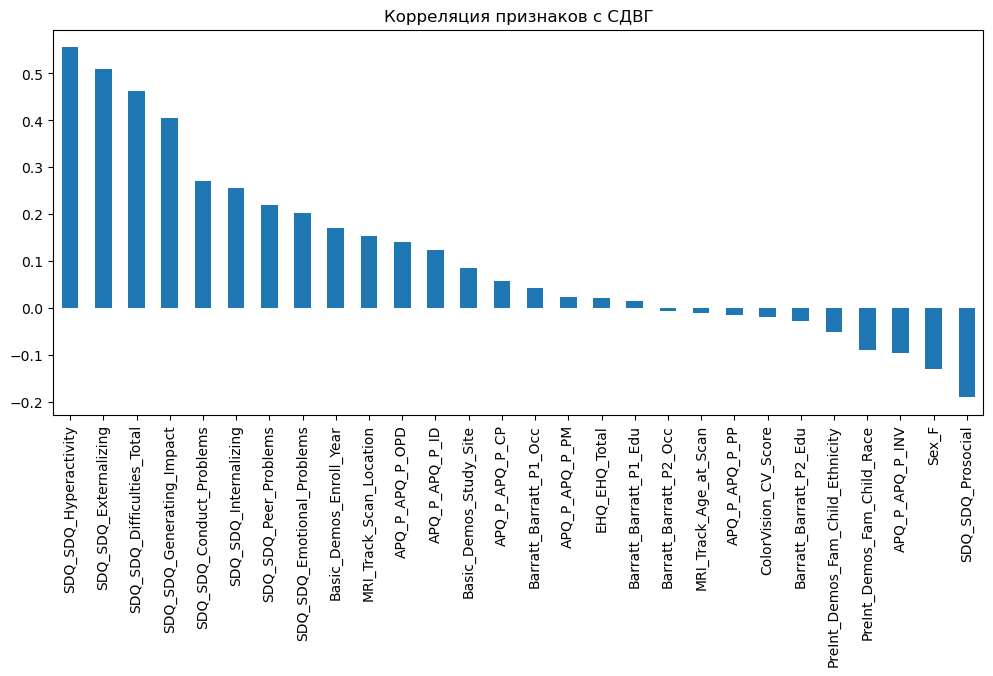

In [90]:
#Корреляция целевой переменной
corrs = df[quant_cols.tolist() + [target_col]].corr()[target_col].sort_values(ascending=False)
plt.figure(figsize=(12,5))
corrs[1:].plot(kind='bar')
plt.title('Корреляция признаков с СДВГ')
plt.show()

- На графике видно, что большим влиянием на СДВГ являются эмоционально/поведенческие признаки: Гиперактивность, экстернализация, общая сложность ребенка, насколько проблемы влияют на жизнь, проблемы в поведении, интернализация, дисциплина
- Также важно, что может влиять место диагностирования
- Видно, что твовлеченность родителей, женский пол и просоциальное поведение имеют меньше всего СДВГ

## 3 Гипотеза

- Образование родителей связанно с СДВГ у девочек

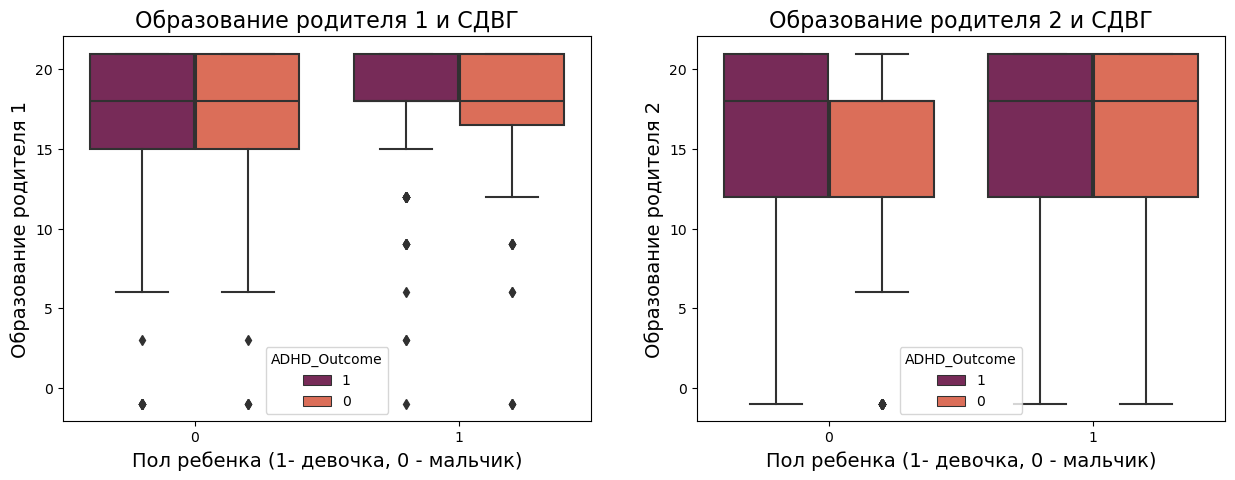

In [210]:
fig, axes = plt.subplots(ncols=2, figsize=(15, 5))
sns.boxplot(x='Sex_F', y='Barratt_Barratt_P1_Edu', hue='ADHD_Outcome',data=df, palette='rocket', ax=axes[0])

axes[0].set_title('Образование родителя 1 и СДВГ', fontsize=16)
axes[0].set_ylabel('Образование родителя 1', fontsize=14)
axes[0].set_xlabel('Пол ребенка (1- девочка, 0 - мальчик)', fontsize=14)

sns.boxplot(x='Sex_F', y='Barratt_Barratt_P2_Edu', hue='ADHD_Outcome',data=df, palette='rocket', ax=axes[1])

axes[1].set_title('Образование родителя 2 и СДВГ', fontsize=16)
axes[1].set_ylabel('Образование родителя 2', fontsize=14)
axes[1].set_xlabel('Пол ребенка (1- девочка, 0 - мальчик)', fontsize=14)

plt.show()

- для мальчика Образование 1 родителя никак не влияет, а образование 2 влияет, если второй родитель имеет ученую степень, то выше вероятность, что будет СДВГ
- для девочки образование 1 родителя влияет на то, что скорей всего не будет сдвг, если ниже ученой степени, а образование второго родителя не влияет

## 4 Гипотеза

- Профессия родителей связанно с СДВГ у девочек

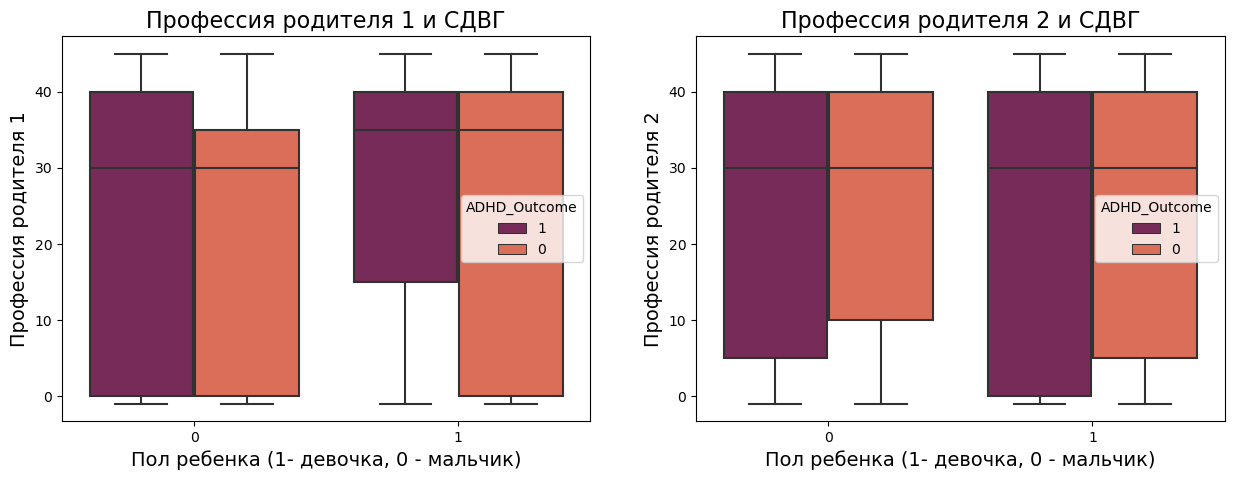

In [213]:
fig, axes = plt.subplots(ncols=2, figsize=(15, 5))
sns.boxplot(x='Sex_F', y='Barratt_Barratt_P1_Occ', hue='ADHD_Outcome',data=df, palette='rocket', ax=axes[0])

axes[0].set_title('Профессия родителя 1 и СДВГ', fontsize=16)
axes[0].set_ylabel('Профессия родителя 1', fontsize=14)
axes[0].set_xlabel('Пол ребенка (1- девочка, 0 - мальчик)', fontsize=14)

sns.boxplot(x='Sex_F', y='Barratt_Barratt_P2_Occ', hue='ADHD_Outcome',data=df, palette='rocket', ax=axes[1])

axes[1].set_title('Профессия родителя 2 и СДВГ', fontsize=16)
axes[1].set_ylabel('Профессия родителя 2', fontsize=14)
axes[1].set_xlabel('Пол ребенка (1- девочка, 0 - мальчик)', fontsize=14)

plt.show()

- У мальчиков, если родитель 1 работает по профессиям: Инженер-механик, инженер-атомщик и инженер-электрик, администратор в сфере образования, ветеринар, военный офицер, учитель начальной и средней школы, а также преподаватель специального образования, вероятность иметь СДВГ выше
- У девочек, если родитель 1 работает в менее серьезных профессиях иметь СДВГ вероятность ниже
- У мальчиков, если родитель два имеет менее образованную профессию, то вероятность СДВГ повышается
- У девочек, аналогичко

## 5 Гипотеза

- Склонность к трудностям в поведении коррелирует с СДВГ у девочек

In [21]:
df_0 = df[df.ADHD_Outcome == '0']
df_1 = df[df.ADHD_Outcome == '1']

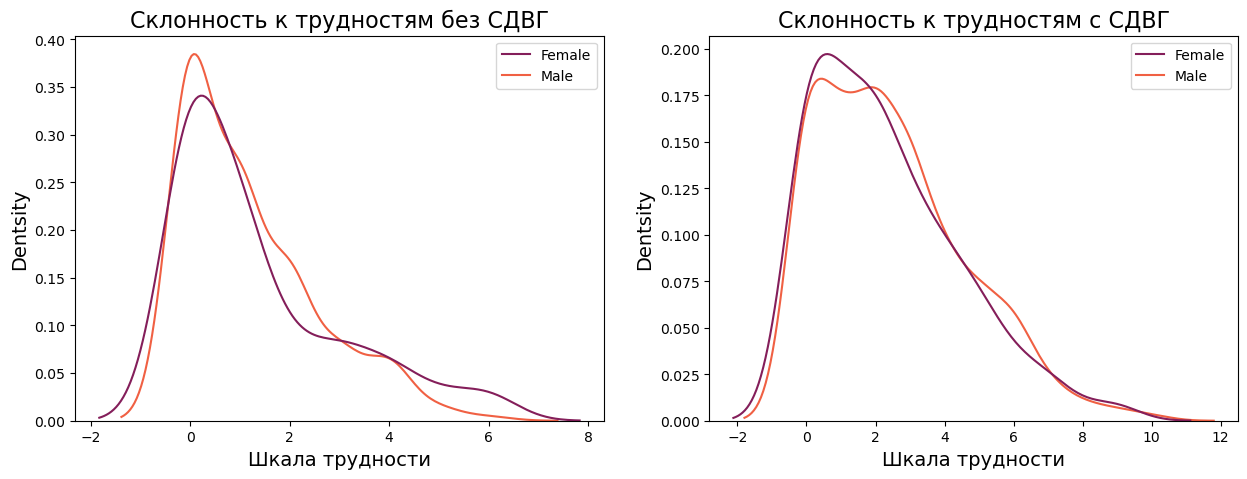

In [229]:
fig, axes = plt.subplots(ncols=2, figsize=(15, 5))

sns.kdeplot(
    data={
        "Female": df_0[df_0.Sex_F == '1'].SDQ_SDQ_Conduct_Problems,
        "Male": df_0[df_0.Sex_F == '0'].SDQ_SDQ_Conduct_Problems
    },
    common_norm=False,
    palette='rocket',
    ax=axes[0]
    )
axes[0].set_title('Склонность к трудностям без СДВГ', fontsize=16)
axes[0].set_xlabel('Шкала трудности', fontsize=14)
axes[0].set_ylabel('Dentsity', fontsize=14)

sns.kdeplot(
    data={
        "Female": df_1[df_1.Sex_F == '1'].SDQ_SDQ_Conduct_Problems,
        "Male": df_1[df_1.Sex_F == '0'].SDQ_SDQ_Conduct_Problems
    },
    common_norm=False,
    palette='rocket',
    ax=axes[1]
    )
axes[1].set_title('Склонность к трудностям с СДВГ', fontsize=16)
axes[1].set_xlabel('Шкала трудности', fontsize=14)
axes[1].set_ylabel('Dentsity', fontsize=14)
plt.show()

- На левом графике, количество детей без СДВГ имеют максимальную плотность в районе 0 баллов
- На левом графике, мальчиков имеющих 0 баллов больше, чем девочек. В районе 2 баллов мальчиков также больше, чем девочек. Но картина меняется после 4 до 8 баллов, девочек становится больше. То есть девочек у которых есть проблемы с поведением на 6 баллов их больше и им не ставили СДВГ
- На правом графике, количество детей имеющих СДВГ и имеющий 0-1 балл также больше, чем остальных детей имеющих СДВГ, но набравши больше баллов.
- На правом графике мальчики и девочки особо не отличаются по баллам, только в начале девочек имеющих СДВГ и набравших 0-1 диагностируют чаще, чем мальчиков на 2%
- Если сравнивать визуально два графика можно заметить, что график на котором показаны дети без СДВГ  имеют баллы в районе 0-1, а дальше их количество резко уменьшается. Что не скажешь о праваом графике, там очень постепенно график убывает, что показывает, что детей имеющих СДВГ и баллы выше двух достаточно много
- Чем меньше склонности к трудностям у ребенка, тем реже ставят СДВГ
- Гипотеза подтвердилась, зависимость от склонности к трудностям и СДВГ есть

## 6 Гипотеза

- Эмоционально/поведенческие подшкалы предсказывают СДВГ (SDQ) у девочек

<Axes: xlabel='ADHD_Outcome', ylabel='SDQ_SDQ_Prosocial'>

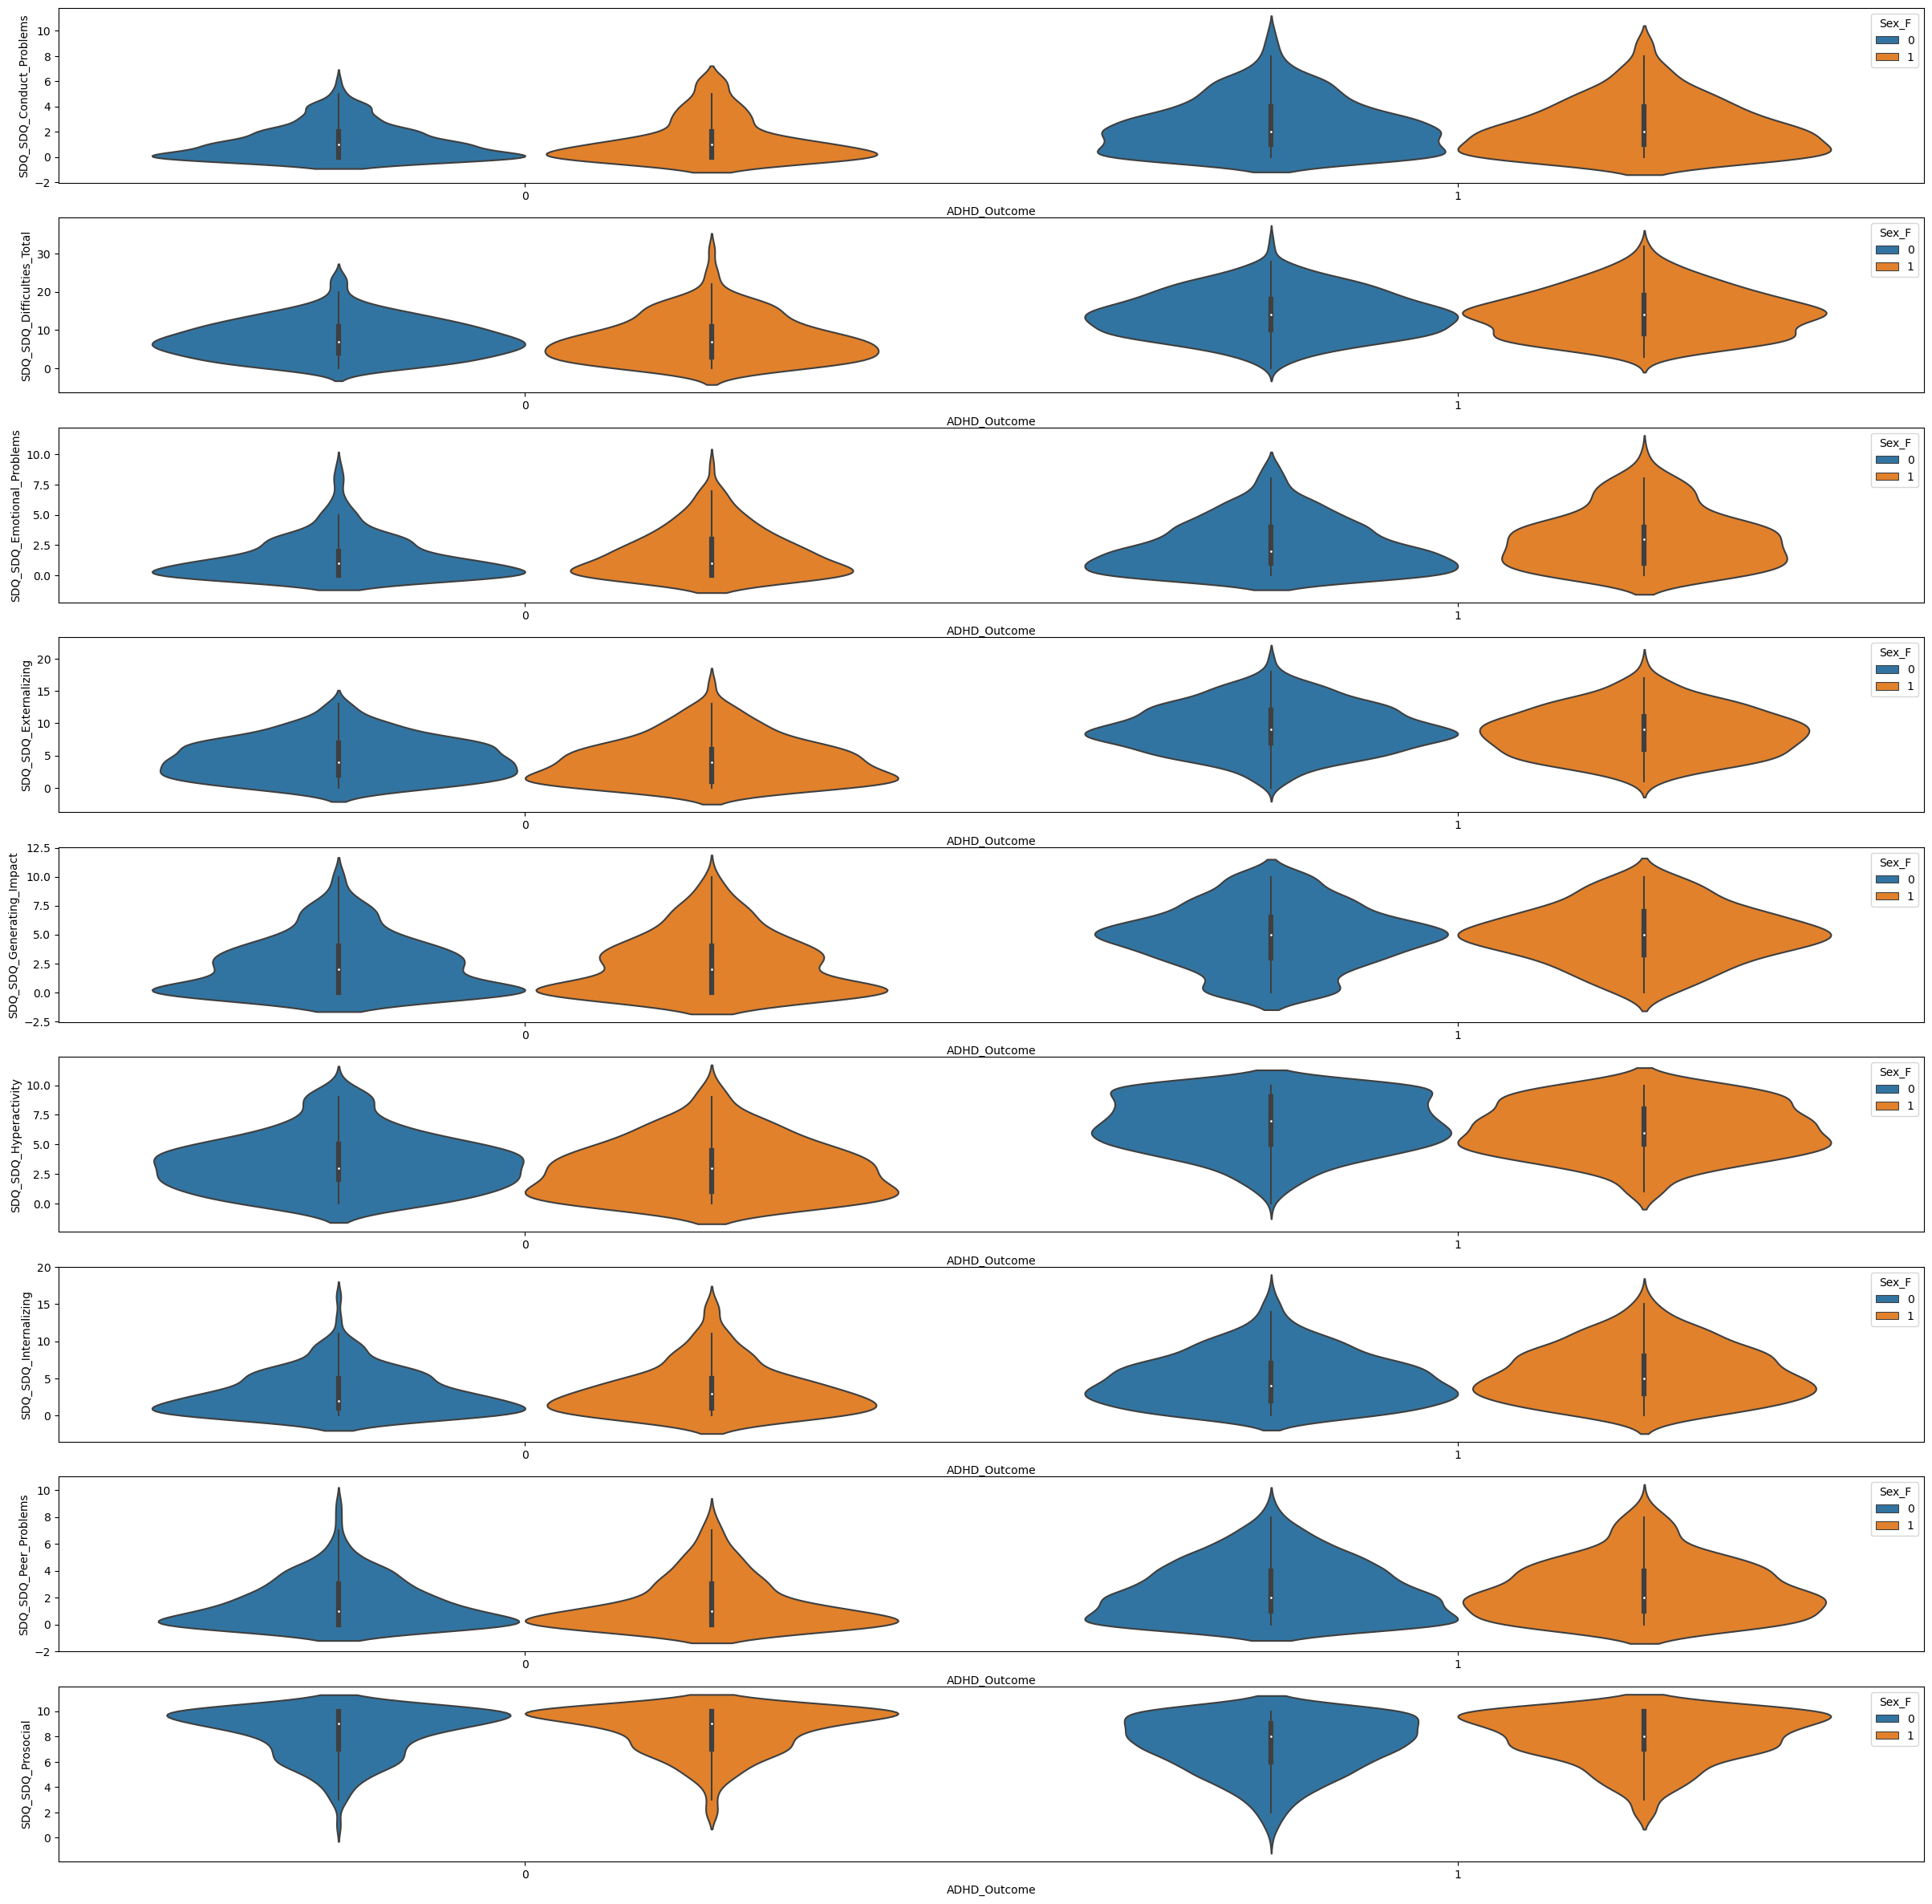

In [37]:
fig, axes = plt.subplots(nrows=9 ,ncols=1, figsize=(30, 30))
sns.violinplot(y = 'SDQ_SDQ_Conduct_Problems', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[0])
sns.violinplot(y = 'SDQ_SDQ_Difficulties_Total', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[1])
sns.violinplot(y = 'SDQ_SDQ_Emotional_Problems', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[2])
sns.violinplot(y = 'SDQ_SDQ_Externalizing', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[3])
sns.violinplot(y = 'SDQ_SDQ_Generating_Impact', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[4])
sns.violinplot(y = 'SDQ_SDQ_Hyperactivity', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[5])
sns.violinplot(y = 'SDQ_SDQ_Internalizing', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[6])
sns.violinplot(y = 'SDQ_SDQ_Peer_Problems', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[7])
sns.violinplot(y = 'SDQ_SDQ_Prosocial', x = 'ADHD_Outcome', orient='v', hue='Sex_F',data = df, ax=axes[8])

#axes[0].set_xlabel('SDQ_SDQ_Conduct_Problems', fontsize=8)


- В целом по всем графикам видна, что чем выше балл по поведенческой шкале, то тем вероятнее, будет СДВГ. Кроме просоциального поведения там обратная зависимость
- По графику с поведением видно, что в отличии о мальчиков, у девочек чуть менее есть зависимость СДВГ от проблем с поведением, хотя тоже есть
- Девочки с СДВГ имеют чаще эмоциональные проблемы, чем мальчики с СДВГ
- Гипотеза подтвердилась СДВГ зависит от подведения и эмоционального состояния ребенка

## 7 Гипотеза

- Родительский стиль воспитания связан с СДВГ у девочек

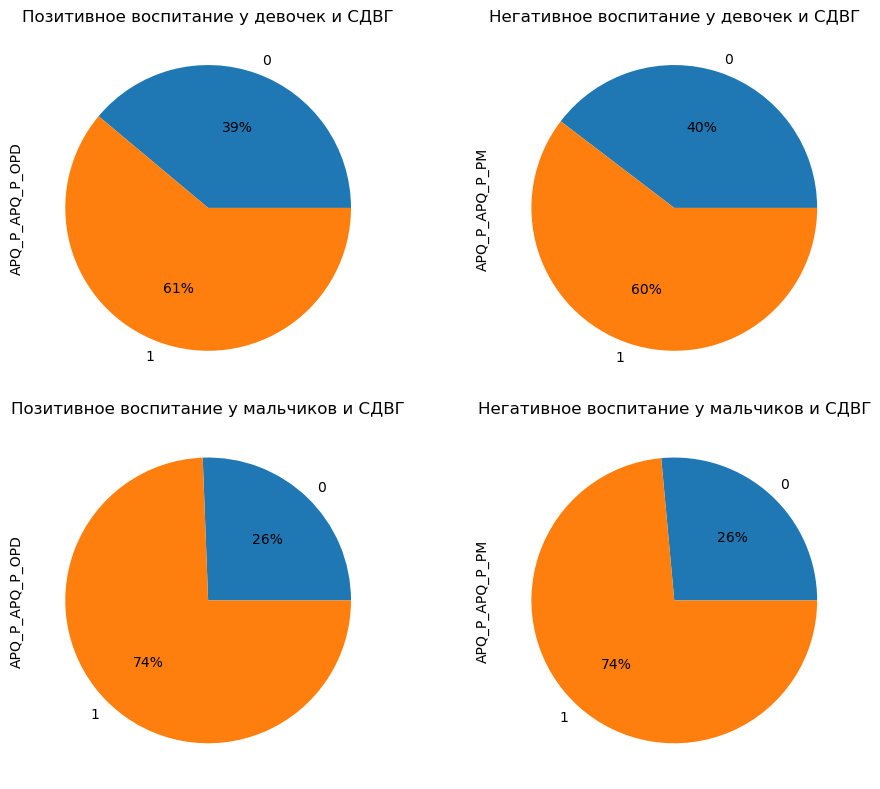

In [11]:
fig, axes = plt.subplots(nrows=2 ,ncols=2, figsize=(10, 8))
df[df['Sex_F'] == '1'].groupby('ADHD_Outcome')['APQ_P_APQ_P_OPD'].sum().plot(
    kind='pie', autopct='%1.0f%%', ax=axes[0, 0]) 
df[df['Sex_F'] == '1'].groupby('ADHD_Outcome')['APQ_P_APQ_P_PM'].sum().plot(
    kind='pie', autopct='%1.0f%%', ax=axes[0, 1]) 
df[df['Sex_F'] == '0'].groupby('ADHD_Outcome')['APQ_P_APQ_P_OPD'].sum().plot(
    kind='pie', autopct='%1.0f%%', ax=axes[1, 0]) 
df[df['Sex_F'] == '0'].groupby('ADHD_Outcome')['APQ_P_APQ_P_PM'].sum().plot(
    kind='pie', autopct='%1.0f%%', ax=axes[1, 1]) 

axes[0, 0].set_title('Позитивное воспитание у девочек и СДВГ')
axes[0, 1].set_title('Негативное воспитание у девочек и СДВГ')
axes[1, 0].set_title('Позитивное воспитание у мальчиков и СДВГ')
axes[1, 1].set_title('Негативное воспитание у мальчиков и СДВГ')

plt.tight_layout()
plt.show()

- Разница воспитания влияет на СДВГ совсем немного у девочек, на 1%, с негативнм воспитанием СДВГ встречается чаще
- У мальчиков никак не влияет стиль воспитание на СДВГ 
- Гипотеза частично подтвердилась

In [212]:
df.head()

,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,EHQ_EHQ_Total,...,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan,ADHD_Outcome,Sex_F
0,2019,4,1.0,0.0,3.0,21.0,45.0,-1.0,-1.0,100.00,...,4.0,11.0,5.0,8.0,6.0,2.0,9.0,14.274127,1,0
1,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0,92.27,...,4.0,13.0,5.0,8.0,7.0,3.0,8.0,-1.000000,1,0
2,2017,1,1.0,2.0,2.0,9.0,0.0,-1.0,-1.0,86.67,...,7.0,10.0,10.0,7.0,14.0,7.0,7.0,13.463381,0,1
3,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0,93.34,...,0.0,3.0,0.0,3.0,2.0,2.0,6.0,9.572553,0,1
4,2018,1,0.0,1.0,2.0,12.0,0.0,-1.0,-1.0,0.00,...,7.0,15.0,8.0,9.0,8.0,1.0,4.0,6.654574,1,0


## 8 Гипотеза

- Раса влиет на вероятность СДВГ у девочек

In [17]:
df["ADHD_Outcome"] = df["ADHD_Outcome"].astype(str) 
df["Sex_F"] = df["Sex_F"].astype(str) 
df["PreInt_Demos_Fam_Child_Race"] = df["PreInt_Demos_Fam_Child_Race"].astype(str) 

In [78]:
df_test["PreInt_Demos_Fam_Child_Race"] = df_test["PreInt_Demos_Fam_Child_Race"].astype(str) 

- 0= Белые/европеоиды
- 1= Чернокожие/афроамериканцы
- 2= Латиноамериканцы
- 3= Азиаты
- 4= Индийцы
- 5= Коренные американские индийцы
- 6= Американские индийцы/уроженцы Аляски
- 7= Коренные гавайцы/жители других тихоокеанских островов
- 8= Представители двух или более рас
- 9= Другая раса
- 10= Неизвестно
- 11= Предпочитаете не указывать

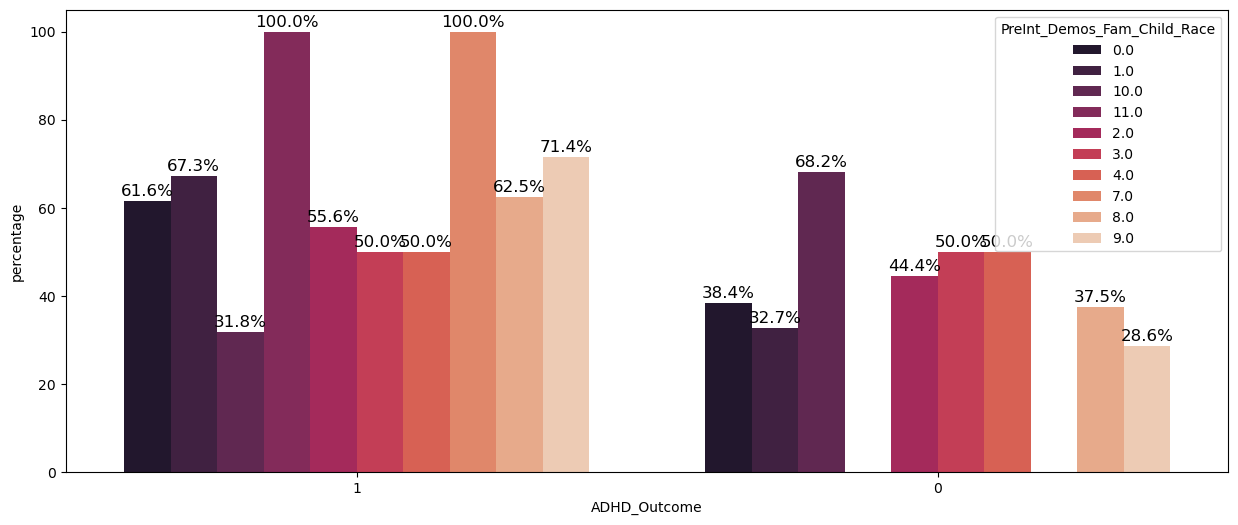

In [19]:
barplot_group(df[df['Sex_F'] == '1'], "ADHD_Outcome", "PreInt_Demos_Fam_Child_Race", 'Education-Default')

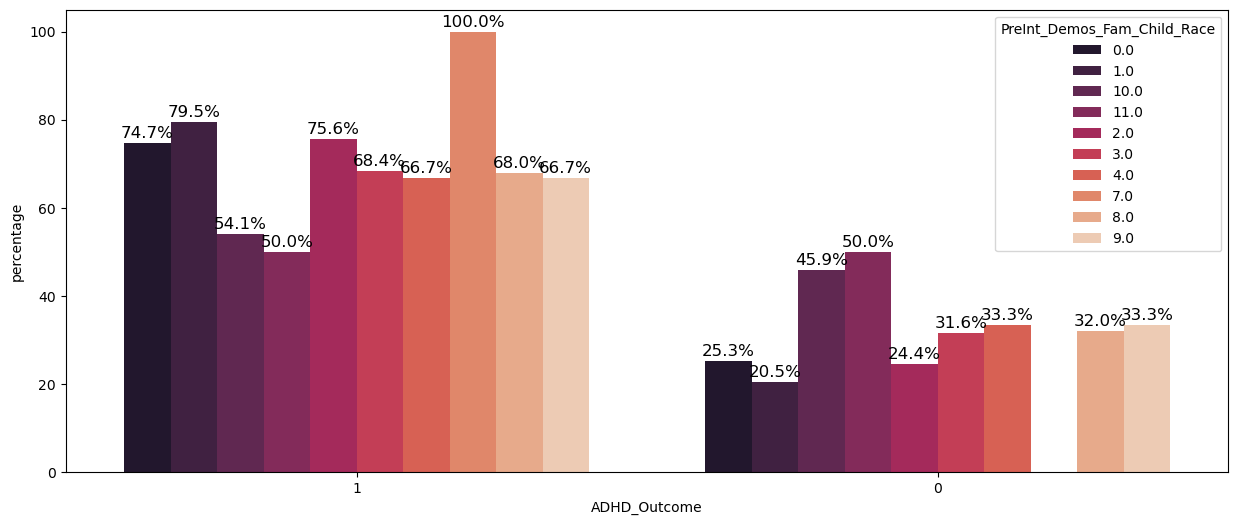

In [20]:
barplot_group(df[df['Sex_F'] == '0'], "ADHD_Outcome", "PreInt_Demos_Fam_Child_Race", 'Education-Default')

- У мальчиков мы видим, что большинства, кто имеет СДВГ, негроидная раса, на втором месте европиоиды.
- У девочек первое место такое же, негроидная раса, но вот второе уже латиноамериканцы и только потом европиоиды.
- Гипотеза подтвердилась зависимость от расы есть и немного отличается у мальчиков и у девочек.

## 9 Гипотеза

- Гиперактивность больше связана с СДВГ у мальчиков, а у девочек по большей части СДВ

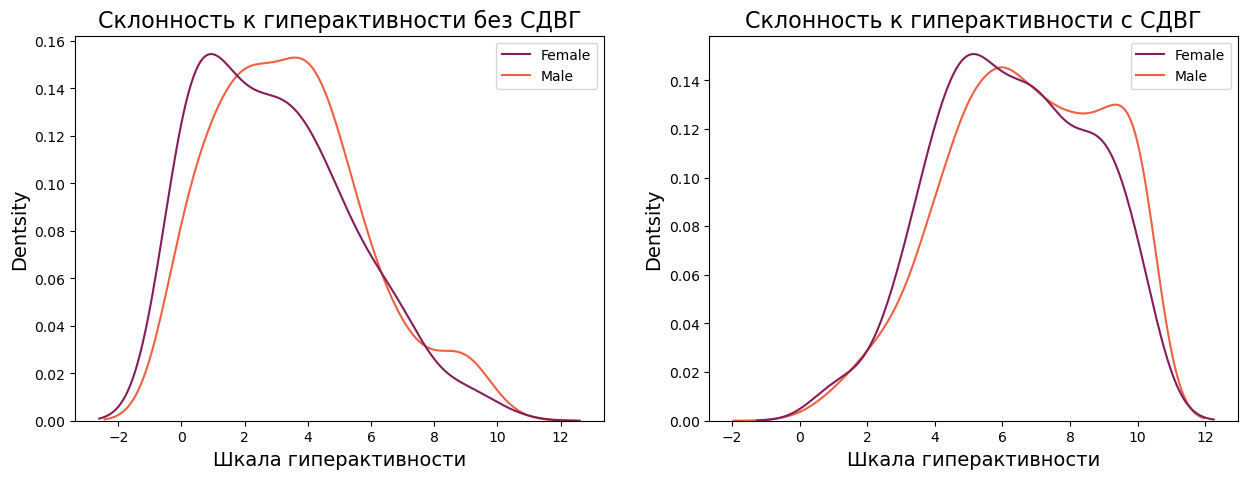

In [23]:
fig, axes = plt.subplots(ncols=2, figsize=(15, 5))

sns.kdeplot(
    data={
        "Female": df_0[df_0.Sex_F == '1'].SDQ_SDQ_Hyperactivity,
        "Male": df_0[df_0.Sex_F == '0'].SDQ_SDQ_Hyperactivity 
    },
    common_norm=False,
    palette='rocket',
    ax=axes[0]
    )
axes[0].set_title('Склонность к гиперактивности без СДВГ', fontsize=16)
axes[0].set_xlabel('Шкала гиперактивности', fontsize=14)
axes[0].set_ylabel('Dentsity', fontsize=14)

sns.kdeplot(
    data={
        "Female": df_1[df_1.Sex_F == '1'].SDQ_SDQ_Hyperactivity,
        "Male": df_1[df_1.Sex_F == '0'].SDQ_SDQ_Hyperactivity
    },
    common_norm=False,
    palette='rocket',
    ax=axes[1]
    )
axes[1].set_title('Склонность к гиперактивности с СДВГ', fontsize=16)
axes[1].set_xlabel('Шкала гиперактивности', fontsize=14)
axes[1].set_ylabel('Dentsity', fontsize=14)
plt.show()

- Гиперактивность у мальчиков в любом случае больше, чем у девочек, несмотря на то, есть ли СДВГ у ребенка или нет
- Гипотеза больше не подтвердилась, гиперактивность при СДВГ, очень похоже у девочек с мальчиками 

## 10 Гипотеза

- На СДВГ у девочек влияет количество родителей в семье

In [65]:
df['One_parent'] = np.where((df['Barratt_Barratt_P2_Edu'] == -1) & (df['Barratt_Barratt_P2_Occ'] == -1), '0', '1')

In [79]:
df_test['One_parent'] = np.where((df_test['Barratt_Barratt_P2_Edu'] == -1) & (df_test['Barratt_Barratt_P2_Occ'] == -1), '0', '1')

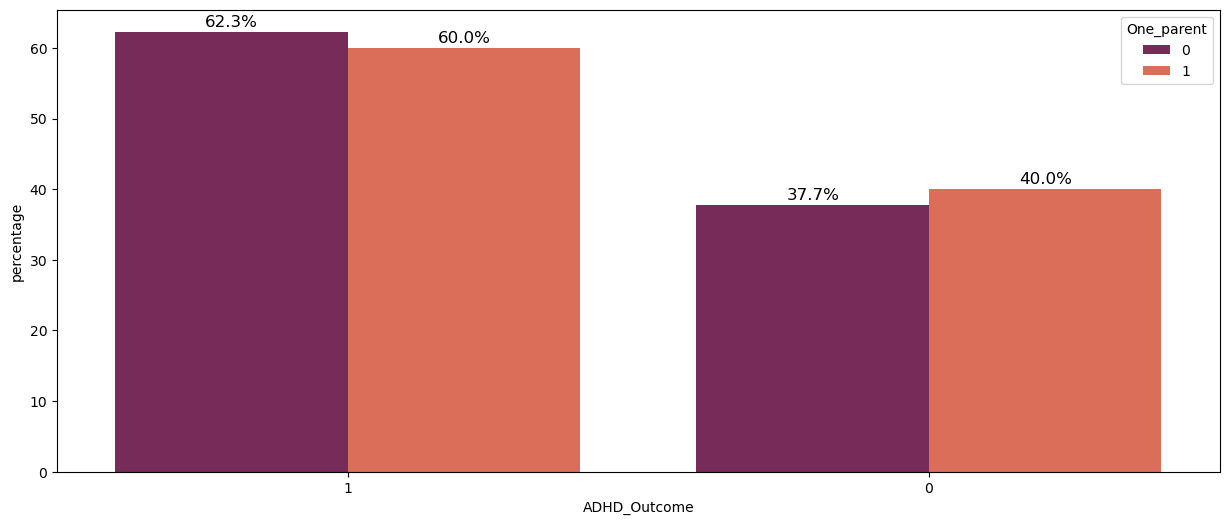

In [54]:
barplot_group(df[df['Sex_F'] == '1'], "ADHD_Outcome", "One_parent", 'ADHD-Parents')

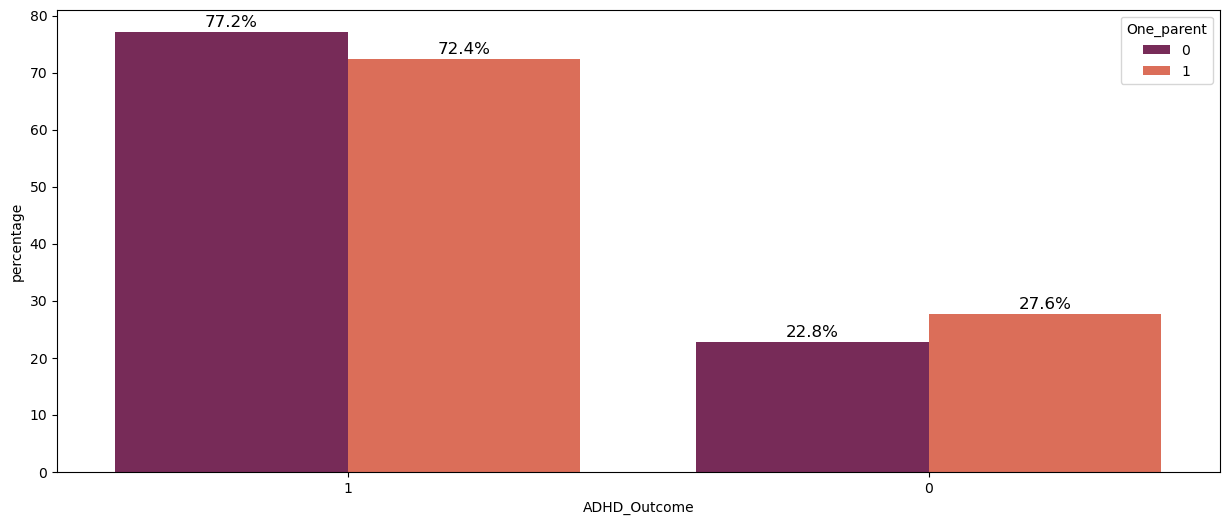

In [55]:
barplot_group(df[df['Sex_F'] == '0'], "ADHD_Outcome", "One_parent", 'ADHD-Parents')

- У детей у которых есть только один родитель, вероятность СДВГ выше
- У девочек выше на 2,3 %
- У мальчиков выше на 4,8 %
- Гипотеза подтвердилась

In [67]:
#Объединим с датафреймы: этот обработанный и с результатами МРТ
df_CONNECTOME = pd.read_csv('TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv')

In [80]:
df_CONNECTOME_test = pd.read_csv('TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv')

In [81]:
df_full_test = df_test.merge(df_CONNECTOME_test, on="participant_id")

In [70]:
df_full = df.merge(df_CONNECTOME, on="participant_id")

In [72]:
df_full.to_csv("df_full.csv", index=False)

In [82]:
df_full_test.to_csv("df_full_test.csv", index=False)

# Выводы

- Пол влияет на диагностирование СДВГ, у мальчиков чаще диагностируюется на 12,8%
- Большим влиянием на диагностирование СДВГ у любого пола являются эмоционально/поведенческие признаки: Гиперактивность, экстернализация, общая сложность ребенка, насколько проблемы влияют на жизнь, проблемы в поведении, интернализация, дисциплина
- Стиль воспитания практически никак не влияет на СДВГ у девочек
- Раса ребенка влияет на СДВГ, самыё большой процент отводится негроидной расе, а самый маленький индийцам
- Влияение на количество родителей в семье тоже есть, при наличии только одного родителя повышаются шансы иметь СДВГ (сильнее у мальчиков)
- Гиперактивность влияет на вероятность СДВГ, но у девочек немного меньше, чем у мальчиков (небольшая разница)